In [1]:
import logging

import numpy as np
import optimistix as optx
import matplotlib.pyplot as plt

from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

logger = debug_logger()
logger.setLevel(logging.INFO)
# For more output use DEBUG
# logger.setLevel(logging.DEBUG)

Atmodeller initialized with double precision (float64)


# Sub-Neptune (e.g. K2-18b) models from Bower et al. (2025)

The code blocks below must always be run, but then you can preferentially run only the models for ideal or real gases.

Parameters for the simulations

In [2]:
number_of_realisations = 500
surface_temperature = 3000.0  # K

# For simulations with fixed mass and surface radius:
planet_mass = 5.154e25
surface_radius = 1.1225e7  # using M-R relation from Hakim+2018
mantle_melt_fraction = 1.0  # 0.1

RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)

In [3]:
solubility_models = get_solubility_models()

H2O_g = Species.create_gas("H2O", solubility=solubility_models["H2O_basalt_dixon95"])
H2_g = Species.create_gas("H2", solubility=solubility_models["H2_basalt_hirschmann12"])
O2_g = Species.create_gas("O2")
CO_g = Species.create_gas("CO", solubility=solubility_models["CO_basalt_yoshioka19"])
CO2_g = Species.create_gas("CO2", solubility=solubility_models["CO2_basalt_dixon95"])
CH4_g = Species.create_gas("CH4", solubility=solubility_models["CH4_basalt_ardia13"])

idealspecies_withsols = SpeciesCollection((H2O_g, H2_g, O2_g, CO_g, CO2_g, CH4_g))

In [4]:
eos_models = get_eos_models()

H2O_rg = Species.create_gas(
    "H2O",
    activity=eos_models["H2O_cork_holland98"],
    solubility=solubility_models["H2O_basalt_dixon95"],
)
H2_rg = Species.create_gas(
    "H2",
    activity=eos_models["H2_chabrier21"],
    solubility=solubility_models["H2_basalt_hirschmann12"],
)
O2_rg = Species.create_gas("O2")
CO_rg = Species.create_gas(
    "CO",
    activity=eos_models["CO_cs_shi92"],
    solubility=solubility_models["CO_basalt_yoshioka19"],
)
CO2_rg = Species.create_gas(
    "CO2",
    activity=eos_models["CO2_cs_shi92"],
    solubility=solubility_models["CO2_basalt_dixon95"],
)
CH4_rg = Species.create_gas(
    "CH4",
    activity=eos_models["CH4_cs_shi92"],
    solubility=solubility_models["CH4_basalt_ardia13"],
)

realspecies_withsols = SpeciesCollection((H2O_rg, H2_rg, O2_rg, CO_rg, CO2_rg, CH4_rg))

## Vary Hydrogen Mass Fraction

Hydrogen mass fraction varies from 0.1 to 3% of K2-18b's mass

In [5]:
# Vary Linearly:

log10_H_frac = np.linspace(-1.0, 0.5, number_of_realisations)  # 0.1 to 3% of planet mass

# Fix Values for Linearly Varying Cases:
log10_ch_ratios = np.full(number_of_realisations, -0.5)  # 100X Solar
fO2_log10_shifts = np.full(number_of_realisations, -3)

h_kg = ((10**log10_H_frac) / 100) * planet_mass
c_kg = h_kg * 10**log10_ch_ratios

mass_constraints = {
    "H": h_kg,
    "C": c_kg,
}

In [6]:
sub_neptune = Planet(
    surface_temperature=surface_temperature,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=mantle_melt_fraction,
)

### Ideal gas with solubilities

In [7]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_ideal_varyHF_withsol = InteriorAtmosphere(idealspecies_withsols)

fugacity_constraints = {O2_g.name: IronWustiteBuffer(fO2_log10_shifts)}

model_ideal_varyHF_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
)
output_ideal_varyHF_withsol = model_ideal_varyHF_withsol.output

# Write the complete solution to Excel
output_ideal_varyHF_withsol.to_excel("sub_neptune_ideal_withsol_varyHF")

# Write the data to a pickle file with dataframes
output_ideal_varyHF_withsol.to_pickle("sub_neptune_ideal_withsol_varyHF")

[22:49:04 - atmodeller.classes             - INFO     ] - species = ('H2O_g: IdealGas, SolubilityPowerLaw', 'H2_g: IdealGas, SolubilityPowerLawLog10', 'O2_g: IdealGas, NoSolubility', 'CO_g: IdealGas, _CO_basalt_yoshioka19', 'CO2_g: IdealGas, _CO2_basalt_dixon95', 'CH4_g: IdealGas, _CH4_basalt_ardia13')
[22:49:04 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[22:49:04 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[22:49:04 - atmodeller.classes             - INFO     ] - Attempting to solve 500 model(s)
[22:49:07 - atmodeller.classes             - INFO     ] - Solve complete: 500 (100.00%) successful model(s)
[22:49:07 - atmodeller.classes             - INFO     ] - Solver steps (max) = 41
[22:49:07 - atmodeller.output              - INFO     ] - Writing output to excel
[22:49:07 -

### Real gas with solubility

In [8]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_real_varyHF_withsol = InteriorAtmosphere(realspecies_withsols)

fugacity_constraints = {O2_rg.name: IronWustiteBuffer(fO2_log10_shifts)}

model_real_varyHF_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    # Use the ideal solution for the initial guess of the real case
    initial_log_number_density=output_ideal_varyHF_withsol.log_number_density,
    solver_parameters=solver_parameters,
)
output_real_varyHF_withsol = model_real_varyHF_withsol.output

# Write the complete solution to Excel
output_real_varyHF_withsol.to_excel("sub_neptune_real_withsol_varyHF")

# Write the data to a pickle file with dataframes
output_real_varyHF_withsol.to_pickle("sub_neptune_real_withsol_varyHF")

[22:49:10 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: IdealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13')
[22:49:10 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[22:49:10 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[22:49:10 - atmodeller.classes             - INFO     ] - Attempting to solve 500 model(s)
[22:49:34 - atmodeller.classes             - INFO     ] - Solve complete: 500 (100.00%) successful model(s)
[22:49:34 - atmodeller.classes             - INFO     ] - Solver steps (max) = 30
[22:49:34 - atmodeller.output              - INFO     ] - 

## Vary Oxygen Fugacity

fO2 varies from IW-6 to IW

In [9]:
# Vary Linearly:
fO2_log10_shifts = np.linspace(-6, 0, number_of_realisations)  # IW-6 to IW


# Fix Values for Linearly Varying Cases:
log10_H_frac = np.full(number_of_realisations, 0)  # 1% of planet mass
log10_ch_ratios = np.full(number_of_realisations, -0.5)  # 100X Solar

h_kg = ((10**log10_H_frac) / 100) * planet_mass
c_kg = h_kg * 10**log10_ch_ratios

mass_constraints = {
    "H": h_kg,
    "C": c_kg,
}

In [10]:
sub_neptune = Planet(
    surface_temperature=surface_temperature,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=mantle_melt_fraction,
)

### Ideal gas with solubility

In [11]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_ideal_varyfO2_withsol = InteriorAtmosphere(idealspecies_withsols)

fugacity_constraints = {O2_g.name: IronWustiteBuffer(fO2_log10_shifts)}

model_ideal_varyfO2_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
)
output_ideal_varyfO2_withsol = model_ideal_varyfO2_withsol.output

# Write the complete solution to Excel
output_ideal_varyfO2_withsol.to_excel("sub_neptune_ideal_withsol_varyfO2")

# Write the data to a pickle file with dataframes
output_ideal_varyfO2_withsol.to_pickle("sub_neptune_ideal_withsol_varyfO2")

[22:49:37 - atmodeller.classes             - INFO     ] - species = ('H2O_g: IdealGas, SolubilityPowerLaw', 'H2_g: IdealGas, SolubilityPowerLawLog10', 'O2_g: IdealGas, NoSolubility', 'CO_g: IdealGas, _CO_basalt_yoshioka19', 'CO2_g: IdealGas, _CO2_basalt_dixon95', 'CH4_g: IdealGas, _CH4_basalt_ardia13')
[22:49:37 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[22:49:37 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[22:49:37 - atmodeller.classes             - INFO     ] - Attempting to solve 500 model(s)
[22:49:37 - atmodeller.classes             - INFO     ] - Solve complete: 500 (100.00%) successful model(s)
[22:49:37 - atmodeller.classes             - INFO     ] - Solver steps (max) = 41
[22:49:37 - atmodeller.output              - INFO     ] - Writing output to excel
[22:49:37 -

### Real gas with solubility

In [12]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_real_varyfO2_withsol = InteriorAtmosphere(realspecies_withsols)

fugacity_constraints = {O2_rg.name: IronWustiteBuffer(fO2_log10_shifts)}

model_real_varyfO2_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
    # Use the ideal solution for the initial guess of the real case
    initial_log_number_density=output_ideal_varyfO2_withsol.log_number_density,
)
output_real_varyfO2_withsol = model_real_varyfO2_withsol.output

# Write the complete solution to Excel
output_real_varyfO2_withsol.to_excel("sub_neptune_real_withsol_varyfO2")

# Write the data to a pickle file with dataframes
output_real_varyfO2_withsol.to_pickle("sub_neptune_real_withsol_varyfO2")

[22:49:38 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: IdealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13')
[22:49:38 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[22:49:38 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[22:49:38 - atmodeller.classes             - INFO     ] - Attempting to solve 500 model(s)
[22:49:40 - atmodeller.classes             - INFO     ] - Solve complete: 500 (100.00%) successful model(s)
[22:49:40 - atmodeller.classes             - INFO     ] - Solver steps (max) = 21
[22:49:40 - atmodeller.output              - INFO     ] - 

## Vary C/H Ratio

C/H ratio varies from that of solar (log10(C/H) = -2.5) to bulk silicate Earth (log10(C/H)=0.1)

In [13]:
# Vary Linearly:
log10_ch_ratios = np.linspace(-2.5, 0.1, number_of_realisations)  # Solar to BSE Ratios


# Fix Values for Linearly Varying Cases:
log10_H_frac = np.full(number_of_realisations, 0)  # 1% of planet mass
fO2_log10_shifts = np.full(number_of_realisations, -3)

h_kg = ((10**log10_H_frac) / 100) * planet_mass
c_kg = h_kg * 10**log10_ch_ratios

mass_constraints = {
    "H": h_kg,
    "C": c_kg,
}

In [14]:
sub_neptune = Planet(
    surface_temperature=surface_temperature,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=mantle_melt_fraction,
)

### Ideal gas with solubility

In [15]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_ideal_varyCtoH_withsol = InteriorAtmosphere(idealspecies_withsols)

fugacity_constraints = {O2_g.name: IronWustiteBuffer(fO2_log10_shifts)}

model_ideal_varyCtoH_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
)
output_ideal_varyCtoH_withsol = model_ideal_varyCtoH_withsol.output

# Write the complete solution to Excel
output_ideal_varyCtoH_withsol.to_excel("sub_neptune_ideal_withsol_varyCtoH")

# Write the data to a pickle file with dataframes
output_ideal_varyCtoH_withsol.to_pickle("sub_neptune_ideal_withsol_varyCtoH")

[22:49:41 - atmodeller.classes             - INFO     ] - species = ('H2O_g: IdealGas, SolubilityPowerLaw', 'H2_g: IdealGas, SolubilityPowerLawLog10', 'O2_g: IdealGas, NoSolubility', 'CO_g: IdealGas, _CO_basalt_yoshioka19', 'CO2_g: IdealGas, _CO2_basalt_dixon95', 'CH4_g: IdealGas, _CH4_basalt_ardia13')
[22:49:41 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[22:49:41 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[22:49:41 - atmodeller.classes             - INFO     ] - Attempting to solve 500 model(s)
[22:49:41 - atmodeller.classes             - INFO     ] - Solve complete: 500 (100.00%) successful model(s)
[22:49:41 - atmodeller.classes             - INFO     ] - Solver steps (max) = 36
[22:49:41 - atmodeller.output              - INFO     ] - Writing output to excel
[22:49:41 -

### Real gas with solubility

In [16]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_real_varyCtoH_withsol = InteriorAtmosphere(realspecies_withsols)

fugacity_constraints = {O2_rg.name: IronWustiteBuffer(fO2_log10_shifts)}

model_real_varyCtoH_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
    # Use the ideal solution for the initial guess of the real case
    initial_log_number_density=output_ideal_varyCtoH_withsol.log_number_density,
)
output_real_varyCtoH_withsol = model_real_varyCtoH_withsol.output

# Write the complete solution to Excel
output_real_varyCtoH_withsol.to_excel("sub_neptune_real_withsol_varyCtoH")

# Write the data to a pickle file with dataframes
output_real_varyCtoH_withsol.to_pickle("sub_neptune_real_withsol_varyCtoH")

[22:49:43 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: IdealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13')
[22:49:43 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[22:49:43 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[22:49:43 - atmodeller.classes             - INFO     ] - Attempting to solve 500 model(s)
[22:49:44 - atmodeller.classes             - INFO     ] - Solve complete: 500 (100.00%) successful model(s)
[22:49:44 - atmodeller.classes             - INFO     ] - Solver steps (max) = 18
[22:49:44 - atmodeller.output              - INFO     ] - 

## Vary Planetary Surface Radius

Surface radius varies from 1.76 to 2.6 REarth, planet mass is fixed at 8.63 MEarth

In [17]:
# For simulations with varying surface radius:
surface_radius = np.linspace(1.1225e7, 1.6647e7, number_of_realisations)  # Vary linearly

# Fix Values for Linearly Varying Cases:
log10_H_frac = np.full(
    number_of_realisations, 0.5
)  # ~3% of planet mass, used for fix Surf Radius and Planet Mass cases
log10_ch_ratios = np.full(number_of_realisations, -0.5)  # 100X Solar
fO2_log10_shifts = np.full(number_of_realisations, -3)

h_kg = ((10**log10_H_frac) / 100) * planet_mass
c_kg = h_kg * 10**log10_ch_ratios

mass_constraints = {
    "H": h_kg,
    "C": c_kg,
}

In [18]:
sub_neptune = Planet(
    surface_temperature=surface_temperature,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=mantle_melt_fraction,
)

### Ideal gas with solubility

In [19]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_ideal_varyRsurf_withsol = InteriorAtmosphere(idealspecies_withsols)

fugacity_constraints = {O2_g.name: IronWustiteBuffer(fO2_log10_shifts)}

model_ideal_varyRsurf_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
)
output_ideal_varyRsurf_withsol = model_ideal_varyRsurf_withsol.output

# Write the complete solution to Excel
output_ideal_varyRsurf_withsol.to_excel("sub_neptune_ideal_withsol_varyRsurf")

# Write the data to a pickle file with dataframes
output_ideal_varyRsurf_withsol.to_pickle("sub_neptune_ideal_withsol_varyRsurf")

[22:49:46 - atmodeller.classes             - INFO     ] - species = ('H2O_g: IdealGas, SolubilityPowerLaw', 'H2_g: IdealGas, SolubilityPowerLawLog10', 'O2_g: IdealGas, NoSolubility', 'CO_g: IdealGas, _CO_basalt_yoshioka19', 'CO2_g: IdealGas, _CO2_basalt_dixon95', 'CH4_g: IdealGas, _CH4_basalt_ardia13')
[22:49:46 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[22:49:46 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[22:49:46 - atmodeller.classes             - INFO     ] - Attempting to solve 500 model(s)
[22:49:48 - atmodeller.classes             - INFO     ] - Solve complete: 500 (100.00%) successful model(s)
[22:49:48 - atmodeller.classes             - INFO     ] - Solver steps (max) = 41
[22:49:48 - atmodeller.output              - INFO     ] - Writing output to excel
[22:49:48 -

### Real gas with solubility

In [20]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_real_varyRsurf_withsol = InteriorAtmosphere(realspecies_withsols)

fugacity_constraints = {O2_rg.name: IronWustiteBuffer(fO2_log10_shifts)}

model_real_varyRsurf_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
    # Use the ideal solution for the initial guess of the real case
    initial_log_number_density=output_ideal_varyRsurf_withsol.log_number_density,
)
output_real_varyRsurf_withsol = model_real_varyRsurf_withsol.output

# Write the complete solution to Excel
output_real_varyRsurf_withsol.to_excel("sub_neptune_real_withsol_varyRsurf")

# Write the data to a pickle file with dataframes
output_real_varyRsurf_withsol.to_pickle("sub_neptune_real_withsol_varyRsurf")

[22:49:49 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: IdealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13')
[22:49:49 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[22:49:49 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[22:49:49 - atmodeller.classes             - INFO     ] - Attempting to solve 500 model(s)
[22:50:11 - atmodeller.classes             - INFO     ] - Solve complete: 500 (100.00%) successful model(s)
[22:50:11 - atmodeller.classes             - INFO     ] - Solver steps (max) = 30
[22:50:11 - atmodeller.output              - INFO     ] - 

## Vary Planetary Mass

Planet mass varies from 4 to 9 MEarth, surface radius is fixed at 1.76 REarth

In [21]:
surface_radius = 1.1225e7  # using M-R relation from Hakim+2018


# For simulations with varying planet mass:

planet_mass_Earths = np.linspace(4, 9, number_of_realisations)  # Vary linearly from 4-9 MEarth
planet_mass = planet_mass_Earths * 5.9722e24


# Fix Values for Linearly Varying Cases:
log10_H_frac = np.full(
    number_of_realisations, 0.5
)  # ~3% of planet mass, used for fix Surf Radius and Planet Mass cases
log10_ch_ratios = np.full(number_of_realisations, -0.5)  # 100X Solar
fO2_log10_shifts = np.full(number_of_realisations, -3)

h_kg = ((10**log10_H_frac) / 100) * planet_mass
c_kg = h_kg * 10**log10_ch_ratios

mass_constraints = {
    "H": h_kg,
    "C": c_kg,
}

In [22]:
sub_neptune = Planet(
    surface_temperature=surface_temperature,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=mantle_melt_fraction,
)

### Ideal gas with solubility

In [23]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_ideal_varyMp_withsol = InteriorAtmosphere(idealspecies_withsols)

fugacity_constraints = {O2_g.name: IronWustiteBuffer(fO2_log10_shifts)}

model_ideal_varyMp_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
)
output_ideal_varyMp_withsol = model_ideal_varyMp_withsol.output

# Write the complete solution to Excel
output_ideal_varyMp_withsol.to_excel("sub_neptune_ideal_withsol_varyMp")

# Write the data to a pickle file with dataframes
output_ideal_varyMp_withsol.to_pickle("sub_neptune_ideal_withsol_varyMp")

[22:50:12 - atmodeller.classes             - INFO     ] - species = ('H2O_g: IdealGas, SolubilityPowerLaw', 'H2_g: IdealGas, SolubilityPowerLawLog10', 'O2_g: IdealGas, NoSolubility', 'CO_g: IdealGas, _CO_basalt_yoshioka19', 'CO2_g: IdealGas, _CO2_basalt_dixon95', 'CH4_g: IdealGas, _CH4_basalt_ardia13')
[22:50:12 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[22:50:12 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[22:50:12 - atmodeller.classes             - INFO     ] - Attempting to solve 500 model(s)
[22:50:14 - atmodeller.classes             - INFO     ] - Solve complete: 500 (100.00%) successful model(s)
[22:50:14 - atmodeller.classes             - INFO     ] - Solver steps (max) = 41
[22:50:14 - atmodeller.output              - INFO     ] - Writing output to excel
[22:50:14 -

### Real gas with solubility

In [24]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_real_varyMp_withsol = InteriorAtmosphere(realspecies_withsols)

fugacity_constraints = {O2_rg.name: IronWustiteBuffer(fO2_log10_shifts)}

model_real_varyMp_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
    # Use the ideal solution for the initial guess of the real case
    initial_log_number_density=output_ideal_varyMp_withsol.log_number_density,
)
output_real_varyMp_withsol = model_real_varyMp_withsol.output

# Write the complete solution to Excel
output_real_varyMp_withsol.to_excel("sub_neptune_real_withsol_varyMp")

# Write the data to a pickle file with dataframes
output_real_varyMp_withsol.to_pickle("sub_neptune_real_withsol_varyMp")

[22:50:15 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: IdealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13')
[22:50:15 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[22:50:15 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[22:50:15 - atmodeller.classes             - INFO     ] - Attempting to solve 500 model(s)
[22:50:38 - atmodeller.classes             - INFO     ] - Solve complete: 500 (100.00%) successful model(s)
[22:50:38 - atmodeller.classes             - INFO     ] - Solver steps (max) = 30
[22:50:38 - atmodeller.output              - INFO     ] - 

In [25]:
# --- Based on the fugacity_crisis example, but varying planet mass instead of volatile fraction ---

surface_temperature = 3000.0  # K

eos_models = get_eos_models()
solubility_models = get_solubility_models()

H2_g = Species.create_gas(
    "H2",
    solubility=solubility_models["H2_kite19"],
    activity=eos_models["H2_chabrier21"],
)

species = SpeciesCollection((H2_g,))
model = InteriorAtmosphere(idealspecies_withsols)

# === THIS IS THE ONLY MAJOR CHANGE: vary planet mass instead of zeta_v ===
planet_mass_earth = np.linspace(1, 15, 100)        # 1–15 Earth masses
planet_mass = planet_mass_earth * 5.972e24         # kg

# keep surface temp and other parameters fixed
solver_parameters = SolverParameters(solver=optx.LevenbergMarquardt)

# we’ll fix the H-mass fraction so that larger planets get proportionally more gas
h_mass_fraction = 1e-2                             # 1% of total planet mass as H
mass_hydrogen = planet_mass * h_mass_fraction

model.solve(
    planet=Planet(
        planet_mass=planet_mass,
        core_mass_fraction=0.333,
        surface_temperature=surface_temperature,
    ),
    mass_constraints={"H": mass_hydrogen},
    solver_parameters=solver_parameters,
    initial_log_number_density=66.0,
)

output = model.output
output_df = output.to_dataframes()

# === Post-processing ===
pressure = output_df["atmosphere"]["pressure"]
pressure_GPa = pressure * 1e-4
fugacity_coefficient = output_df["H2_g"]["fugacity_coefficient"]
dissolved_ppmw = output_df["H2_g"]["dissolved_ppmw"]
dissolved_wtp = dissolved_ppmw * 1e-4
atmosphere_mass = output_df["H2_g"]["atmosphere_mass"]

[22:50:39 - atmodeller.classes             - INFO     ] - species = ('H2O_g: IdealGas, SolubilityPowerLaw', 'H2_g: IdealGas, SolubilityPowerLawLog10', 'O2_g: IdealGas, NoSolubility', 'CO_g: IdealGas, _CO_basalt_yoshioka19', 'CO2_g: IdealGas, _CO2_basalt_dixon95', 'CH4_g: IdealGas, _CH4_basalt_ardia13')
[22:50:39 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[22:50:39 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[22:50:39 - atmodeller.classes             - INFO     ] - Attempting to solve 100 model(s)
[22:50:43 - atmodeller.classes             - WARNING  ] - 100 model(s) failed to converge on the first attempt
[22:50:43 - atmodeller.classes             - WARNING  ] - But don't panic! This can happen when starting from a poor initial guess.
[22:50:43 - atmodeller.classes          

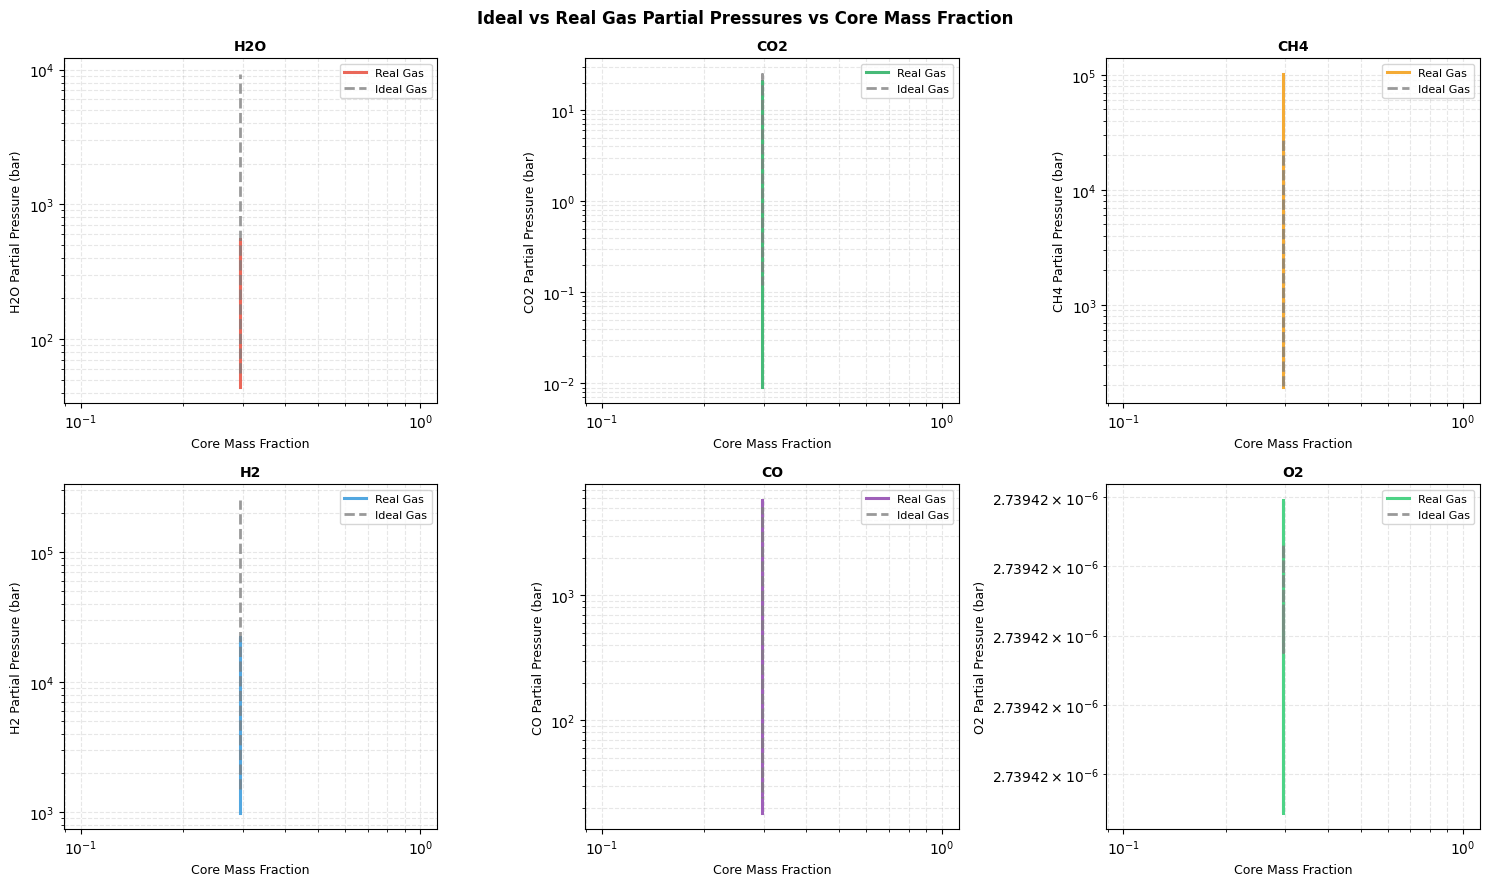

In [26]:
import pandas as pd
import matplotlib.pyplot as plt

# === File paths ===
ideal_file = 'sub_neptune_ideal_withsol_varyHF.xlsx'
real_file  = 'sub_neptune_real_withsol_varyHF.xlsx'

# === Load planet sheet (for x-axis) ===
planet_ideal = pd.read_excel(ideal_file, sheet_name='planet')
planet_real  = pd.read_excel(real_file,  sheet_name='planet')

# ✅ Use core_mass_fraction as x-axis (this one actually varies)
x_ideal = planet_ideal['core_mass_fraction']
x_real  = planet_real['core_mass_fraction']

# === Define species and colors ===
species = ['H2O_g', 'CO2_g', 'CH4_g', 'H2_g', 'CO_g', 'O2_g']
colors  = ['#E74C3C', '#27AE60', '#F39C12', '#3498DB', '#8E44AD', '#2ECC71']

# === Create figure ===
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, sp in enumerate(species):
    ax = axes[i]

    try:
        ideal_df = pd.read_excel(ideal_file, sheet_name=sp)
        real_df  = pd.read_excel(real_file,  sheet_name=sp)
    except ValueError:
        print(f"⚠️ Skipping {sp}: sheet not found.")
        fig.delaxes(ax)
        continue

    # Try to find a pressure column
    pressure_col = next((c for c in ideal_df.columns if 'press' in c.lower()), None)
    if not pressure_col:
        print(f"⚠️ Skipping {sp}: no pressure column found.")
        fig.delaxes(ax)
        continue

    y_ideal = ideal_df[pressure_col]
    y_real  = real_df[pressure_col]

    # === Plot ===
    ax.plot(x_real,  y_real, '-',  color=colors[i], lw=2.2, label='Real Gas', alpha=0.85)
    ax.plot(x_ideal, y_ideal, '--', color='gray',  lw=2,   label='Ideal Gas', alpha=0.8)

    ax.set_xscale('log')
    ax.set_yscale('log')

    ax.set_xlabel('Core Mass Fraction', fontsize=9)
    ax.set_ylabel(f'{sp.replace("_g", "")} Partial Pressure (bar)', fontsize=9)
    ax.set_title(sp.replace('_g', '').upper(), fontsize=10, fontweight='bold')
    ax.grid(True, alpha=0.3, linestyle='--', which='both')
    ax.legend(fontsize=8)

# Hide unused axes
for j in range(len(species), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Ideal vs Real Gas Partial Pressures vs Core Mass Fraction', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('ideal_vs_real_partial_pressures.png', dpi=300, bbox_inches='tight')
plt.show()


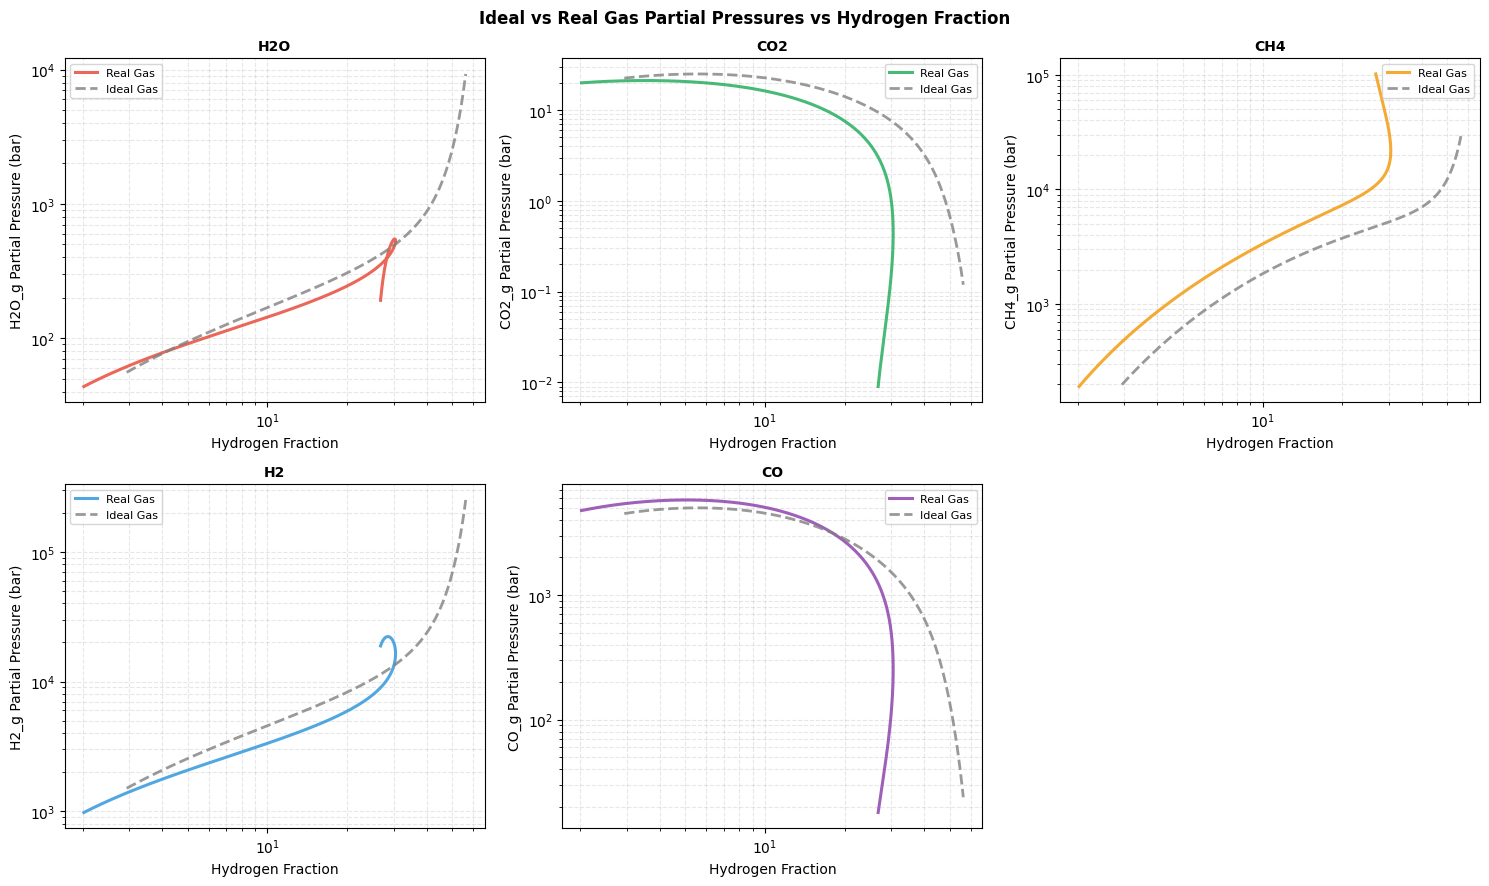

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

# === Load data ===
ideal_file = 'sub_neptune_ideal_withsol_varyHF.xlsx'
real_file  = 'sub_neptune_real_withsol_varyHF.xlsx'

# Load planet sheet for x-axis
planet_ideal = pd.read_excel(ideal_file, sheet_name='element_H')
planet_real  = pd.read_excel(real_file,  sheet_name='element_H')

# ✅ Use the actual varying parameter (fix this name if needed)
x_ideal = planet_ideal['atmosphere_ppmw'] / 1e4
x_real  = planet_real['atmosphere_ppmw'] / 1e4

# === Load each gas sheet ===
species = ['H2O_g', 'CO2_g', 'CH4_g', 'H2_g', 'CO_g']
colors  = ['#E74C3C', '#27AE60', '#F39C12', '#3498DB', '#8E44AD', '#2ECC71']

# === Create figure ===
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, sp in enumerate(species):
    ax = axes[i]

    # Load species data
    ideal_df = pd.read_excel(ideal_file, sheet_name=sp)
    real_df  = pd.read_excel(real_file,  sheet_name=sp)

    # Check that both have 'pressure' column
    if 'pressure' not in ideal_df.columns or 'pressure' not in real_df.columns:
        print(f"⚠️ Skipping {sp} — no 'pressure' column.")
        continue

    y_ideal = ideal_df['pressure']
    y_real  = real_df['pressure']

    # Plot both sets
    ax.plot(x_real,  y_real, '-',  color=colors[i], lw=2.2, label='Real Gas', alpha=0.85)
    ax.plot(x_ideal, y_ideal, '--', color='gray',  lw=2,   label='Ideal Gas', alpha=0.8)

    ax.set_xscale('log')
    ax.set_yscale('log')

    ax.set_xlabel('Hydrogen Fraction')
    ax.set_ylabel(f'{sp} Partial Pressure (bar)')
    ax.set_title(sp.replace('_g', '').upper(), fontsize=10, fontweight='bold')
    ax.grid(True, alpha=0.3, linestyle='--', which='both')
    ax.legend(fontsize=8)

# Hide unused axes
for j in range(len(species), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Ideal vs Real Gas Partial Pressures vs Hydrogen Fraction', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('ideal_vs_real_partial_pressures.png', dpi=300, bbox_inches='tight')
plt.show()


In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def plot_elemental_budget_from_excel(excel_file, elements=('C','H','O')):
    print("\n" + "="*70)
    print("Creating elemental budget plot from Excel...")
    print("="*70)

    df_H = pd.read_excel(excel_file, sheet_name='element_H')
    if 'atmosphere_ppmw' not in df_H.columns:
        raise KeyError("Could not find atmosphere_ppmw in element_H sheet.")

    H_frac_percent = df_H['atmosphere_ppmw'] / 1e4  # ppmw → %

    fig, axes = plt.subplots(1, len(elements), figsize=(16, 5))

    for idx, element in enumerate(elements):
        ax = axes[idx]
        sheet = f'element_{element}'
        df = pd.read_excel(excel_file, sheet_name=sheet)

        # Use .get() with fallback to zeros
        atm_mass = df.get('atmosphere_mass', pd.Series(np.zeros(len(df))))
        dis_mass = df.get('dissolved_mass', pd.Series(np.zeros(len(df))))
        con_mass = df.get('condensed_mass', pd.Series(np.zeros(len(df))))

        total_mass = atm_mass + dis_mass + con_mass
        total_mass[total_mass == 0] = np.nan  # avoid divide by zero

        atm_frac = atm_mass / total_mass * 100
        dis_frac = dis_mass / total_mass * 100
        con_frac = con_mass / total_mass * 100

        # Compute cumulative stacked boundaries
        y1 = atm_frac
        y2 = atm_frac + dis_frac
        y3 = atm_frac + dis_frac + con_frac

        # Clip to [0, 100] so nothing spills out of the plot
        y1, y2, y3 = [np.clip(y, 0, 100) for y in (y1, y2, y3)]

        # Plot stacked areas
        ax.fill_between(H_frac_percent, 0, y1, label='Atmosphere', color='#1f77b4', alpha=0.7)
        ax.fill_between(H_frac_percent, y1, y2, label='Dissolved', color='#ff7f0e', alpha=0.7)
        if np.nanmax(con_frac) > 0:
            ax.fill_between(H_frac_percent, y2, y3, label='Condensed', color='#2ca02c', alpha=0.7)

        ax.set_xscale('log')
        ax.set_ylim(0, 100)
        ax.set_xlabel('H Mass Fraction (%)')
        ax.set_ylabel(f'{element} Distribution (%)')
        ax.set_title(f'({chr(97+idx)}) {element} Budget', fontweight='bold')
        ax.legend(loc='best', frameon=True, fontsize=9)
        ax.grid(True, alpha=0.3, linestyle=':', linewidth=0.5)

    plt.tight_layout()
    plt.savefig('sub_neptune_elemental_budget_from_excel.png', dpi=300, bbox_inches='tight')
    print("\n✓ Successfully saved: sub_neptune_elemental_budget_from_excel.png")
    plt.show()



Starting batch plot generation...

Creating plot for: Elemental Budget Distribution (Real Gas)
Reading from: sub_neptune_real_withsol_varyHF.xlsx

✓ Successfully saved: sub_neptune_elemental_budget_real.png
Displaying plot for Elemental Budget Distribution (Real Gas)...


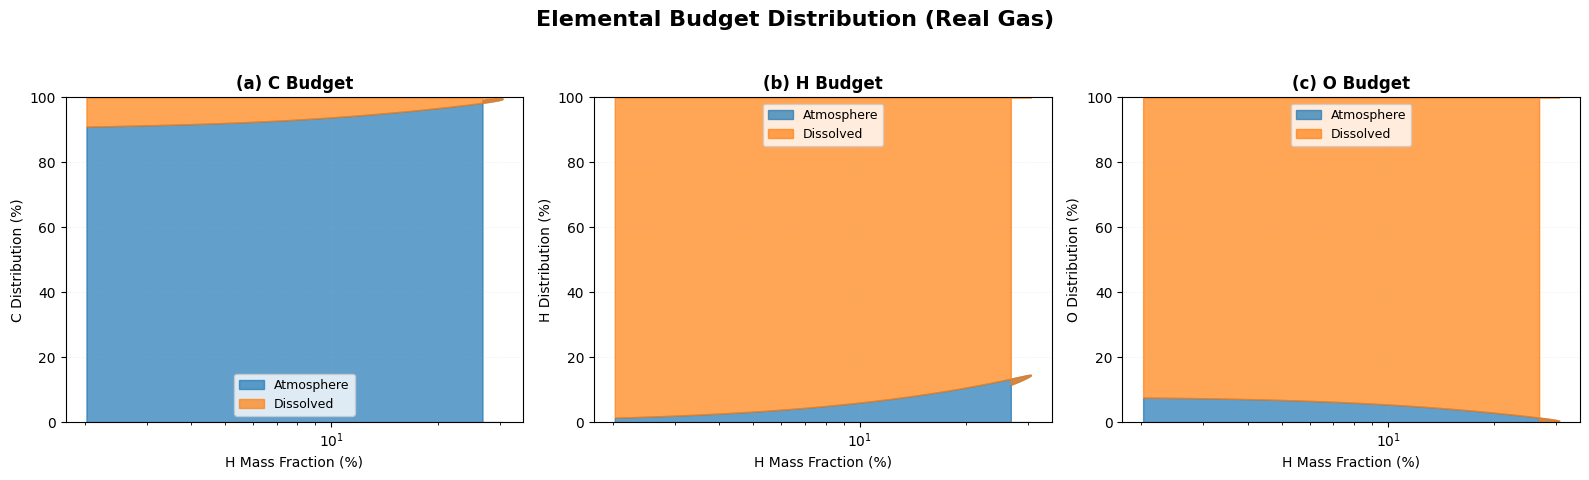


Creating plot for: Elemental Budget Distribution (Ideal Gas)
Reading from: sub_neptune_ideal_withsol_varyHF.xlsx

✓ Successfully saved: sub_neptune_elemental_budget_ideal.png
Displaying plot for Elemental Budget Distribution (Ideal Gas)...


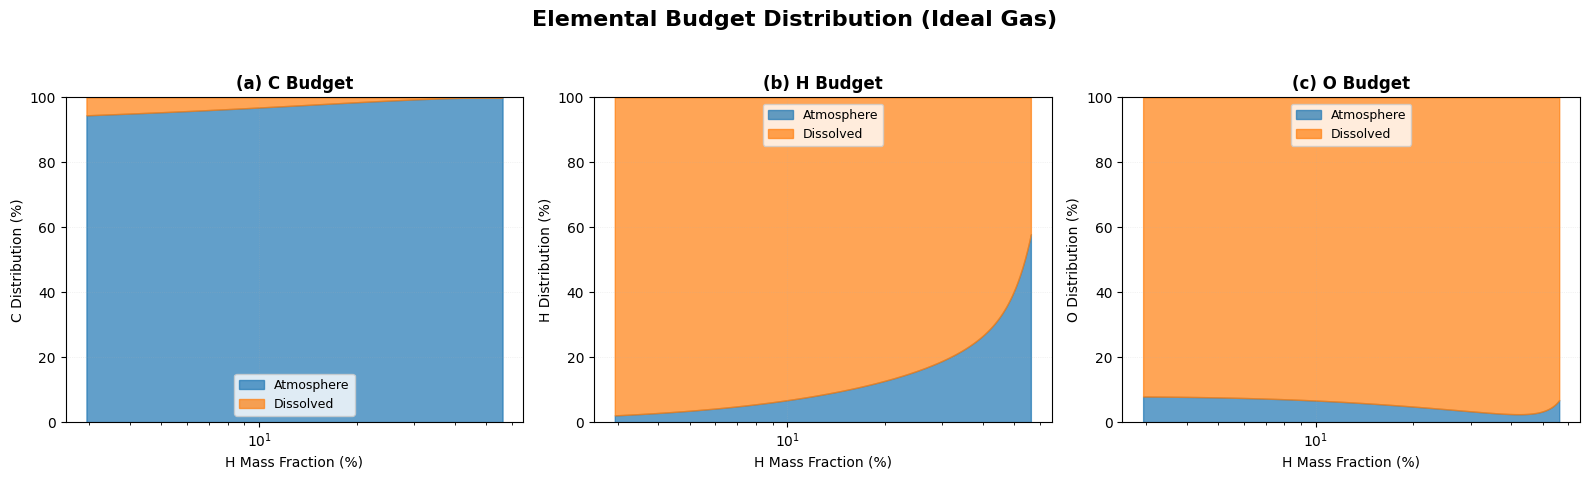


All plotting tasks complete.


In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def plot_elemental_budget_from_excel_real(excel_file, output_filename, main_title, elements=('C','H','O')):
    """
    Plots the elemental budget from a specified Excel file and saves it.

    Args:
        excel_file (str): Path to the input Excel file.
        output_filename (str): Filename for the saved PNG image.
        main_title (str): The main title for the entire figure.
        elements (tuple, optional): The elements to plot. Defaults to ('C','H','O').
    """
    print("\n" + "="*70)
    print(f"Creating plot for: {main_title}")
    print(f"Reading from: {excel_file}")
    print("="*70)

    try:
        df_H = pd.read_excel(excel_file, sheet_name='element_H')
    except Exception as e:
        print(f"Error reading 'element_H' sheet from {excel_file}: {e}")
        print("Please ensure the Excel file path is correct and the sheet exists.")
        raise # Re-raise exception to be caught by the loop's try...except

    if 'atmosphere_ppmw' not in df_H.columns:
        print("Error: Could not find 'atmosphere_ppmw' column in 'element_H' sheet.")
        raise KeyError("Could not find atmosphere_ppmw in element_H sheet.")

    H_frac_percent = df_H['atmosphere_ppmw'] / 1e4  # ppmw → %

    fig, axes = plt.subplots(1, len(elements), figsize=(16, 5))

    # --- Set the dynamic overall figure title ---
    fig.suptitle(main_title, fontsize=16, fontweight='bold')
    # --------------------------------------------

    all_sheets_found = True
    for idx, element in enumerate(elements):
        ax = axes[idx]
        sheet = f'element_{element}'
        
        try:
            df = pd.read_excel(excel_file, sheet_name=sheet)
        except Exception as e:
            print(f"Warning: Could not read sheet '{sheet}'. Skipping element {element}.")
            print(f"  Details: {e}")
            ax.set_title(f'({chr(97+idx)}) {element} Budget - Data N/A', fontweight='bold')
            ax.text(0.5, 0.5, f"Data for '{sheet}'\nnot found", 
                    horizontalalignment='center', verticalalignment='center', 
                    transform=ax.transAxes, color='red', fontsize=10)
            all_sheets_found = False
            continue # Skip to the next element if sheet is missing

        # Use .get() with fallback to zeros
        atm_mass = df.get('atmosphere_mass', pd.Series(np.zeros(len(df))))
        dis_mass = df.get('dissolved_mass', pd.Series(np.zeros(len(df))))
        con_mass = df.get('condensed_mass', pd.Series(np.zeros(len(df))))

        total_mass = atm_mass + dis_mass + con_mass
        total_mass[total_mass == 0] = np.nan  # avoid divide by zero

        atm_frac = atm_mass / total_mass * 100
        dis_frac = dis_mass / total_mass * 100
        con_frac = con_mass / total_mass * 100

        # Compute cumulative stacked boundaries
        y1 = atm_frac
        y2 = atm_frac + dis_frac
        y3 = atm_frac + dis_frac + con_frac

        # Clip to [0, 100] so nothing spills out of the plot
        y1, y2, y3 = [np.clip(y, 0, 100) for y in (y1, y2, y3)]

        # Plot stacked areas
        ax.fill_between(H_frac_percent, 0, y1, label='Atmosphere', color='#1f77b4', alpha=0.7)
        ax.fill_between(H_frac_percent, y1, y2, label='Dissolved', color='#ff7f0e', alpha=0.7)
        if np.nanmax(con_frac) > 0:
            ax.fill_between(H_frac_percent, y2, y3, label='Condensed', color='#2ca02c', alpha=0.7)

        ax.set_xscale('log')
        ax.set_ylim(0, 100)
        ax.set_xlabel('H Mass Fraction (%)')
        ax.set_ylabel(f'{element} Distribution (%)')
        ax.set_title(f'({chr(97+idx)}) {element} Budget', fontweight='bold')
        ax.legend(loc='best', frameon=True, fontsize=9)
        ax.grid(True, alpha=0.3, linestyle=':', linewidth=0.5)

    # Adjust layout to make room for the suptitle
    plt.tight_layout(rect=[0, 0.03, 1, 0.95]) 
    
    # --- Use the dynamic output filename ---
    plt.savefig(output_filename, dpi=300, bbox_inches='tight')
    print(f"\n✓ Successfully saved: {output_filename}")
    # -------------------------------------
    
    # --- Show the plot ---
    print(f"Displaying plot for {main_title}...")
    plt.show()
    # ---------------------

    plt.close(fig) # Close the figure to free up memory before the next loop
    
    if not all_sheets_found:
        print("\nNote: Plot generated, but some element data sheets were missing.")

# --- Main execution loop ---

# Define the cases to plot
plot_cases = [
    {
        "excel_file": "sub_neptune_real_withsol_varyHF.xlsx",
        "output_filename": "sub_neptune_elemental_budget_real.png",
        "main_title": "Elemental Budget Distribution (Real Gas)"
    },
    {
        "excel_file": "sub_neptune_ideal_withsol_varyHF.xlsx",
        "output_filename": "sub_neptune_elemental_budget_ideal.png",
        "main_title": "Elemental Budget Distribution (Ideal Gas)"
    }
]

print("\nStarting batch plot generation...")

for case in plot_cases:
    try:
        plot_elemental_budget_from_excel_real(
            excel_file=case["excel_file"],
            output_filename=case["output_filename"],
            main_title=case["main_title"]
            # We use the default elements: ('C', 'H', 'O')
        )
    except Exception as e:
        print(f"\n--- FAILED to plot for: {case['excel_file']} ---")
        print(f"Error: {e}")
        print("Please check file path, sheet names, and data columns.")
        print("--------------------------------------------------\n")

print("\n" + "="*70)
print("All plotting tasks complete.")
print("="*70)




Creating elemental budget plot from Excel...

✓ Successfully saved: sub_neptune_elemental_budget_from_excel.png


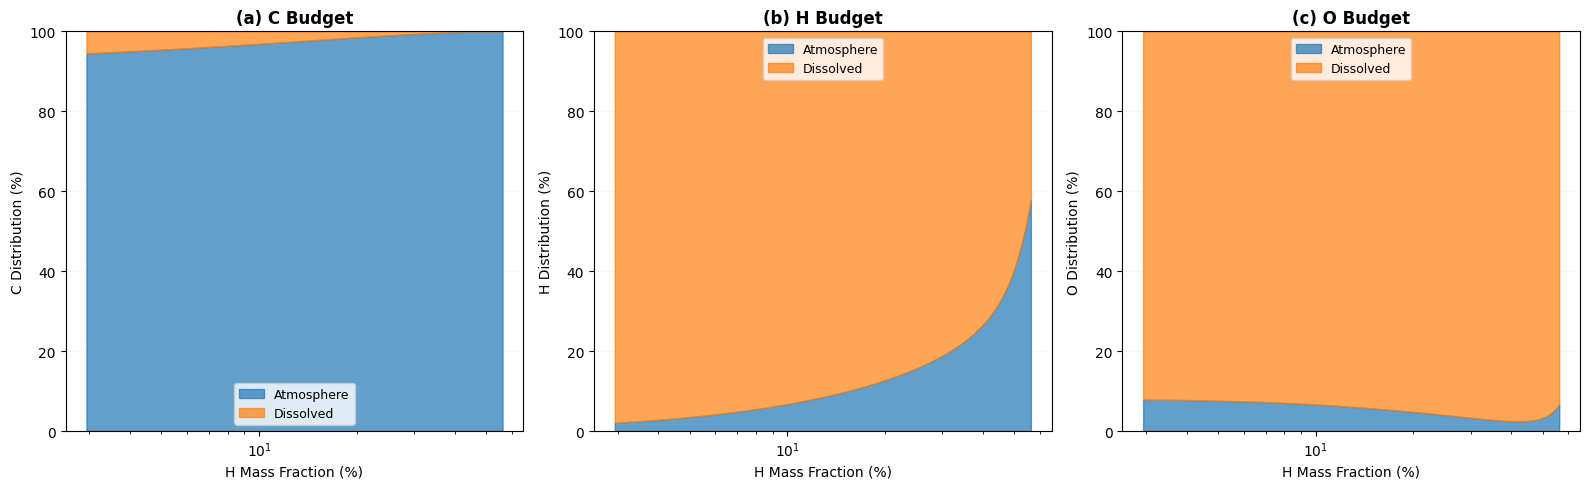

In [30]:
plot_elemental_budget_from_excel("sub_neptune_ideal_withsol_varyHF.xlsx")


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def plot_molecular_budget_from_excels(excel_file, species=None):
    """
    Plot molecular budget (atmosphere vs dissolved vs condensed)
    for each species from a real-gas Excel output file.
    """

    print("\n" + "="*70)
    print("Creating molecular budget plot from:", excel_file)
    print("="*70)
    
    # Default species to plot
    if species is None:
        species = ['H2O_g', 'H2_g', 'CH4_g', 'CO2_g', 'CO_g', 'O2_g']
    
    # --- 1) Read hydrogen fraction as x-axis
    df_H = pd.read_excel(excel_file, sheet_name='element_H')
    if 'atmosphere_ppmw' in df_H.columns:
        H_frac_percent = df_H['atmosphere_ppmw'].values / 1e4  # ppmw → %
    else:
        raise KeyError("The sheet 'element_H' must contain 'atmosphere_ppmw' for the H mass fraction axis.")
    
    # --- 2) Create figure
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    axes = axes.flatten()
    
    for i, sp in enumerate(species):
        ax = axes[i]
        
        try:
            df = pd.read_excel(excel_file, sheet_name=sp)
        except Exception as e:
            print(f"⚠️ Skipping {sp}: sheet not found.")
            continue
        
        # Ensure required columns exist
        if not {'atmosphere_mass', 'dissolved_mass'}.issubset(df.columns):
            print(f"⚠️ Skipping {sp}: missing mass columns.")
            continue
        
        atm_mass = df['atmosphere_mass'].values
        dis_mass = df['dissolved_mass'].values
        con_mass = df['condensed_mass'].values if 'condensed_mass' in df.columns else np.zeros_like(atm_mass)
        
        total_mass = atm_mass + dis_mass + con_mass
        total_mass[total_mass == 0] = np.nan  # avoid divide-by-zero
        
        # --- Stacked area plot in %
        ax.fill_between(H_frac_percent, 0, atm_mass/total_mass*100, 
                        label='Atmosphere', color='#1f77b4', alpha=0.7)
        ax.fill_between(H_frac_percent, atm_mass/total_mass*100, 
                        (atm_mass+dis_mass)/total_mass*100, 
                        label='Dissolved', color='#ff7f0e', alpha=0.7)
        if np.any(con_mass > 0):
            ax.fill_between(H_frac_percent, (atm_mass+dis_mass)/total_mass*100, 100, 
                            label='Condensed', color='#2ca02c', alpha=0.7)
        
        # --- Formatting
        ax.set_xscale('log')
        ax.set_xlim(H_frac_percent.min(), H_frac_percent.max())
        ax.set_ylim(0, 100)
        ax.set_xlabel("H Mass Fraction (%)")
        ax.set_ylabel("Distribution (%)")
        ax.set_title(f"({chr(97+i)}) {sp.replace('_g','').upper()} Budget", fontweight='bold')
        ax.grid(True, alpha=0.3, linestyle=':', linewidth=0.5)
        
        if i == 0:
            ax.legend(frameon=True, fontsize=9)
    
    # Hide any unused subplots
    for j in range(len(species), len(axes)):
        fig.delaxes(axes[j])
    
    plt.tight_layout()
    plt.savefig("sub_neptune_molecular_budget.png", dpi=300, bbox_inches='tight')
    print("\n✓ Successfully saved: sub_neptune_molecular_budget.png")
    print("="*70)
    plt.show()



Creating molecular budget plot from: sub_neptune_real_withsol_varyHF.xlsx

✓ Successfully saved: sub_neptune_molecular_budget.png


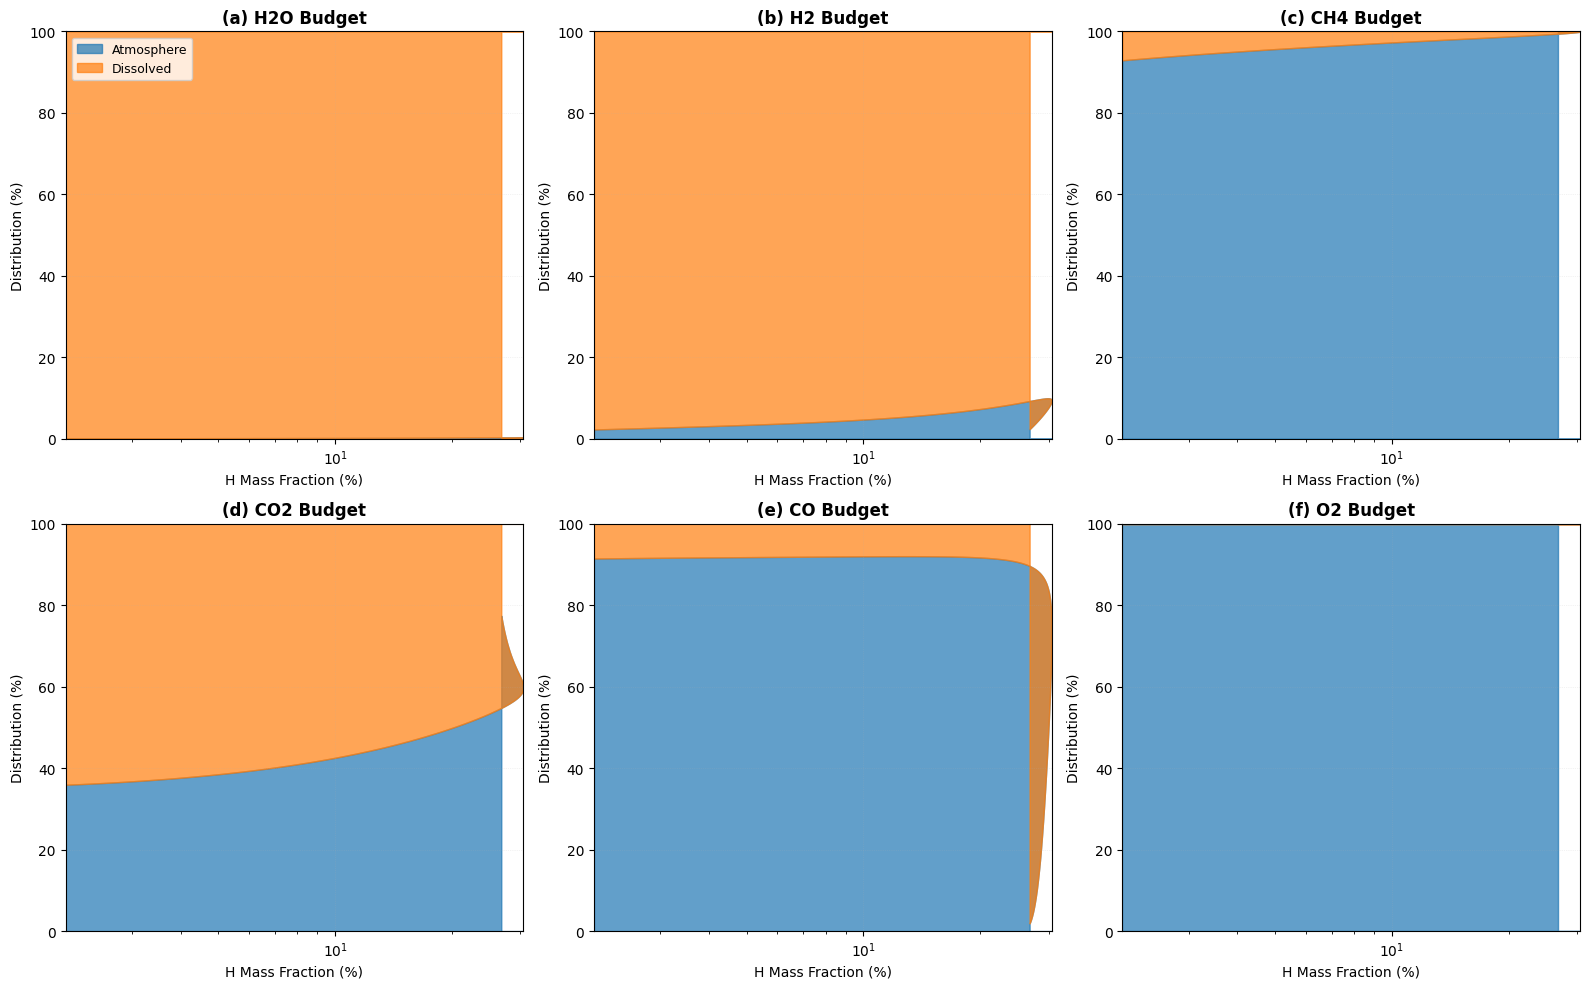

In [32]:
plot_molecular_budget_from_excels("sub_neptune_real_withsol_varyHF.xlsx")



Creating molecular budget plot from: sub_neptune_ideal_withsol_varyHF.xlsx

✓ Successfully saved: sub_neptune_molecular_budget.png


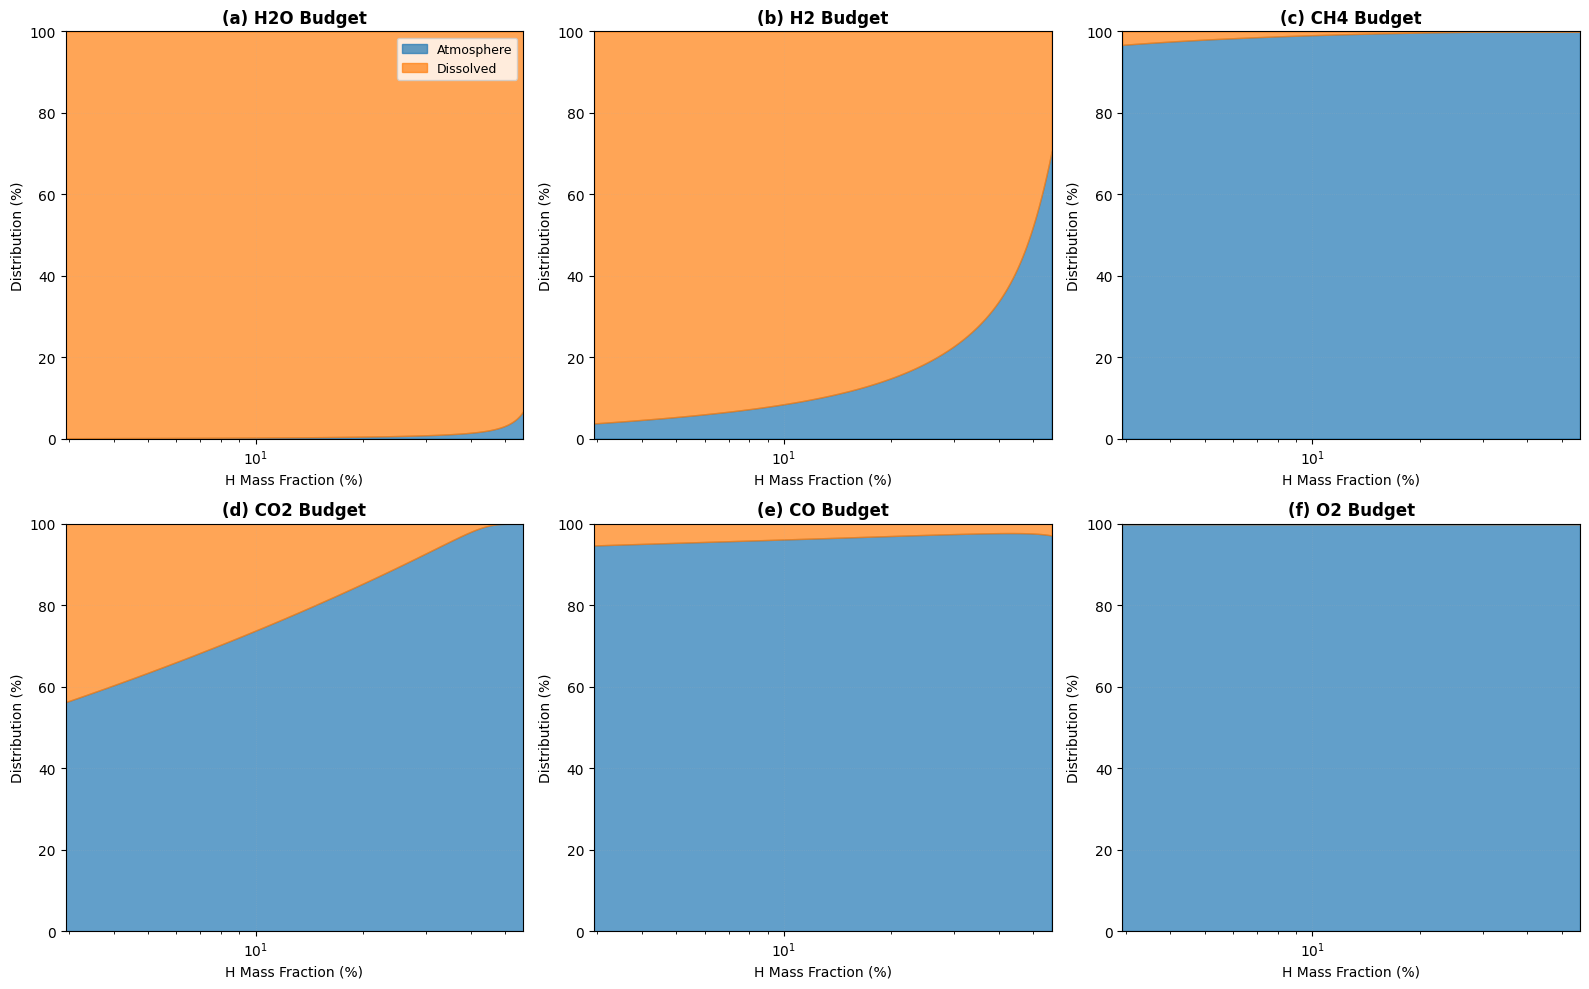

In [33]:
plot_molecular_budget_from_excels("sub_neptune_ideal_withsol_varyHF.xlsx")


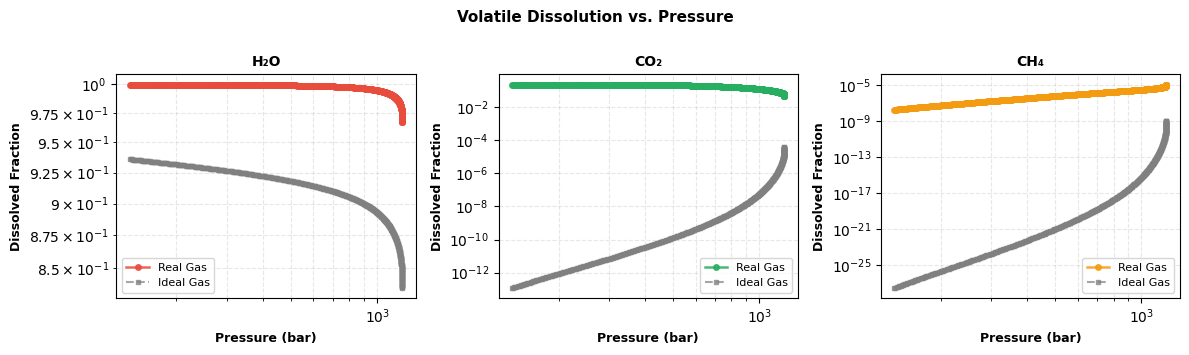

In [34]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Load data for varyMp
real_h2o_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='H2O_g')
real_co2_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='CO2_g')
real_ch4_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='CH4_g')

ideal_h2o_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='H2O_g')
ideal_co2_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='CO2_g')
ideal_ch4_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='CH4_g')

# Calculate dissolved fractions
real_h2o_diss = real_h2o_mp['dissolved_mass'] / real_h2o_mp['total_mass']
real_co2_diss = real_co2_mp['dissolved_mass'] / real_co2_mp['total_mass']
real_ch4_diss = real_ch4_mp['dissolved_mass'] / real_ch4_mp['total_mass']

ideal_h2o_diss = ideal_h2o_mp['dissolved_mass'] / ideal_h2o_mp['total_mass']
ideal_co2_diss = ideal_co2_mp['dissolved_mass'] / ideal_co2_mp['total_mass']
ideal_ch4_diss = ideal_ch4_mp['dissolved_mass'] / ideal_ch4_mp['total_mass']

# Use pressure as proxy for planet mass
pressure_real = real_h2o_mp['pressure']

# Create figure
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

species = [
    ('H₂O', real_h2o_diss, ideal_h2o_diss, '#E74C3C'),
    ('CO₂', real_co2_diss, ideal_co2_diss, '#27AE60'),
    ('CH₄', real_ch4_diss, ideal_ch4_diss, '#F39C12')
]

for idx, (name, real_diss, ideal_diss, color) in enumerate(species):
    ax = axes[idx]
    
    ax.plot(pressure_real, real_diss, 'o-', color=color, linewidth=1.8, markersize=4, 
            label='Real Gas', alpha=0.85)
    ax.plot(pressure_real, ideal_diss, 's--', color='gray', linewidth=1.5, markersize=3, 
            label='Ideal Gas', alpha=0.7)
    
    ax.set_xscale('log')
    ax.set_yscale('log')
    
    ax.set_xlabel('Pressure (bar)', fontsize=9, fontweight='bold')
    ax.set_ylabel('Dissolved Fraction', fontsize=9, fontweight='bold')
    ax.set_title(f'{name}', fontsize=10, fontweight='bold')
    
    ax.grid(True, alpha=0.3, linestyle='--', which='both')
    ax.legend(fontsize=8, loc='best')

plt.suptitle('Volatile Dissolution vs. Pressure', fontsize=11, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig('plot2_volatile_dissolution_vs_pressure.png', dpi=300, bbox_inches='tight')
plt.show()


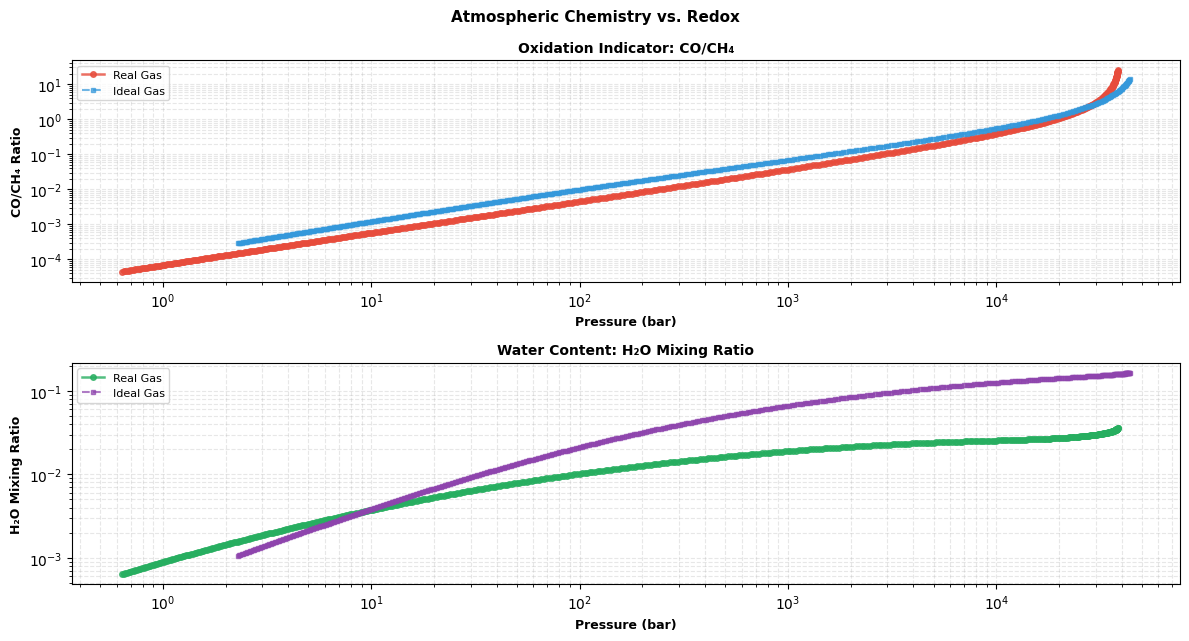

In [35]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Load data for varyfO2
real_co_fo2 = pd.read_excel('sub_neptune_real_withsol_varyfO2.xlsx', sheet_name='CO_g')
real_ch4_fo2 = pd.read_excel('sub_neptune_real_withsol_varyfO2.xlsx', sheet_name='CH4_g')
real_h2o_fo2 = pd.read_excel('sub_neptune_real_withsol_varyfO2.xlsx', sheet_name='H2O_g')

ideal_co_fo2 = pd.read_excel('sub_neptune_ideal_withsol_varyfO2.xlsx', sheet_name='CO_g')
ideal_ch4_fo2 = pd.read_excel('sub_neptune_ideal_withsol_varyfO2.xlsx', sheet_name='CH4_g')
ideal_h2o_fo2 = pd.read_excel('sub_neptune_ideal_withsol_varyfO2.xlsx', sheet_name='H2O_g')

# Calculate oxidation metrics
# CO/CH4 ratio (higher = more oxidized)
real_co_ch4 = real_co_fo2['atmosphere_ppm'] / real_ch4_fo2['atmosphere_ppm']
ideal_co_ch4 = ideal_co_fo2['atmosphere_ppm'] / ideal_ch4_fo2['atmosphere_ppm']

# H2O mixing ratio (proxy for oxidation state)
real_h2o_mix = real_h2o_fo2['volume_mixing_ratio']
ideal_h2o_mix = ideal_h2o_fo2['volume_mixing_ratio']

# Use pressure as proxy for fO2
fo2_proxy_real = real_co_fo2['pressure']
fo2_proxy_ideal = ideal_co_fo2['pressure']

# Create figure
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6.5))

# Top plot
ax1.plot(fo2_proxy_real, real_co_ch4, 'o-', color='#E74C3C', linewidth=1.8, markersize=4, 
         label='Real Gas', alpha=0.8)
ax1.plot(fo2_proxy_ideal, ideal_co_ch4, 's--', color='#3498DB', linewidth=1.5, markersize=3, 
         label='Ideal Gas', alpha=0.7)
ax1.set_yscale('log')
ax1.set_xscale('log')
ax1.set_xlabel('Pressure (bar)', fontsize=9, fontweight='bold')
ax1.set_ylabel('CO/CH₄ Ratio', fontsize=9, fontweight='bold')
ax1.set_title('Oxidation Indicator: CO/CH₄', fontsize=10, fontweight='bold')
ax1.grid(True, alpha=0.3, linestyle='--', which='both')
ax1.legend(fontsize=8, loc='best')

# Bottom plot
ax2.plot(fo2_proxy_real, real_h2o_mix, 'o-', color='#27AE60', linewidth=1.8, markersize=4, 
         label='Real Gas', alpha=0.8)
ax2.plot(fo2_proxy_ideal, ideal_h2o_mix, 's--', color='#8E44AD', linewidth=1.5, markersize=3, 
         label='Ideal Gas', alpha=0.7)
ax2.set_yscale('log')
ax2.set_xscale('log')
ax2.set_xlabel('Pressure (bar)', fontsize=9, fontweight='bold')
ax2.set_ylabel('H₂O Mixing Ratio', fontsize=9, fontweight='bold')
ax2.set_title('Water Content: H₂O Mixing Ratio', fontsize=10, fontweight='bold')
ax2.grid(True, alpha=0.3, linestyle='--', which='both')
ax2.legend(fontsize=8, loc='best')

plt.suptitle('Atmospheric Chemistry vs. Redox', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('plot3_oxidation_state_vs_fo2.png', dpi=300, bbox_inches='tight')
plt.show()



Creating partial pressure comparison plot (ideal vs real)...

✓ Saved: ideal_vs_real_partial_pressures_with_surfaceP.png


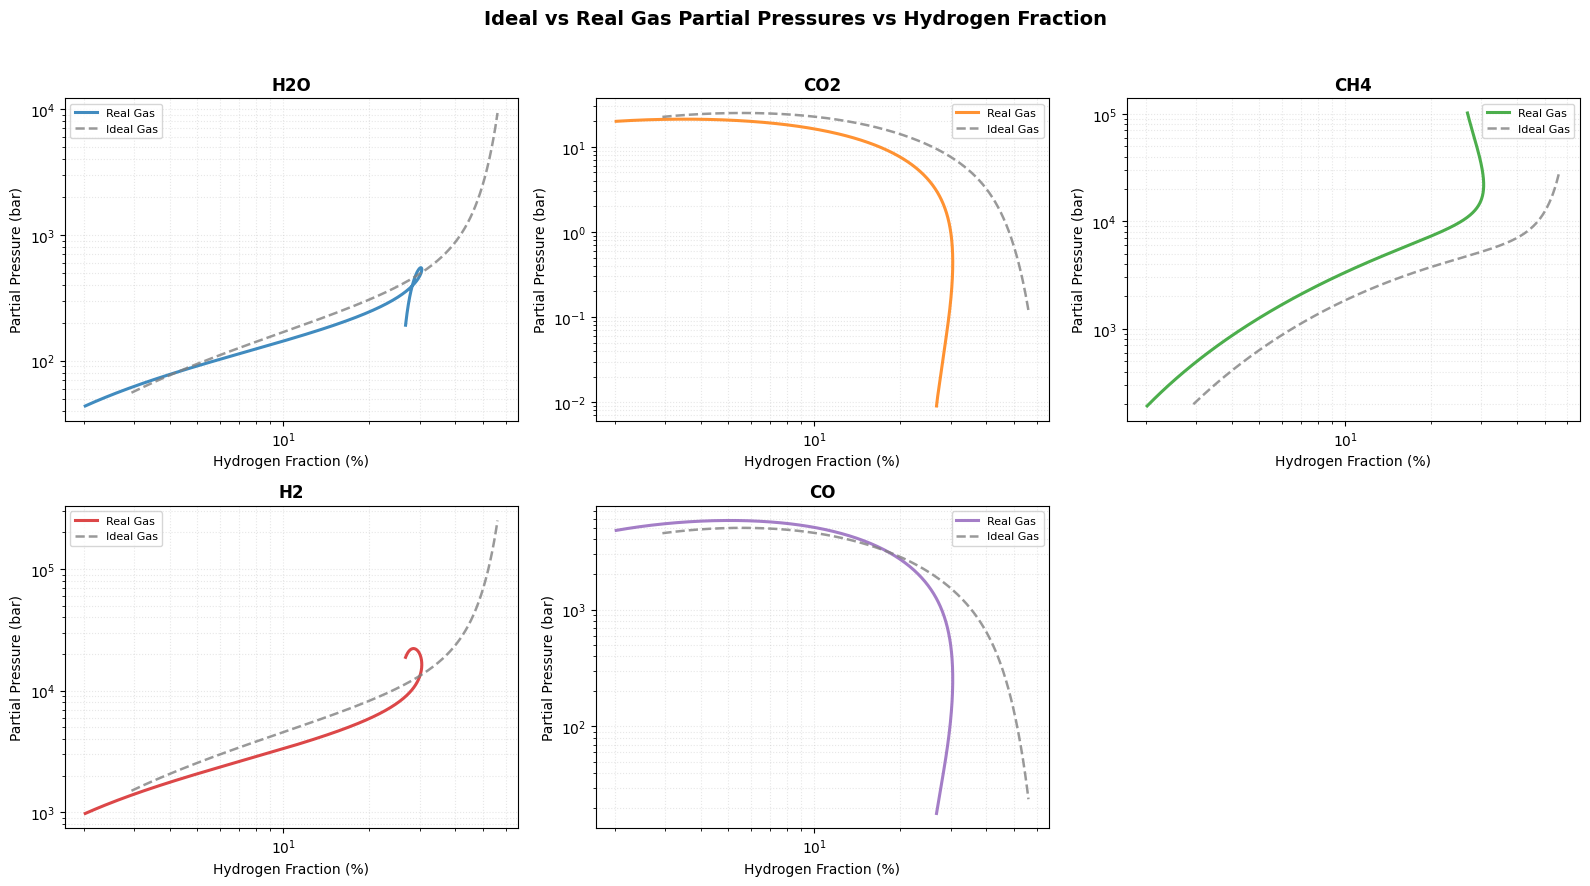

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

def plot_partial_pressures_with_surface_pressure(
    ideal_file='sub_neptune_ideal_withsol_varyHF.xlsx',
    real_file='sub_neptune_real_withsol_varyHF.xlsx',
    species=('H2O_g', 'CO2_g', 'CH4_g', 'H2_g', 'CO_g')
):
    print("\n" + "="*80)
    print("Creating partial pressure comparison plot (ideal vs real)...")
    print("="*80)

    # === Load planet-level data for H fraction and total pressure ===
    planet_ideal = pd.read_excel(ideal_file, sheet_name='element_H')
    planet_real  = pd.read_excel(real_file,  sheet_name='element_H')

    # X-axis: hydrogen mass fraction (convert ppmw → %)
    x_ideal = planet_ideal['atmosphere_ppmw'] / 1e4
    x_real  = planet_real['atmosphere_ppmw'] / 1e4

    # Optional: total surface pressure if available
    Psurf_ideal = planet_ideal.get('pressure', np.nan)
    Psurf_real  = planet_real.get('pressure', np.nan)

    # === Setup figure ===
    ncols = 3
    nrows = int(np.ceil(len(species) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 9))
    axes = axes.flatten()

    cmap = plt.cm.tab10.colors

    for i, sp in enumerate(species):
        ax = axes[i]
        color = cmap[i % len(cmap)]

        # --- Load gas sheet ---
        try:
            ideal_df = pd.read_excel(ideal_file, sheet_name=sp)
            real_df  = pd.read_excel(real_file,  sheet_name=sp)
        except ValueError:
            print(f"⚠️ Sheet '{sp}' not found — skipping.")
            continue

        if 'pressure' not in ideal_df.columns or 'pressure' not in real_df.columns:
            print(f"⚠️ Skipping {sp} — missing 'pressure' column.")
            continue

        # --- Data ---
        y_ideal = ideal_df['pressure']
        y_real  = real_df['pressure']

        # --- Main axis: partial pressures ---
        ax.plot(x_real,  y_real, '-',  color=color, lw=2.2, label='Real Gas', alpha=0.85)
        ax.plot(x_ideal, y_ideal, '--', color='gray',  lw=1.8, label='Ideal Gas', alpha=0.8)

        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlabel('Hydrogen Fraction (%)')
        ax.set_ylabel('Partial Pressure (bar)')
        ax.set_title(sp.replace('_g', '').upper(), fontweight='bold')
        ax.grid(True, alpha=0.3, linestyle=':', which='both')

        # --- Add right axis for total surface pressure ---
        if not (np.all(np.isnan(Psurf_real)) and np.all(np.isnan(Psurf_ideal))):
            ax2 = ax.twinx()
            ax2.plot(x_real, Psurf_real, ':', color='k', lw=1.5, alpha=0.6, label='Total Surface P (real)')
            ax2.set_yscale('log')
            ax2.set_ylabel('Surface Pressure (bar)', color='k', fontsize=9)
            ax2.tick_params(axis='y', labelcolor='k')

        # --- Legend ---
        ax.legend(fontsize=8, loc='best')

    # Remove empty subplots
    for j in range(len(species), len(axes)):
        fig.delaxes(axes[j])

    plt.suptitle('Ideal vs Real Gas Partial Pressures vs Hydrogen Fraction',
                 fontsize=14, fontweight='bold')
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.savefig('ideal_vs_real_partial_pressures_with_surfaceP.png',
                dpi=300, bbox_inches='tight')
    print("\n✓ Saved: ideal_vs_real_partial_pressures_with_surfaceP.png")
    plt.show()
plot_partial_pressures_with_surface_pressure(
    ideal_file='sub_neptune_ideal_withsol_varyHF.xlsx',
    real_file='sub_neptune_real_withsol_varyHF.xlsx',
    species=('H2O_g', 'CO2_g', 'CH4_g', 'H2_g', 'CO_g')
)

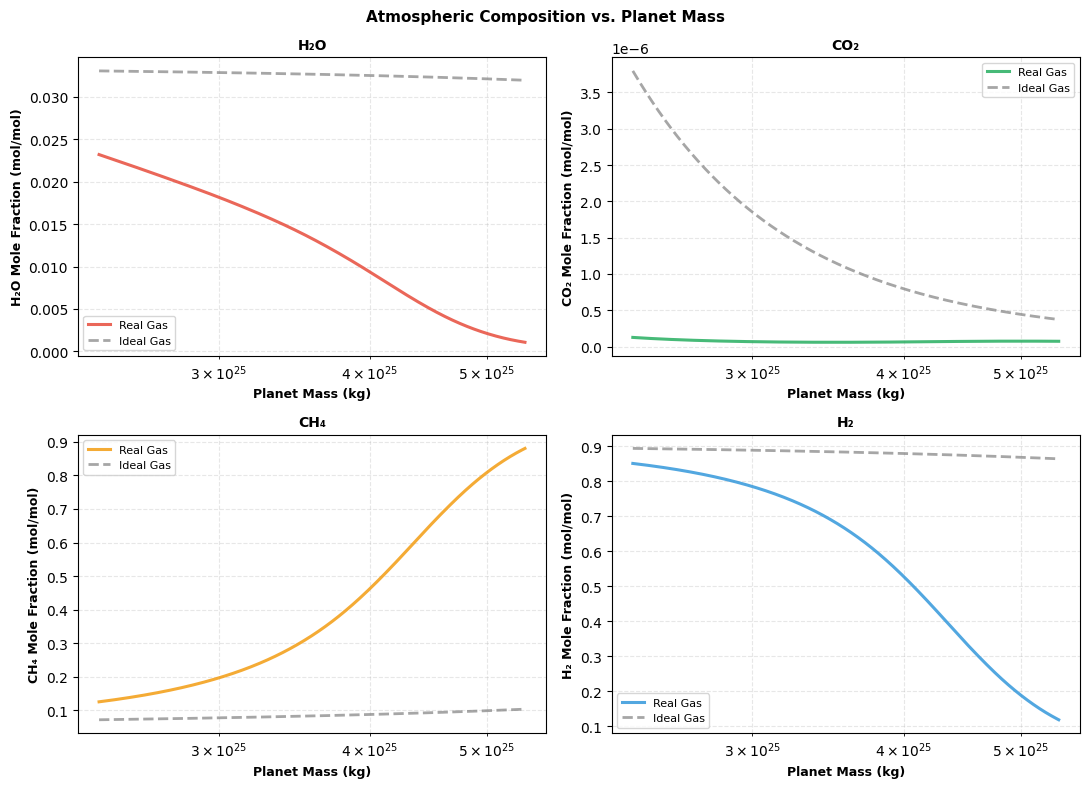

In [37]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Load data for varyMp (varying planet mass)
real_planet = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='planet')
real_h2o_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='H2O_g')
real_co2_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='CO2_g')
real_ch4_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='CH4_g')
real_h2_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='H2_g')

ideal_planet = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='planet')
ideal_h2o_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='H2O_g')
ideal_co2_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='CO2_g')
ideal_ch4_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='CH4_g')
ideal_h2_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='H2_g')

# Get planet mass
planet_mass_real = real_planet['planet_mass']
planet_mass_ideal = ideal_planet['planet_mass']

# Get atmosphere mixing ratios (fraction 0-1)
real_h2o_mix = real_h2o_mp['volume_mixing_ratio']
real_co2_mix = real_co2_mp['volume_mixing_ratio']
real_ch4_mix = real_ch4_mp['volume_mixing_ratio']
real_h2_mix = real_h2_mp['volume_mixing_ratio']

ideal_h2o_mix = ideal_h2o_mp['volume_mixing_ratio']
ideal_co2_mix = ideal_co2_mp['volume_mixing_ratio']
ideal_ch4_mix = ideal_ch4_mp['volume_mixing_ratio']
ideal_h2_mix = ideal_h2_mp['volume_mixing_ratio']

# Create figure with 4 subplots
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes = axes.flatten()

species_data = [
    ('H₂O', real_h2o_mix, ideal_h2o_mix, '#E74C3C'),
    ('CO₂', real_co2_mix, ideal_co2_mix, '#27AE60'),
    ('CH₄', real_ch4_mix, ideal_ch4_mix, '#F39C12'),
    ('H₂', real_h2_mix, ideal_h2_mix, '#3498DB')
]

for idx, (name, real_mix, ideal_mix, color) in enumerate(species_data):
    ax = axes[idx]
    
    # Lines only (no markers)
    ax.plot(planet_mass_real, real_mix, '-', color=color, linewidth=2.2, 
            label='Real Gas', alpha=0.85)
    ax.plot(planet_mass_ideal, ideal_mix, '--', color='gray', linewidth=2, 
            label='Ideal Gas', alpha=0.7)
    
    # Log scale for x-axis only (planet mass)
    ax.set_xscale('log')
    # Linear scale for y-axis (mixing ratio from 0-1)
    
    ax.set_xlabel('Planet Mass (kg)', fontsize=9, fontweight='bold')
    ax.set_ylabel(f'{name} Mole Fraction (mol/mol)', fontsize=9, fontweight='bold')
    ax.set_title(f'{name}', fontsize=10, fontweight='bold')
    
    ax.grid(True, alpha=0.3, linestyle='--', which='both')
    ax.legend(fontsize=8, loc='best')

plt.suptitle('Atmospheric Composition vs. Planet Mass', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('plot_bonus_atmosphere_vs_planetmass.png', dpi=300, bbox_inches='tight')
plt.show()


/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_38577/39517835.py:73: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


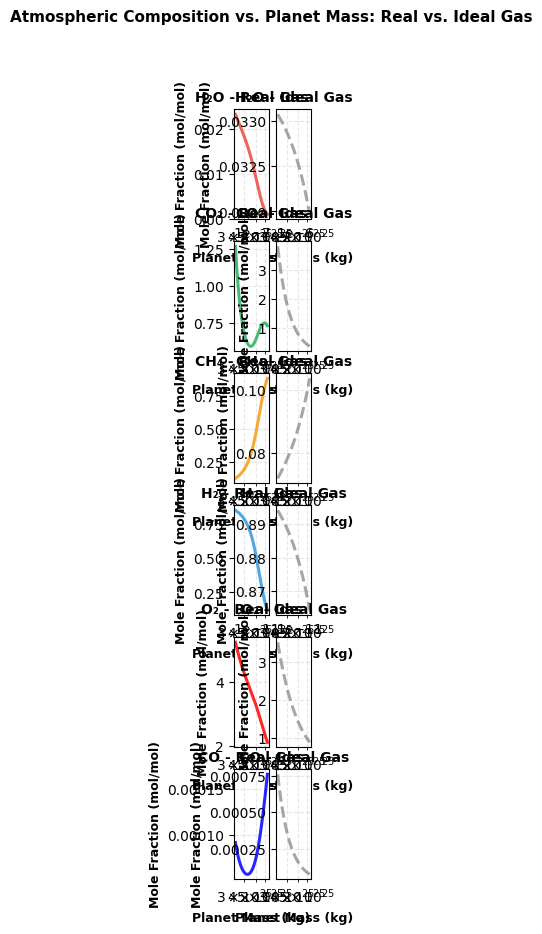

In [63]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Load data for varyMp (varying planet mass)
real_planet = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='planet')
real_h2o_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='H2O_g')
real_co2_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='CO2_g')
real_ch4_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='CH4_g')
real_h2_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='H2_g')
real_o2_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='O2_g')
real_co_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='CO_g')

ideal_planet = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='planet')
ideal_h2o_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='H2O_g')
ideal_co2_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='CO2_g')
ideal_ch4_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='CH4_g')
ideal_h2_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='H2_g')
ideal_o2_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='O2_g')
ideal_co_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='CO_g')

# Get planet mass
planet_mass_real = real_planet['planet_mass']
planet_mass_ideal = ideal_planet['planet_mass']

# Get atmosphere mixing ratios (fraction 0-1)
real_h2o_mix = real_h2o_mp['volume_mixing_ratio']
real_co2_mix = real_co2_mp['volume_mixing_ratio']
real_ch4_mix = real_ch4_mp['volume_mixing_ratio']
real_h2_mix = real_h2_mp['volume_mixing_ratio']
real_o2_mix = real_o2_mp['volume_mixing_ratio']
real_co_mix = real_co_mp['volume_mixing_ratio']

ideal_h2o_mix = ideal_h2o_mp['volume_mixing_ratio']
ideal_co2_mix = ideal_co2_mp['volume_mixing_ratio']
ideal_ch4_mix = ideal_ch4_mp['volume_mixing_ratio']
ideal_h2_mix = ideal_h2_mp['volume_mixing_ratio']
ideal_o2_mix = ideal_o2_mp['volume_mixing_ratio']
ideal_co_mix = ideal_co_mp['volume_mixing_ratio']

# Create figure: 4 rows (one per species), 2 columns (real vs ideal)
fig, axes = plt.subplots(6, 2, figsize=(1, 10))

species_data = [
    ('H₂O', real_h2o_mix, ideal_h2o_mix, '#E74C3C'),
    ('CO₂', real_co2_mix, ideal_co2_mix, '#27AE60'),
    ('CH₄', real_ch4_mix, ideal_ch4_mix, '#F39C12'),
    ('H₂', real_h2_mix, ideal_h2_mix, '#3498DB'),
    ('O₂', real_o2_mix, ideal_o2_mix, 'red'),
    ('CO', real_co_mix, ideal_co_mix, 'blue')
]

for row, (name, real_mix, ideal_mix, color) in enumerate(species_data):
    # Real gas (left column)
    ax_real = axes[row, 0]
    ax_real.plot(planet_mass_real, real_mix, '-', color=color, linewidth=2.2, alpha=0.85)
    ax_real.set_xscale('log')
    ax_real.set_xlabel('Planet Mass (kg)', fontsize=9, fontweight='bold')
    ax_real.set_ylabel('Mole Fraction (mol/mol)', fontsize=9, fontweight='bold')
    ax_real.set_title(f'{name} - Real Gas', fontsize=10, fontweight='bold')
    ax_real.grid(True, alpha=0.3, linestyle='--', which='both')
    
    # Ideal gas (right column)
    ax_ideal = axes[row, 1]
    ax_ideal.plot(planet_mass_ideal, ideal_mix, '--', color='gray', linewidth=2.2, alpha=0.7)
    ax_ideal.set_xscale('log')
    ax_ideal.set_xlabel('Planet Mass (kg)', fontsize=9, fontweight='bold')
    ax_ideal.set_ylabel('Mole Fraction (mol/mol)', fontsize=9, fontweight='bold')
    ax_ideal.set_title(f'{name} - Ideal Gas', fontsize=10, fontweight='bold')
    ax_ideal.grid(True, alpha=0.3, linestyle='--', which='both')

plt.suptitle('Atmospheric Composition vs. Planet Mass: Real vs. Ideal Gas', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('plot_bonus_atmosphere_vs_planetmass_sidebyside.png', dpi=300, bbox_inches='tight')
plt.show()


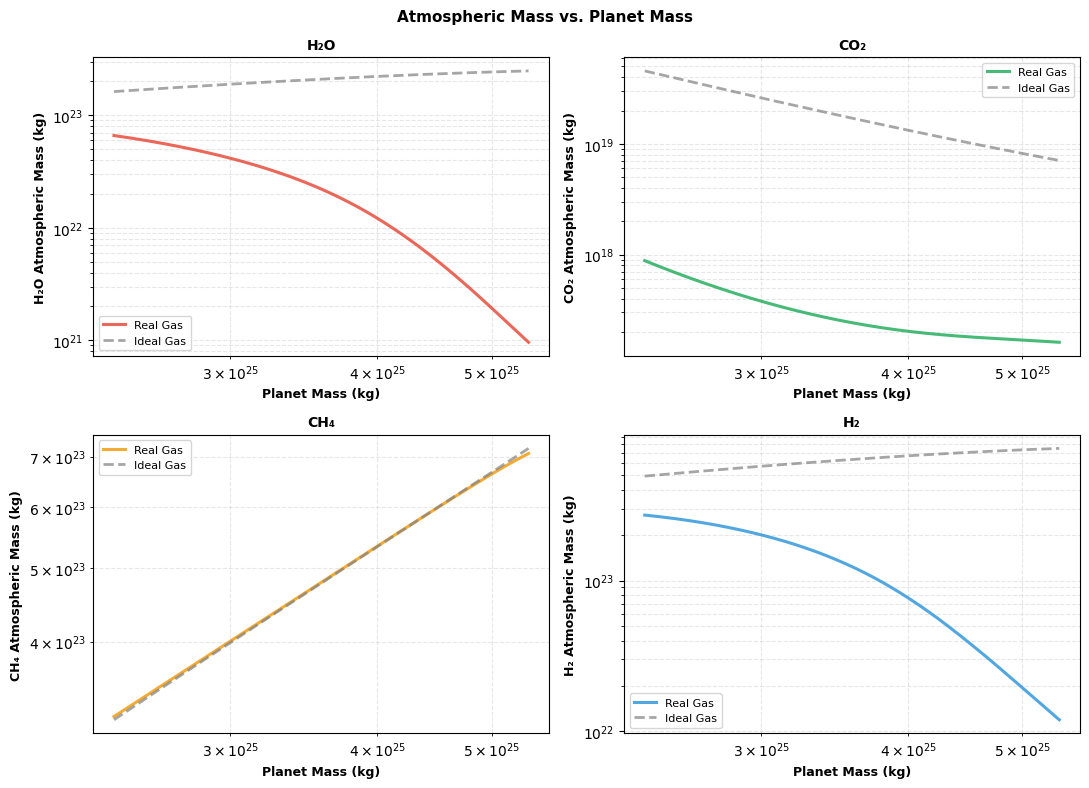

In [39]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Load data for varyMp
real_planet = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='planet')
real_h2o_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='H2O_g')
real_co2_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='CO2_g')
real_ch4_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='CH4_g')
real_h2_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='H2_g')

ideal_planet = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='planet')
ideal_h2o_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='H2O_g')
ideal_co2_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='CO2_g')
ideal_ch4_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='CH4_g')
ideal_h2_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='H2_g')

# Get planet mass
planet_mass_real = real_planet['planet_mass']

# Get atmosphere MASS (kg) instead of mixing ratio
real_h2o_mass = real_h2o_mp['atmosphere_mass']
real_co2_mass = real_co2_mp['atmosphere_mass']
real_ch4_mass = real_ch4_mp['atmosphere_mass']
real_h2_mass = real_h2_mp['atmosphere_mass']

ideal_h2o_mass = ideal_h2o_mp['atmosphere_mass']
ideal_co2_mass = ideal_co2_mp['atmosphere_mass']
ideal_ch4_mass = ideal_ch4_mp['atmosphere_mass']
ideal_h2_mass = ideal_h2_mp['atmosphere_mass']

# Create figure with 4 subplots
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes = axes.flatten()

species_data = [
    ('H₂O', real_h2o_mass, ideal_h2o_mass, '#E74C3C'),
    ('CO₂', real_co2_mass, ideal_co2_mass, '#27AE60'),
    ('CH₄', real_ch4_mass, ideal_ch4_mass, '#F39C12'),
    ('H₂', real_h2_mass, ideal_h2_mass, '#3498DB')
]

for idx, (name, real_mass, ideal_mass, color) in enumerate(species_data):
    ax = axes[idx]
    
    # Lines only (no markers)
    ax.plot(planet_mass_real, real_mass, '-', color=color, linewidth=2.2, 
            label='Real Gas', alpha=0.85)
    ax.plot(planet_mass_real, ideal_mass, '--', color='gray', linewidth=2, 
            label='Ideal Gas', alpha=0.7)
    
    ax.set_xscale('log')
    ax.set_yscale('log')
    
    ax.set_xlabel('Planet Mass (kg)', fontsize=9, fontweight='bold')
    ax.set_ylabel(f'{name} Atmospheric Mass (kg)', fontsize=9, fontweight='bold')
    ax.set_title(f'{name}', fontsize=10, fontweight='bold')
    
    ax.grid(True, alpha=0.3, linestyle='--', which='both')
    ax.legend(fontsize=8, loc='best')

plt.suptitle('Atmospheric Mass vs. Planet Mass', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('plot_bonus_atmosphere_mass_vs_planetmass.png', dpi=300, bbox_inches='tight')
plt.show()


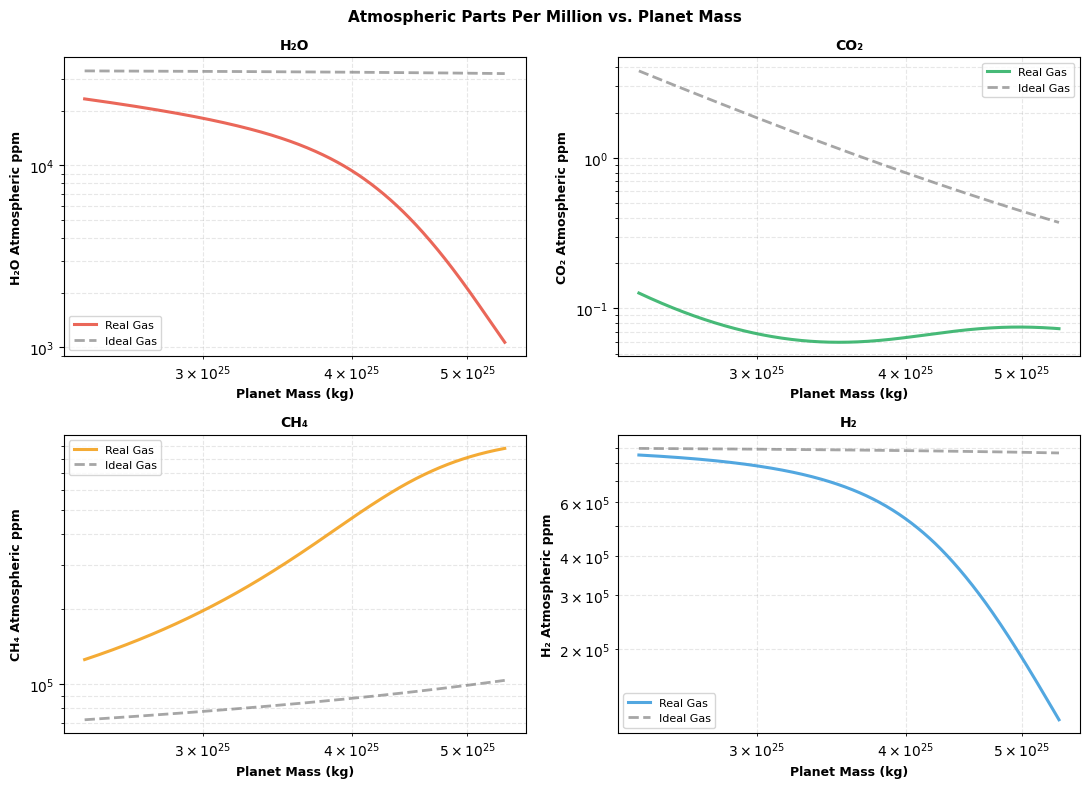

In [40]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Load data for varyMp
real_planet = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='planet')
real_h2o_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='H2O_g')
real_co2_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='CO2_g')
real_ch4_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='CH4_g')
real_h2_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='H2_g')

ideal_planet = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='planet')
ideal_h2o_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='H2O_g')
ideal_co2_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='CO2_g')
ideal_ch4_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='CH4_g')
ideal_h2_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='H2_g')

# Get planet mass
planet_mass_real = real_planet['planet_mass']
planet_mass_ideal = ideal_planet['planet_mass']

# Get atmospheric ppm
real_h2o_ppm = real_h2o_mp['atmosphere_ppm']
real_co2_ppm = real_co2_mp['atmosphere_ppm']
real_ch4_ppm = real_ch4_mp['atmosphere_ppm']
real_h2_ppm = real_h2_mp['atmosphere_ppm']

ideal_h2o_ppm = ideal_h2o_mp['atmosphere_ppm']
ideal_co2_ppm = ideal_co2_mp['atmosphere_ppm']
ideal_ch4_ppm = ideal_ch4_mp['atmosphere_ppm']
ideal_h2_ppm = ideal_h2_mp['atmosphere_ppm']

# Create figure with 4 subplots
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes = axes.flatten()

species_data = [
    ('H₂O', real_h2o_ppm, ideal_h2o_ppm, '#E74C3C'),
    ('CO₂', real_co2_ppm, ideal_co2_ppm, '#27AE60'),
    ('CH₄', real_ch4_ppm, ideal_ch4_ppm, '#F39C12'),
    ('H₂', real_h2_ppm, ideal_h2_ppm, '#3498DB')
]

# ✅ Fixed loop
for idx, (name, real_ppm, ideal_ppm, color) in enumerate(species_data):
    ax = axes[idx]
    
    # Plot lines correctly
    ax.plot(planet_mass_real, real_ppm, '-', color=color, linewidth=2.2, 
            label='Real Gas', alpha=0.85)
    ax.plot(planet_mass_ideal, ideal_ppm, '--', color='gray', linewidth=2, 
            label='Ideal Gas', alpha=0.7)
    
    ax.set_xscale('log')
    ax.set_yscale('log')
    
    ax.set_xlabel('Planet Mass (kg)', fontsize=9, fontweight='bold')
    ax.set_ylabel(f'{name} Atmospheric ppm', fontsize=9, fontweight='bold')
    ax.set_title(f'{name}', fontsize=10, fontweight='bold')
    
    ax.grid(True, alpha=0.3, linestyle='--', which='both')
    ax.legend(fontsize=8, loc='best')

plt.suptitle('Atmospheric Parts Per Million vs. Planet Mass', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('plot_bonus_atmosphere_mass_vs_planetmass.png', dpi=300, bbox_inches='tight')
plt.show()



Creating elemental budget plot vs. planet mass...

✓ Successfully saved: elemental_budget_vs_planet_mass.png


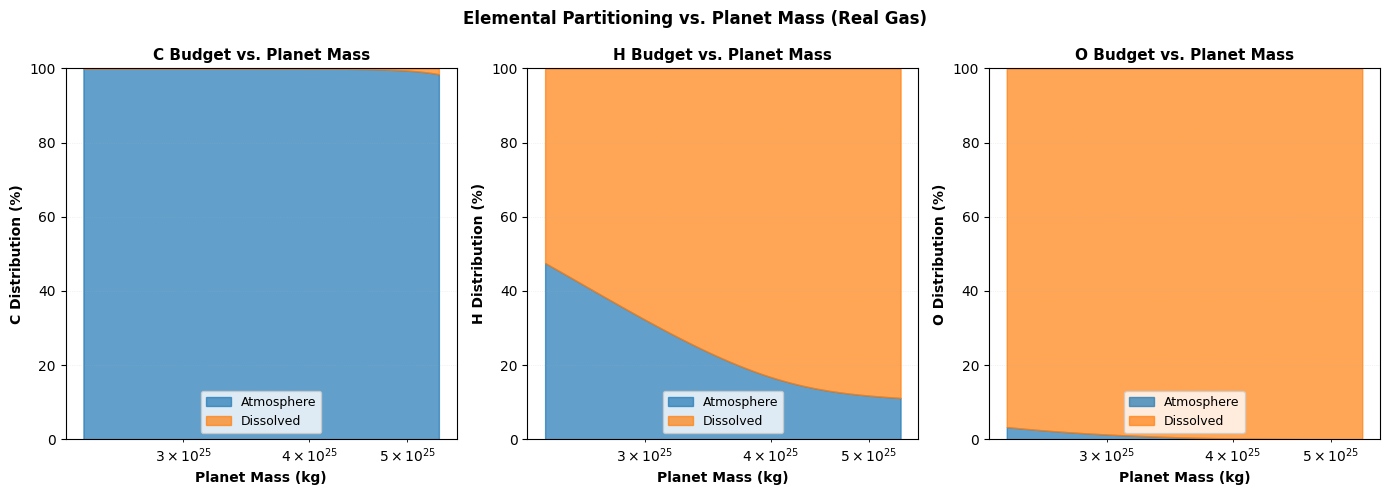

In [41]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def plot_elemental_budget_vs_mp(elements=('C', 'H', 'O')):
    
    print("\n" + "="*70)
    print("Creating elemental budget plot vs. planet mass...")
    print("="*70)
    
    # Load planet mass and elemental data for real gas
    real_planet = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='planet')
    planet_mass = real_planet['planet_mass']
    
    fig, axes = plt.subplots(1, 3, figsize=(14, 5))
    
    for idx, element in enumerate(elements):
        ax = axes[idx]
        sheet = f'element_{element}'
        df = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name=sheet)
        
        # Get mass components
        atm_mass = df.get('atmosphere_mass', pd.Series(np.zeros(len(df))))
        dis_mass = df.get('dissolved_mass', pd.Series(np.zeros(len(df))))
        con_mass = df.get('condensed_mass', pd.Series(np.zeros(len(df))))
        
        total_mass = atm_mass + dis_mass + con_mass
        
        # Avoid divide by zero
        total_mass[total_mass == 0] = np.nan
        
        atm_frac = atm_mass / total_mass * 100
        dis_frac = dis_mass / total_mass * 100
        con_frac = con_mass / total_mass * 100
        
        # Plot stacked area chart
        ax.fill_between(planet_mass, 0, atm_frac, label='Atmosphere', 
                       color='#1f77b4', alpha=0.7)
        ax.fill_between(planet_mass, atm_frac, atm_frac + dis_frac, 
                       label='Dissolved', color='#ff7f0e', alpha=0.7)
        if np.nanmax(con_frac) > 0:
            ax.fill_between(planet_mass, atm_frac + dis_frac, 100, 
                           label='Condensed', color='#2ca02c', alpha=0.7)
        
        ax.set_xscale('log')
        ax.set_ylim(0, 100)
        ax.set_xlabel('Planet Mass (kg)', fontsize=10, fontweight='bold')
        ax.set_ylabel(f'{element} Distribution (%)', fontsize=10, fontweight='bold')
        ax.set_title(f'{element} Budget vs. Planet Mass', fontsize=11, fontweight='bold')
        ax.legend(loc='best', frameon=True, fontsize=9)
        ax.grid(True, alpha=0.3, linestyle=':', linewidth=0.5)
    
    plt.suptitle('Elemental Partitioning vs. Planet Mass (Real Gas)', 
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig('elemental_budget_vs_planet_mass.png', dpi=300, bbox_inches='tight')
    print("\n✓ Successfully saved: elemental_budget_vs_planet_mass.png")
    plt.show()

# Run the function
plot_elemental_budget_vs_mp(elements=('C', 'H', 'O'))



Creating molecular budget plot vs. planet mass (Real vs. Ideal)...

✓ Successfully saved: molecular_budget_vs_planet_mass_real_vs_ideal.png


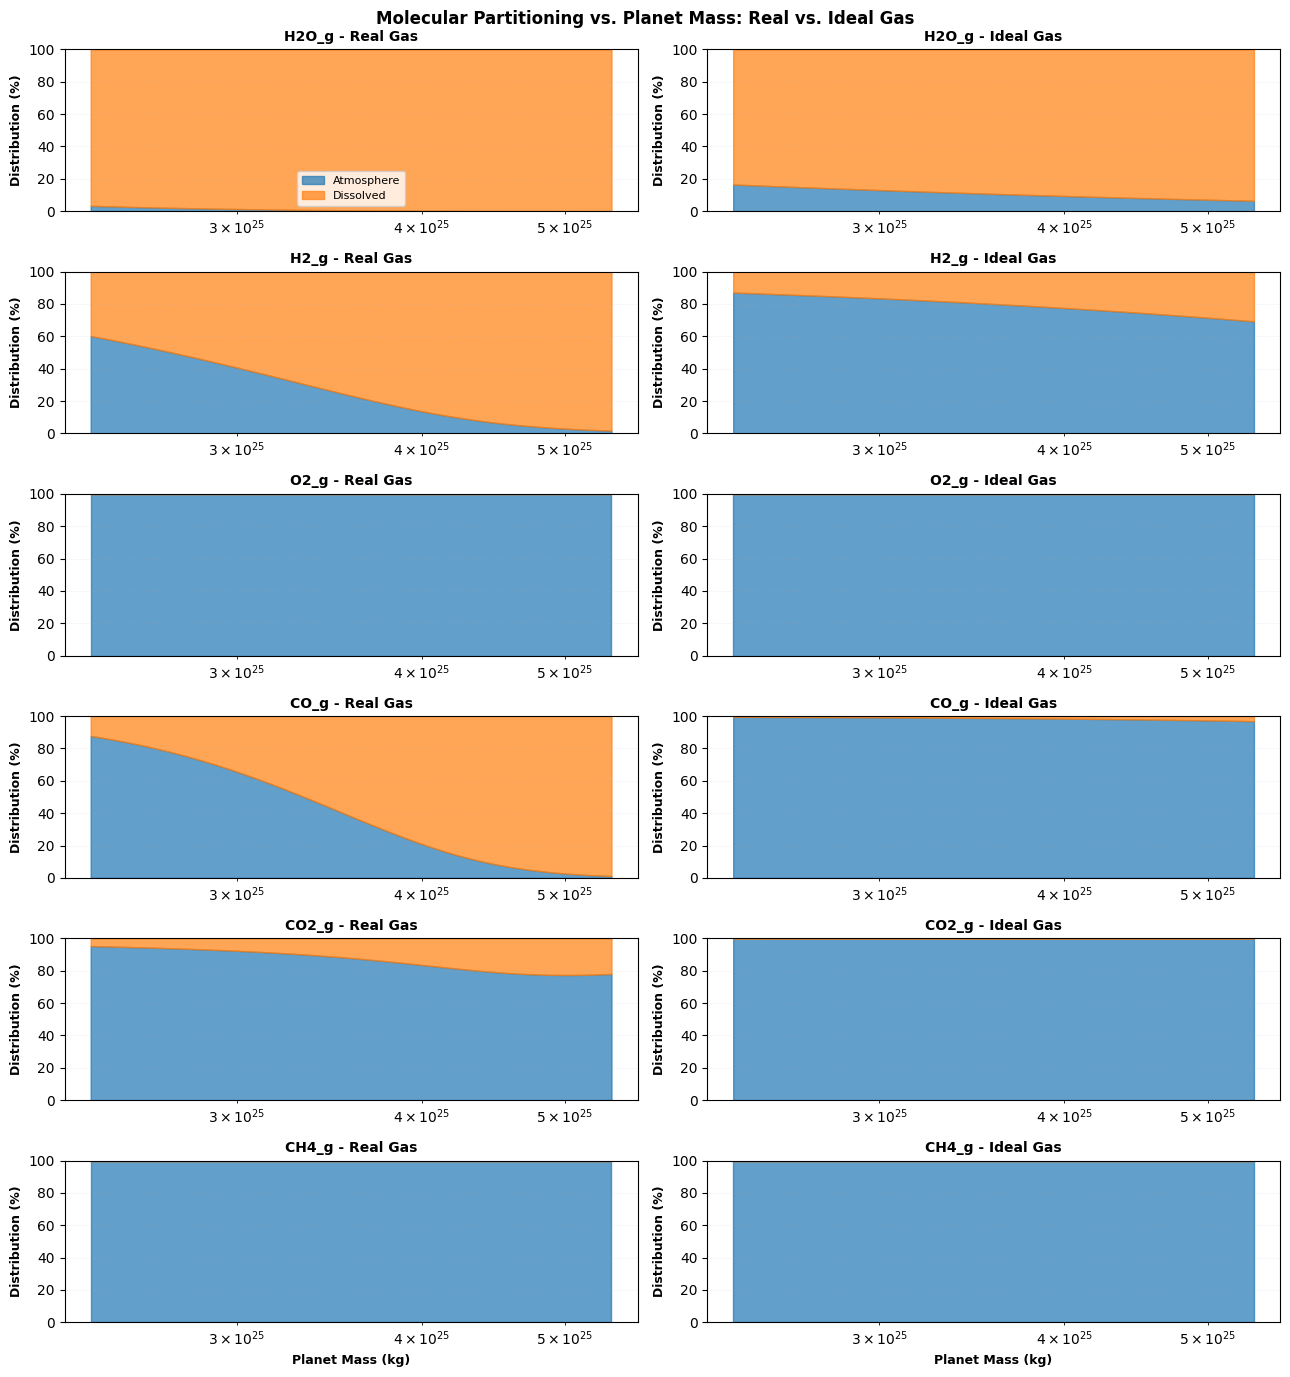

In [42]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def plot_molecular_budget_vs_mp_real_vs_ideal(molecules=('H2O_g', 'H2_g', 'O2_g', 'CO_g', 'CO2_g', 'CH4_g')):
    
    print("\n" + "="*70)
    print("Creating molecular budget plot vs. planet mass (Real vs. Ideal)...")
    print("="*70)
    
    # Load planet mass for both models
    real_planet = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='planet')
    ideal_planet = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='planet')
    
    planet_mass_real = real_planet['planet_mass']
    planet_mass_ideal = ideal_planet['planet_mass']
    
    # Create figure: 6 molecules, 2 columns (real vs ideal)
    fig, axes = plt.subplots(6, 2, figsize=(13, 14))
    
    for mol_idx, molecule in enumerate(molecules):
        # REAL GAS (left column)
        ax_real = axes[mol_idx, 0]
        df_real = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name=molecule)
        
        atm_mass_real = df_real.get('atmosphere_mass', pd.Series(np.zeros(len(df_real))))
        dis_mass_real = df_real.get('dissolved_mass', pd.Series(np.zeros(len(df_real))))
        con_mass_real = df_real.get('condensed_mass', pd.Series(np.zeros(len(df_real))))
        
        total_mass_real = atm_mass_real + dis_mass_real + con_mass_real
        total_mass_real[total_mass_real == 0] = np.nan
        
        atm_frac_real = atm_mass_real / total_mass_real * 100
        dis_frac_real = dis_mass_real / total_mass_real * 100
        con_frac_real = con_mass_real / total_mass_real * 100
        
        ax_real.fill_between(planet_mass_real, 0, atm_frac_real, label='Atmosphere', 
                            color='#1f77b4', alpha=0.7)
        ax_real.fill_between(planet_mass_real, atm_frac_real, atm_frac_real + dis_frac_real, 
                            label='Dissolved', color='#ff7f0e', alpha=0.7)
        if np.nanmax(con_frac_real) > 0:
            ax_real.fill_between(planet_mass_real, atm_frac_real + dis_frac_real, 100, 
                                label='Condensed', color='#2ca02c', alpha=0.7)
        
        ax_real.set_xscale('log')
        ax_real.set_ylim(0, 100)
        ax_real.set_ylabel('Distribution (%)', fontsize=9, fontweight='bold')
        ax_real.set_title(f'{molecule} - Real Gas', fontsize=10, fontweight='bold')
        if mol_idx == 0:
            ax_real.legend(loc='best', frameon=True, fontsize=8)
        ax_real.grid(True, alpha=0.3, linestyle=':', linewidth=0.5)
        
        # IDEAL GAS (right column)
        ax_ideal = axes[mol_idx, 1]
        df_ideal = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name=molecule)
        
        atm_mass_ideal = df_ideal.get('atmosphere_mass', pd.Series(np.zeros(len(df_ideal))))
        dis_mass_ideal = df_ideal.get('dissolved_mass', pd.Series(np.zeros(len(df_ideal))))
        con_mass_ideal = df_ideal.get('condensed_mass', pd.Series(np.zeros(len(df_ideal))))
        
        total_mass_ideal = atm_mass_ideal + dis_mass_ideal + con_mass_ideal
        total_mass_ideal[total_mass_ideal == 0] = np.nan
        
        atm_frac_ideal = atm_mass_ideal / total_mass_ideal * 100
        dis_frac_ideal = dis_mass_ideal / total_mass_ideal * 100
        con_frac_ideal = con_mass_ideal / total_mass_ideal * 100
        
        ax_ideal.fill_between(planet_mass_ideal, 0, atm_frac_ideal, label='Atmosphere', 
                             color='#1f77b4', alpha=0.7)
        ax_ideal.fill_between(planet_mass_ideal, atm_frac_ideal, atm_frac_ideal + dis_frac_ideal, 
                             label='Dissolved', color='#ff7f0e', alpha=0.7)
        if np.nanmax(con_frac_ideal) > 0:
            ax_ideal.fill_between(planet_mass_ideal, atm_frac_ideal + dis_frac_ideal, 100, 
                                 label='Condensed', color='#2ca02c', alpha=0.7)
        
        ax_ideal.set_xscale('log')
        ax_ideal.set_ylim(0, 100)
        ax_ideal.set_ylabel('Distribution (%)', fontsize=9, fontweight='bold')
        ax_ideal.set_title(f'{molecule} - Ideal Gas', fontsize=10, fontweight='bold')
        ax_ideal.grid(True, alpha=0.3, linestyle=':', linewidth=0.5)
        
        # Set x-label only on bottom row
        if mol_idx == 5:
            ax_real.set_xlabel('Planet Mass (kg)', fontsize=9, fontweight='bold')
            ax_ideal.set_xlabel('Planet Mass (kg)', fontsize=9, fontweight='bold')
    
    plt.suptitle('Molecular Partitioning vs. Planet Mass: Real vs. Ideal Gas', 
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig('molecular_budget_vs_planet_mass_real_vs_ideal.png', dpi=300, bbox_inches='tight')
    print("\n✓ Successfully saved: molecular_budget_vs_planet_mass_real_vs_ideal.png")
    plt.show()

# Run the function
plot_molecular_budget_vs_mp_real_vs_ideal(molecules=('H2O_g', 'H2_g', 'O2_g', 'CO_g', 'CO2_g', 'CH4_g'))



Creating molecular budget plot vs. planet mass (Real vs. Ideal)...

✓ Successfully saved: molecular_budget_vs_planet_mass_real_vs_ideal.png


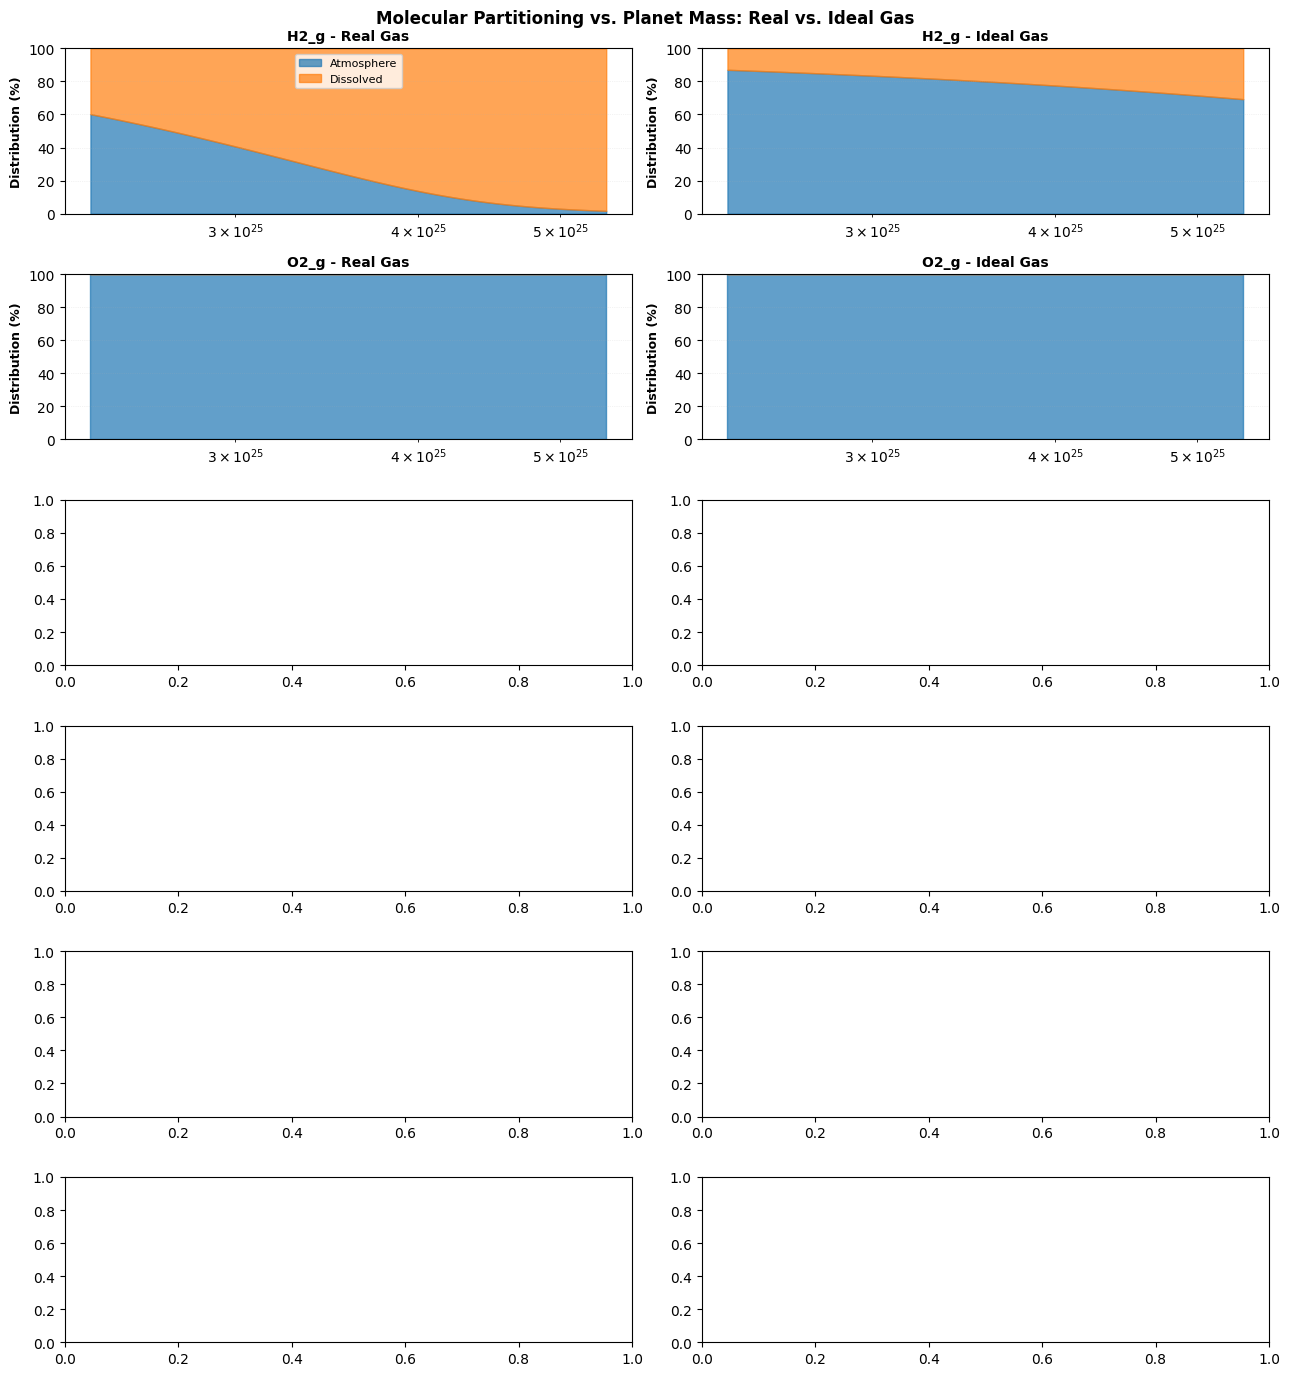

In [43]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def plot_molecular_budget_vs_mp_real_vs_ideal(molecules=('H2_g', 'O2_g')):
    
    print("\n" + "="*70)
    print("Creating molecular budget plot vs. planet mass (Real vs. Ideal)...")
    print("="*70)
    
    # Load planet mass for both models
    real_planet = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='planet')
    ideal_planet = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='planet')
    
    planet_mass_real = real_planet['planet_mass']
    planet_mass_ideal = ideal_planet['planet_mass']
    
    # Create figure: 6 molecules, 2 columns (real vs ideal)
    fig, axes = plt.subplots(6, 2, figsize=(13, 14))
    
    for mol_idx, molecule in enumerate(molecules):
        # REAL GAS (left column)
        ax_real = axes[mol_idx, 0]
        df_real = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name=molecule)
        
        atm_mass_real = df_real.get('atmosphere_mass', pd.Series(np.zeros(len(df_real))))
        dis_mass_real = df_real.get('dissolved_mass', pd.Series(np.zeros(len(df_real))))
        con_mass_real = df_real.get('condensed_mass', pd.Series(np.zeros(len(df_real))))
        
        total_mass_real = atm_mass_real + dis_mass_real + con_mass_real
        total_mass_real[total_mass_real == 0] = np.nan
        
        atm_frac_real = atm_mass_real / total_mass_real * 100
        dis_frac_real = dis_mass_real / total_mass_real * 100
        con_frac_real = con_mass_real / total_mass_real * 100
        
        ax_real.fill_between(planet_mass_real, 0, atm_frac_real, label='Atmosphere', 
                            color='#1f77b4', alpha=0.7)
        ax_real.fill_between(planet_mass_real, atm_frac_real, atm_frac_real + dis_frac_real, 
                            label='Dissolved', color='#ff7f0e', alpha=0.7)
        if np.nanmax(con_frac_real) > 0:
            ax_real.fill_between(planet_mass_real, atm_frac_real + dis_frac_real, 100, 
                                label='Condensed', color='#2ca02c', alpha=0.7)
        
        ax_real.set_xscale('log')
        ax_real.set_ylim(0, 100)
        ax_real.set_ylabel('Distribution (%)', fontsize=9, fontweight='bold')
        ax_real.set_title(f'{molecule} - Real Gas', fontsize=10, fontweight='bold')
        if mol_idx == 0:
            ax_real.legend(loc='best', frameon=True, fontsize=8)
        ax_real.grid(True, alpha=0.3, linestyle=':', linewidth=0.5)
        
        # IDEAL GAS (right column)
        ax_ideal = axes[mol_idx, 1]
        df_ideal = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name=molecule)
        
        atm_mass_ideal = df_ideal.get('atmosphere_mass', pd.Series(np.zeros(len(df_ideal))))
        dis_mass_ideal = df_ideal.get('dissolved_mass', pd.Series(np.zeros(len(df_ideal))))
        con_mass_ideal = df_ideal.get('condensed_mass', pd.Series(np.zeros(len(df_ideal))))
        
        total_mass_ideal = atm_mass_ideal + dis_mass_ideal + con_mass_ideal
        total_mass_ideal[total_mass_ideal == 0] = np.nan
        
        atm_frac_ideal = atm_mass_ideal / total_mass_ideal * 100
        dis_frac_ideal = dis_mass_ideal / total_mass_ideal * 100
        con_frac_ideal = con_mass_ideal / total_mass_ideal * 100
        
        ax_ideal.fill_between(planet_mass_ideal, 0, atm_frac_ideal, label='Atmosphere', 
                             color='#1f77b4', alpha=0.7)
        ax_ideal.fill_between(planet_mass_ideal, atm_frac_ideal, atm_frac_ideal + dis_frac_ideal, 
                             label='Dissolved', color='#ff7f0e', alpha=0.7)
        if np.nanmax(con_frac_ideal) > 0:
            ax_ideal.fill_between(planet_mass_ideal, atm_frac_ideal + dis_frac_ideal, 100, 
                                 label='Condensed', color='#2ca02c', alpha=0.7)
        
        ax_ideal.set_xscale('log')
        ax_ideal.set_ylim(0, 100)
        ax_ideal.set_ylabel('Distribution (%)', fontsize=9, fontweight='bold')
        ax_ideal.set_title(f'{molecule} - Ideal Gas', fontsize=10, fontweight='bold')
        ax_ideal.grid(True, alpha=0.3, linestyle=':', linewidth=0.5)
        
        # Set x-label only on bottom row
        if mol_idx == 5:
            ax_real.set_xlabel('Planet Mass (kg)', fontsize=9, fontweight='bold')
            ax_ideal.set_xlabel('Planet Mass (kg)', fontsize=9, fontweight='bold')
    
    plt.suptitle('Molecular Partitioning vs. Planet Mass: Real vs. Ideal Gas', 
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig('molecular_budget_vs_planet_mass_real_vs_ideal.png', dpi=300, bbox_inches='tight')
    print("\n✓ Successfully saved: molecular_budget_vs_planet_mass_real_vs_ideal.png")
    plt.show()

# Run the function
plot_molecular_budget_vs_mp_real_vs_ideal(molecules=('H2_g', 'O2_g'))


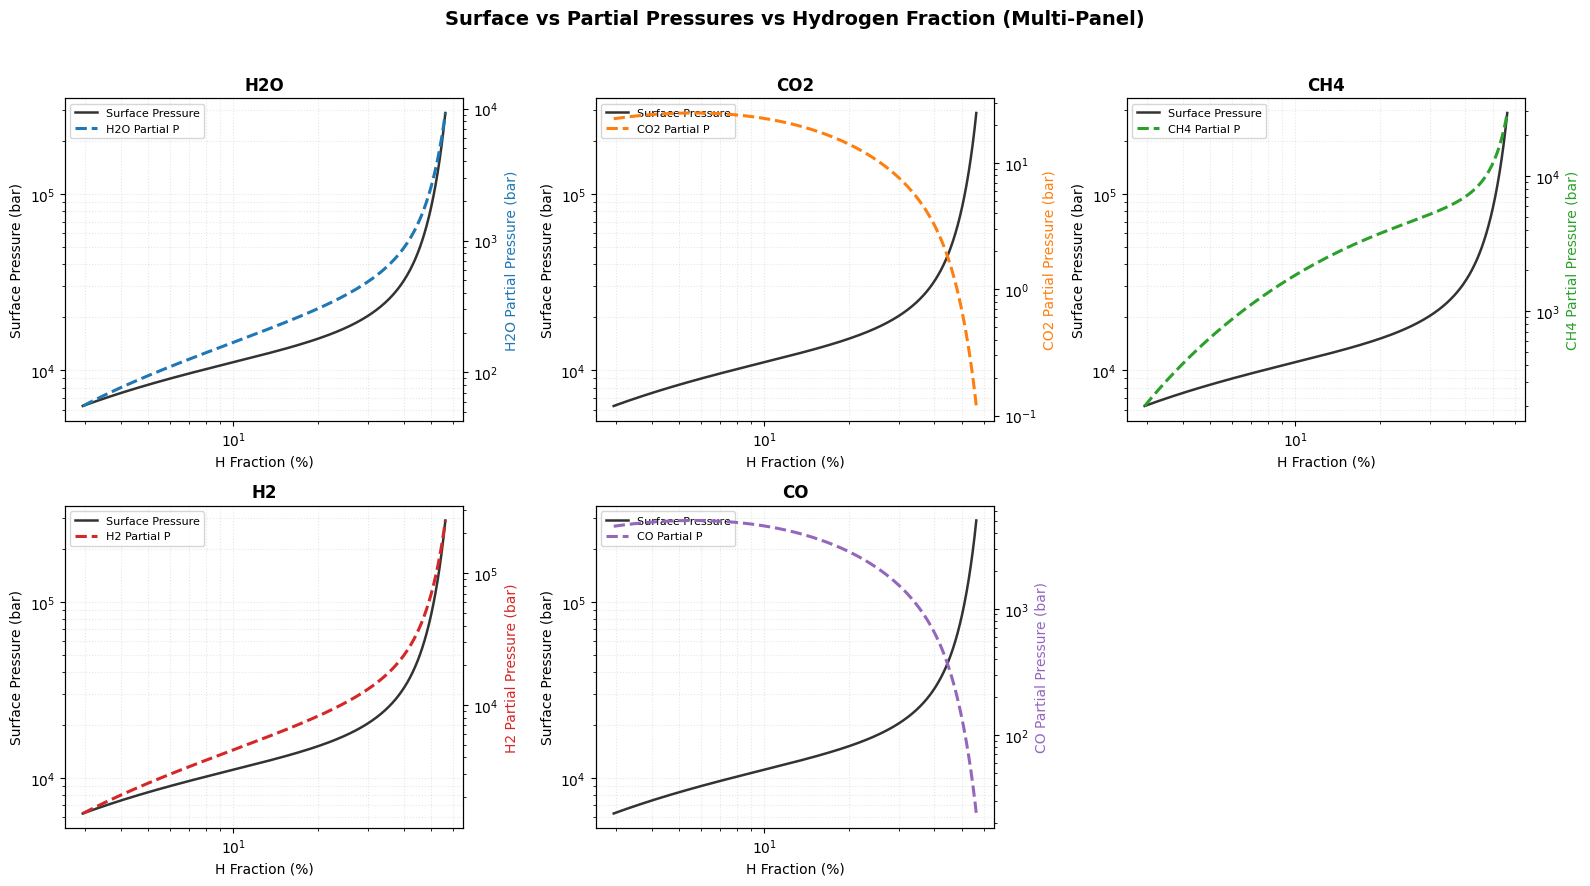

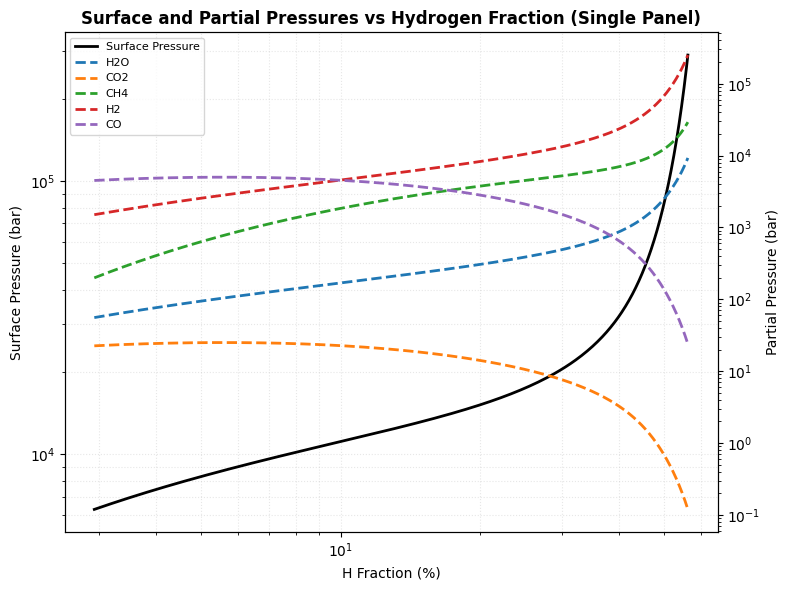


✓ Saved both figures: 'partial_pressures_multi_panel.png' and 'partial_pressures_single_panel.png'


In [44]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# === File and species list ===
excel_file = "sub_neptune_ideal_withsol_varyHF.xlsx"
species = ['H2O_g', 'CO2_g', 'CH4_g', 'H2_g', 'CO_g']

# === Load base data for axes ===
df_H = pd.read_excel(excel_file, sheet_name='element_H')
df_atm = pd.read_excel(excel_file, sheet_name='atmosphere')

# Hydrogen fraction (x-axis)
x = df_H['atmosphere_ppmw'] / 1e4
# Total surface pressure (bar)
P_surf = df_atm['pressure']

# === Colors ===
cmap = plt.cm.tab10.colors

# -------------------------------------------------------------
# 1️⃣ MULTI-PANEL FIGURE (one per gas)
# -------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, sp in enumerate(species):
    ax = axes[i]
    color = cmap[i % len(cmap)]

    try:
        df_gas = pd.read_excel(excel_file, sheet_name=sp)
    except ValueError:
        print(f"⚠️ Sheet '{sp}' not found, skipping.")
        continue

    if 'pressure' not in df_gas.columns:
        print(f"⚠️ No 'pressure' column in '{sp}', skipping.")
        continue

    y_partial = df_gas['pressure']

    # --- Left y-axis: total surface pressure ---
    ax.plot(x, P_surf, '-', color='k', lw=1.8, alpha=0.8, label='Surface Pressure')

    # --- Right y-axis: partial pressure of species ---
    ax2 = ax.twinx()
    ax2.plot(x, y_partial, '--', color=color, lw=2.2, label=f'{sp.replace("_g", "").upper()} Partial P')

    # --- Axes formatting ---
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax2.set_yscale('log')

    ax.set_xlabel('H Fraction (%)')
    ax.set_ylabel('Surface Pressure (bar)', color='k')
    ax2.set_ylabel(f'{sp.replace("_g", "").upper()} Partial Pressure (bar)', color=color)

    ax.set_title(sp.replace('_g', '').upper(), fontweight='bold')
    ax.grid(True, alpha=0.3, linestyle=':', which='both')

    # --- Legends ---
    lines, labels = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines + lines2, labels + labels2, fontsize=8, loc='best')

# Remove extra axes
for j in range(len(species), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Surface vs Partial Pressures vs Hydrogen Fraction (Multi-Panel)',
             fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('partial_pressures_multi_panel.png', dpi=300, bbox_inches='tight')
plt.show()

# -------------------------------------------------------------
# 2️⃣ SINGLE-PANEL FIGURE (all gases together)
# -------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 6))

# Left y-axis: total surface pressure
ax.plot(x, P_surf, 'k-', lw=2, label='Surface Pressure')

# Right y-axis: partial pressures
ax2 = ax.twinx()
for i, sp in enumerate(species):
    try:
        df_gas = pd.read_excel(excel_file, sheet_name=sp)
        if 'pressure' not in df_gas.columns:
            continue
        ax2.plot(x, df_gas['pressure'], '--', lw=2, color=cmap[i % len(cmap)],
                 label=sp.replace('_g', '').upper())
    except ValueError:
        continue

# --- Axes scaling ---
ax.set_xscale('log')
ax.set_yscale('log')
ax2.set_yscale('log')

# --- Labels and titles ---
ax.set_xlabel('H Fraction (%)')
ax.set_ylabel('Surface Pressure (bar)', color='k')
ax2.set_ylabel('Partial Pressure (bar)')
ax.set_title('Surface and Partial Pressures vs Hydrogen Fraction (Single Panel)',
             fontweight='bold')

# --- Legends ---
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines + lines2, labels + labels2, fontsize=8, loc='best')

ax.grid(True, alpha=0.3, linestyle=':', which='both')

plt.tight_layout()
plt.savefig('partial_pressures_single_panel.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Saved both figures: 'partial_pressures_multi_panel.png' and 'partial_pressures_single_panel.png'")


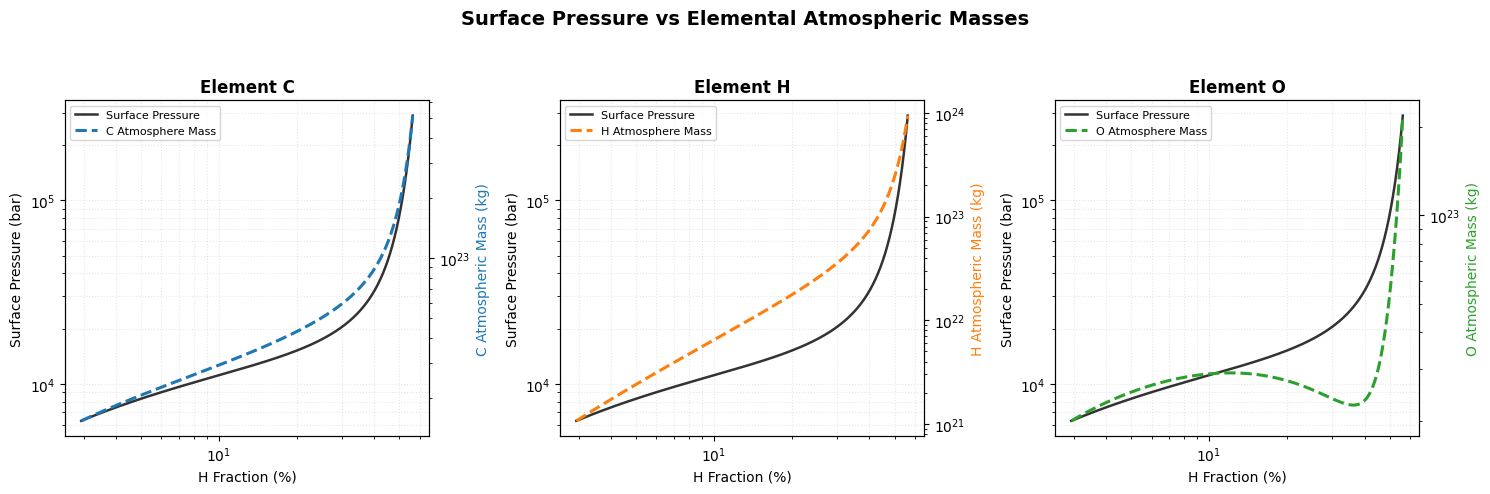

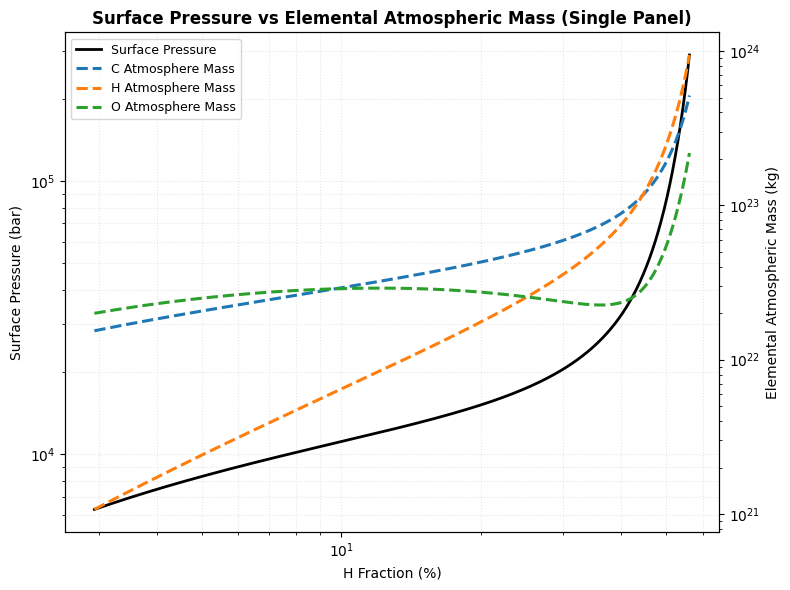


✓ Saved both figures: 'elemental_surface_pressure_multi_panel.png' and 'elemental_surface_pressure_single_panel.png'


In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# === File and element list ===
excel_file = "sub_neptune_ideal_withsol_varyHF.xlsx"
elements = ['C', 'H', 'O']

# === Load base data for axes ===
df_H = pd.read_excel(excel_file, sheet_name='element_H')
df_atm = pd.read_excel(excel_file, sheet_name='atmosphere')

# Hydrogen fraction (x-axis)
x = df_H['atmosphere_ppmw'] / 1e4
# Total surface pressure (bar)
P_surf = df_atm['pressure']

# === Colors ===
cmap = plt.cm.tab10.colors
element_colors = {'C': cmap[0], 'H': cmap[1], 'O': cmap[2]}

# -------------------------------------------------------------
# 1️⃣ MULTI-PANEL FIGURE (one per element)
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes = axes.flatten()

for i, elem in enumerate(elements):
    ax = axes[i]
    color = element_colors[elem]

    try:
        df_elem = pd.read_excel(excel_file, sheet_name=f'element_{elem}')
    except ValueError:
        print(f"⚠️ Sheet for element '{elem}' not found, skipping.")
        continue

    # Use atmosphere_mass as a proxy for partial pressure fraction
    if 'atmosphere_mass' not in df_elem.columns:
        print(f"⚠️ No 'atmosphere_mass' in element_{elem}, skipping.")
        continue

    # Element gas-phase mass (in bar equivalent units is fine relative)
    y_elem = df_elem['atmosphere_mass']

    # --- Left y-axis: surface pressure ---
    ax.plot(x, P_surf, '-', color='k', lw=1.8, alpha=0.8, label='Surface Pressure')

    # --- Right y-axis: element contribution ---
    ax2 = ax.twinx()
    ax2.plot(x, y_elem, '--', color=color, lw=2.2, label=f'{elem} Atmosphere Mass')

    # --- Axes formatting ---
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax2.set_yscale('log')

    ax.set_xlabel('H Fraction (%)')
    ax.set_ylabel('Surface Pressure (bar)', color='k')
    ax2.set_ylabel(f'{elem} Atmospheric Mass (kg)', color=color)
    ax.set_title(f'Element {elem}', fontweight='bold')

    ax.grid(True, alpha=0.3, linestyle=':', which='both')

    # --- Legends ---
    lines, labels = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines + lines2, labels + labels2, fontsize=8, loc='best')

plt.suptitle('Surface Pressure vs Elemental Atmospheric Masses',
             fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig('elemental_surface_pressure_multi_panel.png', dpi=300, bbox_inches='tight')
plt.show()

# -------------------------------------------------------------
# 2️⃣ SINGLE-PANEL FIGURE (all elements together)
# -------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 6))

# Left y-axis: total surface pressure
ax.plot(x, P_surf, 'k-', lw=2, label='Surface Pressure')

# Right y-axis: element atmospheric masses
ax2 = ax.twinx()
for elem in elements:
    try:
        df_elem = pd.read_excel(excel_file, sheet_name=f'element_{elem}')
        if 'atmosphere_mass' not in df_elem.columns:
            continue
        ax2.plot(x, df_elem['atmosphere_mass'], '--', lw=2.2,
                 color=element_colors[elem], label=f'{elem} Atmosphere Mass')
    except ValueError:
        continue

# --- Axes scaling ---
ax.set_xscale('log')
ax.set_yscale('log')
ax2.set_yscale('log')

# --- Labels and title ---
ax.set_xlabel('H Fraction (%)')
ax.set_ylabel('Surface Pressure (bar)', color='k')
ax2.set_ylabel('Elemental Atmospheric Mass (kg)')
ax.set_title('Surface Pressure vs Elemental Atmospheric Mass (Single Panel)',
             fontweight='bold')

# --- Legends ---
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines + lines2, labels + labels2, fontsize=9, loc='best')

ax.grid(True, alpha=0.3, linestyle=':', which='both')

plt.tight_layout()
plt.savefig('elemental_surface_pressure_single_panel.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Saved both figures: 'elemental_surface_pressure_multi_panel.png' and 'elemental_surface_pressure_single_panel.png'")


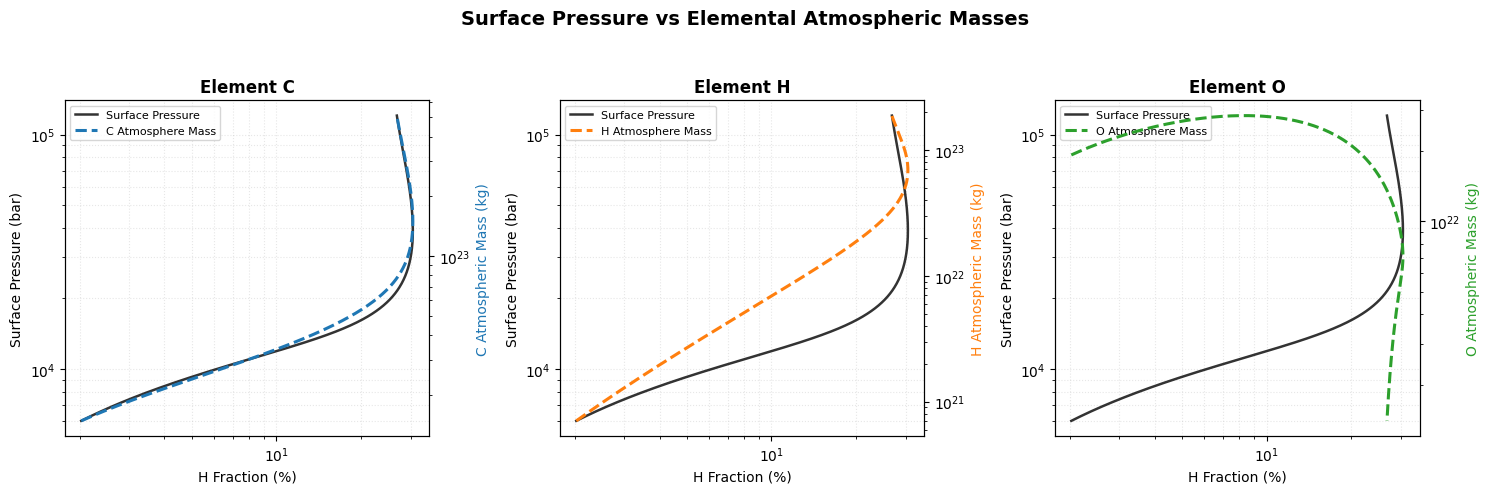

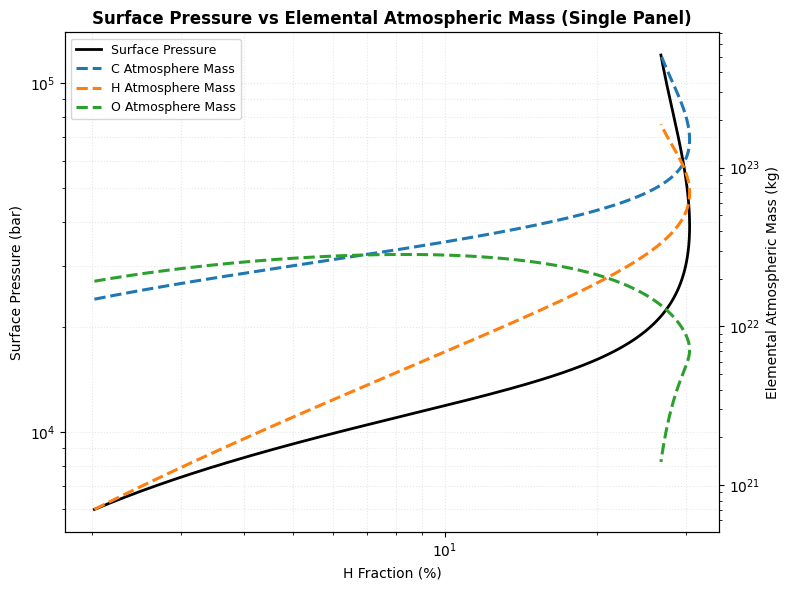


✓ Saved both figures: 'elemental_surface_pressure_multi_panel.png' and 'elemental_surface_pressure_single_panel.png'


In [46]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# === File and element list ===
excel_file = "sub_neptune_real_withsol_varyHF.xlsx"
elements = ['C', 'H', 'O']

# === Load base data for axes ===
df_H = pd.read_excel(excel_file, sheet_name='element_H')
df_atm = pd.read_excel(excel_file, sheet_name='atmosphere')

# Hydrogen fraction (x-axis)
x = df_H['atmosphere_ppmw'] / 1e4
# Total surface pressure (bar)
P_surf = df_atm['pressure']

# === Colors ===
cmap = plt.cm.tab10.colors
element_colors = {'C': cmap[0], 'H': cmap[1], 'O': cmap[2]}

# -------------------------------------------------------------
# 1️⃣ MULTI-PANEL FIGURE (one per element)
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes = axes.flatten()

for i, elem in enumerate(elements):
    ax = axes[i]
    color = element_colors[elem]

    try:
        df_elem = pd.read_excel(excel_file, sheet_name=f'element_{elem}')
    except ValueError:
        print(f"⚠️ Sheet for element '{elem}' not found, skipping.")
        continue

    # Use atmosphere_mass as a proxy for partial pressure fraction
    if 'atmosphere_mass' not in df_elem.columns:
        print(f"⚠️ No 'atmosphere_mass' in element_{elem}, skipping.")
        continue

    # Element gas-phase mass (in bar equivalent units is fine relative)
    y_elem = df_elem['atmosphere_mass']

    # --- Left y-axis: surface pressure ---
    ax.plot(x, P_surf, '-', color='k', lw=1.8, alpha=0.8, label='Surface Pressure')

    # --- Right y-axis: element contribution ---
    ax2 = ax.twinx()
    ax2.plot(x, y_elem, '--', color=color, lw=2.2, label=f'{elem} Atmosphere Mass')

    # --- Axes formatting ---
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax2.set_yscale('log')

    ax.set_xlabel('H Fraction (%)')
    ax.set_ylabel('Surface Pressure (bar)', color='k')
    ax2.set_ylabel(f'{elem} Atmospheric Mass (kg)', color=color)
    ax.set_title(f'Element {elem}', fontweight='bold')

    ax.grid(True, alpha=0.3, linestyle=':', which='both')

    # --- Legends ---
    lines, labels = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines + lines2, labels + labels2, fontsize=8, loc='best')

plt.suptitle('Surface Pressure vs Elemental Atmospheric Masses',
             fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig('elemental_surface_pressure_multi_panel.png', dpi=300, bbox_inches='tight')
plt.show()

# -------------------------------------------------------------
# 2️⃣ SINGLE-PANEL FIGURE (all elements together)
# -------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 6))

# Left y-axis: total surface pressure
ax.plot(x, P_surf, 'k-', lw=2, label='Surface Pressure')

# Right y-axis: element atmospheric masses
ax2 = ax.twinx()
for elem in elements:
    try:
        df_elem = pd.read_excel(excel_file, sheet_name=f'element_{elem}')
        if 'atmosphere_mass' not in df_elem.columns:
            continue
        ax2.plot(x, df_elem['atmosphere_mass'], '--', lw=2.2,
                 color=element_colors[elem], label=f'{elem} Atmosphere Mass')
    except ValueError:
        continue

# --- Axes scaling ---
ax.set_xscale('log')
ax.set_yscale('log')
ax2.set_yscale('log')

# --- Labels and title ---
ax.set_xlabel('H Fraction (%)')
ax.set_ylabel('Surface Pressure (bar)', color='k')
ax2.set_ylabel('Elemental Atmospheric Mass (kg)')
ax.set_title('Surface Pressure vs Elemental Atmospheric Mass (Single Panel)',
             fontweight='bold')

# --- Legends ---
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines + lines2, labels + labels2, fontsize=9, loc='best')

ax.grid(True, alpha=0.3, linestyle=':', which='both')

plt.tight_layout()
plt.savefig('elemental_surface_pressure_single_panel.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Saved both figures: 'elemental_surface_pressure_multi_panel.png' and 'elemental_surface_pressure_single_panel.png'")


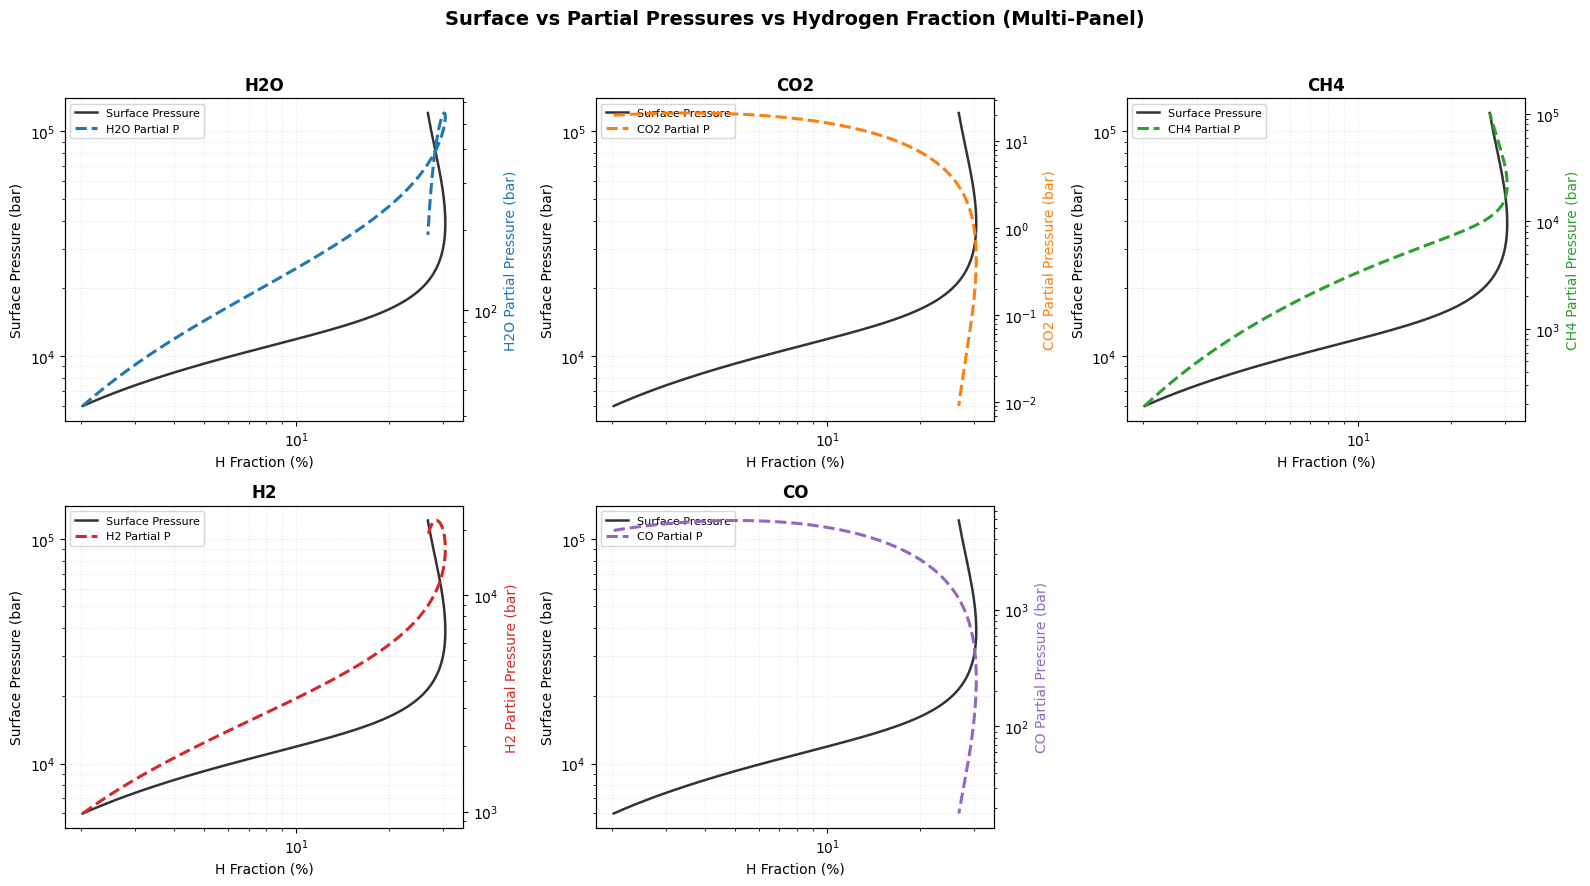

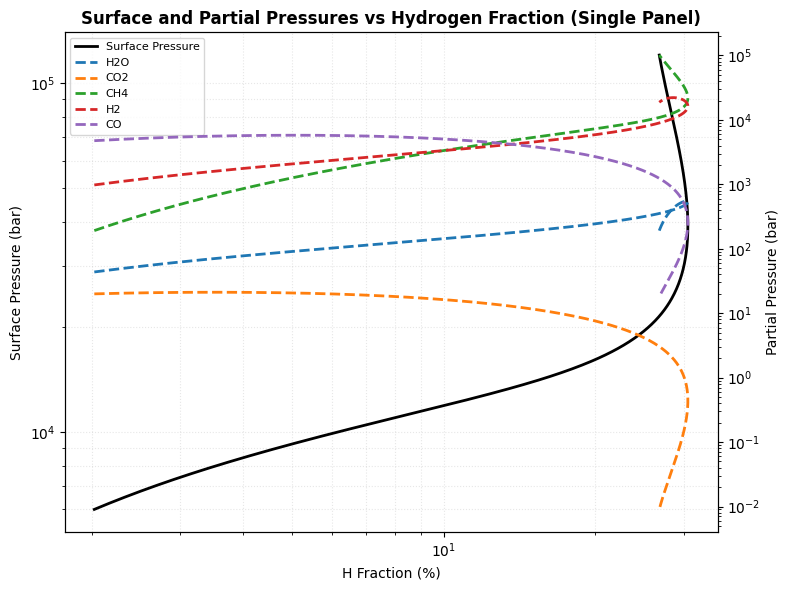


✓ Saved both figures: 'partial_pressures_multi_panel.png' and 'partial_pressures_single_panel.png'


In [47]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# === File and species list ===
excel_file = "sub_neptune_real_withsol_varyHF.xlsx"
species = ['H2O_g', 'CO2_g', 'CH4_g', 'H2_g', 'CO_g']

# === Load base data for axes ===
df_H = pd.read_excel(excel_file, sheet_name='element_H')
df_atm = pd.read_excel(excel_file, sheet_name='atmosphere')

# Hydrogen fraction (x-axis)
x = df_H['atmosphere_ppmw'] / 1e4
# Total surface pressure (bar)
P_surf = df_atm['pressure']

# === Colors ===
cmap = plt.cm.tab10.colors

# -------------------------------------------------------------
# 1️⃣ MULTI-PANEL FIGURE (one per gas)
# -------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, sp in enumerate(species):
    ax = axes[i]
    color = cmap[i % len(cmap)]

    try:
        df_gas = pd.read_excel(excel_file, sheet_name=sp)
    except ValueError:
        print(f"⚠️ Sheet '{sp}' not found, skipping.")
        continue

    if 'pressure' not in df_gas.columns:
        print(f"⚠️ No 'pressure' column in '{sp}', skipping.")
        continue

    y_partial = df_gas['pressure']

    # --- Left y-axis: total surface pressure ---
    ax.plot(x, P_surf, '-', color='k', lw=1.8, alpha=0.8, label='Surface Pressure')

    # --- Right y-axis: partial pressure of species ---
    ax2 = ax.twinx()
    ax2.plot(x, y_partial, '--', color=color, lw=2.2, label=f'{sp.replace("_g", "").upper()} Partial P')

    # --- Axes formatting ---
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax2.set_yscale('log')

    ax.set_xlabel('H Fraction (%)')
    ax.set_ylabel('Surface Pressure (bar)', color='k')
    ax2.set_ylabel(f'{sp.replace("_g", "").upper()} Partial Pressure (bar)', color=color)

    ax.set_title(sp.replace('_g', '').upper(), fontweight='bold')
    ax.grid(True, alpha=0.3, linestyle=':', which='both')

    # --- Legends ---
    lines, labels = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines + lines2, labels + labels2, fontsize=8, loc='best')

# Remove extra axes
for j in range(len(species), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Surface vs Partial Pressures vs Hydrogen Fraction (Multi-Panel)',
             fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('partial_pressures_multi_panel.png', dpi=300, bbox_inches='tight')
plt.show()

# -------------------------------------------------------------
# 2️⃣ SINGLE-PANEL FIGURE (all gases together)
# -------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 6))

# Left y-axis: total surface pressure
ax.plot(x, P_surf, 'k-', lw=2, label='Surface Pressure')

# Right y-axis: partial pressures
ax2 = ax.twinx()
for i, sp in enumerate(species):
    try:
        df_gas = pd.read_excel(excel_file, sheet_name=sp)
        if 'pressure' not in df_gas.columns:
            continue
        ax2.plot(x, df_gas['pressure'], '--', lw=2, color=cmap[i % len(cmap)],
                 label=sp.replace('_g', '').upper())
    except ValueError:
        continue

# --- Axes scaling ---
ax.set_xscale('log')
ax.set_yscale('log')
ax2.set_yscale('log')

# --- Labels and titles ---
ax.set_xlabel('H Fraction (%)')
ax.set_ylabel('Surface Pressure (bar)', color='k')
ax2.set_ylabel('Partial Pressure (bar)')
ax.set_title('Surface and Partial Pressures vs Hydrogen Fraction (Single Panel)',
             fontweight='bold')

# --- Legends ---
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines + lines2, labels + labels2, fontsize=8, loc='best')

ax.grid(True, alpha=0.3, linestyle=':', which='both')

plt.tight_layout()
plt.savefig('partial_pressures_single_panel.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Saved both figures: 'partial_pressures_multi_panel.png' and 'partial_pressures_single_panel.png'")


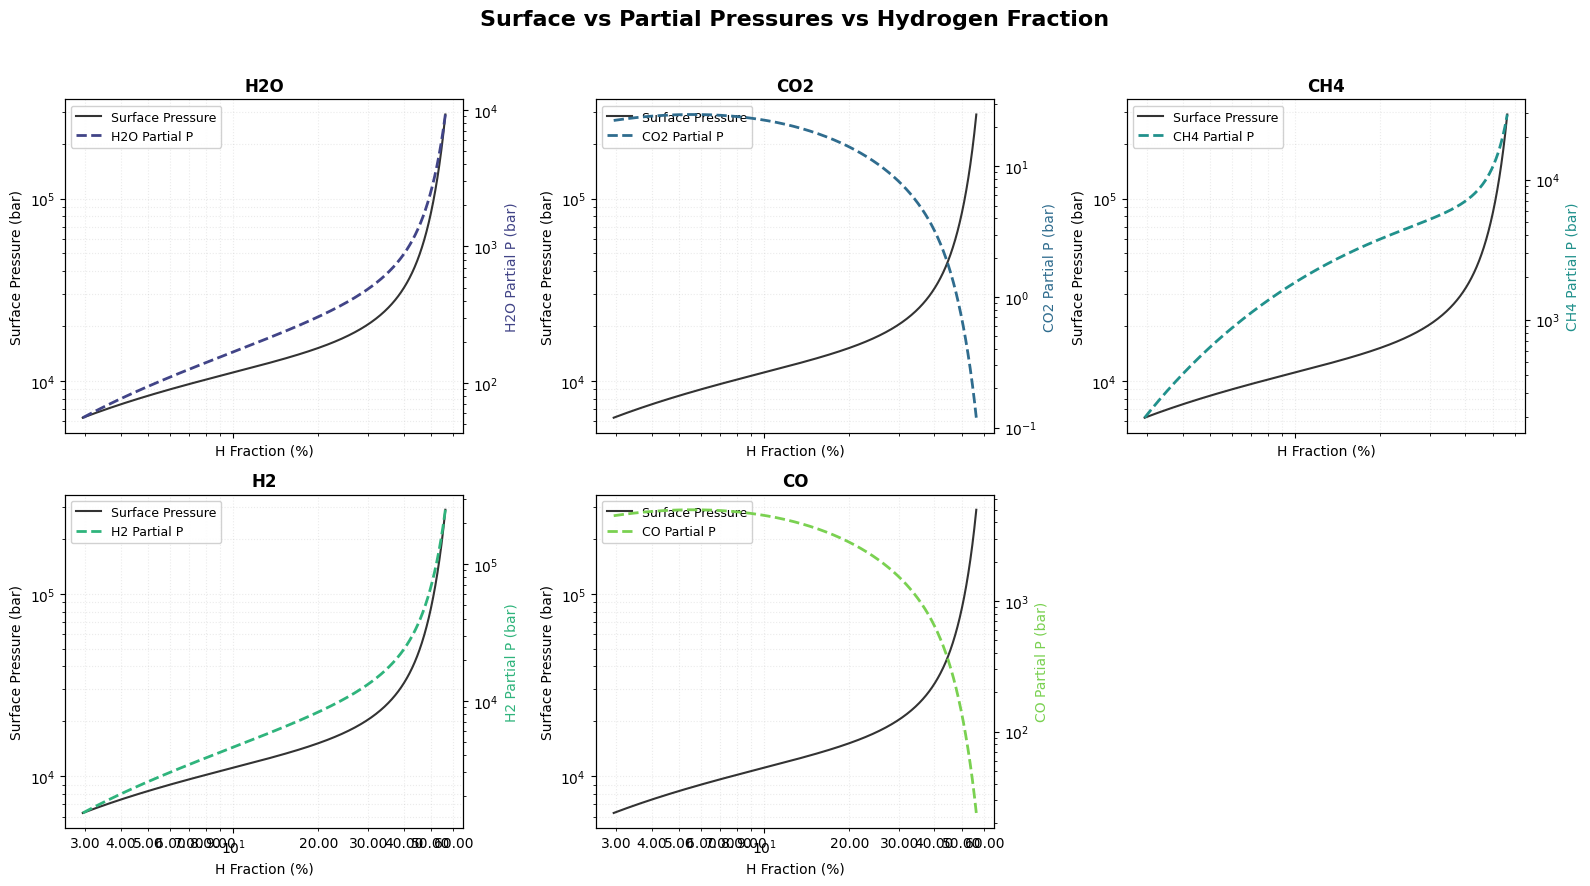

In [48]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np

# === File and species list ===
excel_file = "sub_neptune_ideal_withsol_varyHF.xlsx"
species = ['H2O_g', 'CO2_g', 'CH4_g', 'H2_g', 'CO_g']

# === Load base data ===
df_H = pd.read_excel(excel_file, sheet_name='element_H')
df_atm = pd.read_excel(excel_file, sheet_name='atmosphere')

x = df_H['atmosphere_ppmw'] / 1e4  # Hydrogen fraction (%)
P_surf = df_atm['pressure']        # Total surface pressure (bar)

# === Color palette ===
cmap = plt.cm.viridis(np.linspace(0.2, 0.8, len(species)))

# === Multi-panel figure ===
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True, sharey=False)
axes = axes.flatten()

for i, sp in enumerate(species):
    ax = axes[i]
    color = cmap[i]

    try:
        df_gas = pd.read_excel(excel_file, sheet_name=sp)
        if 'pressure' not in df_gas.columns:
            continue
        y_partial = df_gas['pressure']
    except ValueError:
        continue

    # --- Total surface pressure ---
    ax.plot(x, P_surf, '-', color='black', lw=1.5, alpha=0.8, label='Surface Pressure')

    # --- Partial pressure of gas ---
    ax2 = ax.twinx()
    ax2.plot(x, y_partial, '--', color=color, lw=2, label=f'{sp.replace("_g","").upper()} Partial P')

    # --- Log scales ---
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax2.set_yscale('log')

    # --- Axis labels ---
    ax.set_xlabel('H Fraction (%)', fontsize=10)
    ax.set_ylabel('Surface Pressure (bar)', color='black', fontsize=10)
    ax2.set_ylabel(f'{sp.replace("_g","").upper()} Partial P (bar)', color=color, fontsize=10)

    # --- Title and grid ---
    ax.set_title(sp.replace('_g','').upper(), fontweight='bold', fontsize=12)
    ax.grid(True, alpha=0.25, linestyle=':', which='both')

    # --- Ticks formatting ---
    ax.xaxis.set_minor_formatter(mtick.FormatStrFormatter("%.2f"))
    ax.yaxis.set_minor_formatter(mtick.LogFormatterSciNotation())
    ax2.yaxis.set_minor_formatter(mtick.LogFormatterSciNotation())

    # --- Combined legend ---
    lines, labels = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines + lines2, labels + labels2, fontsize=9, loc='upper left', framealpha=0.9)

# Remove empty subplot
for j in range(len(species), len(axes)):
    fig.delaxes(axes[j])

# --- Overall figure tweaks ---
plt.suptitle('Surface vs Partial Pressures vs Hydrogen Fraction', fontsize=16, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('partial_pressures_multi_panel_phd.png', dpi=300, bbox_inches='tight')
plt.show()


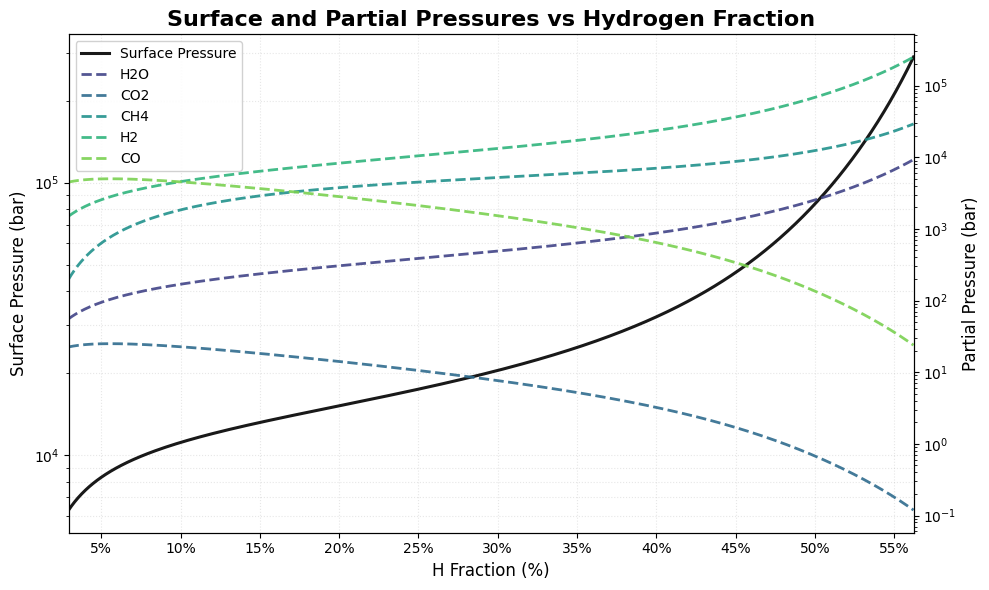

In [49]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# === File and species list ===
excel_file = "sub_neptune_ideal_withsol_varyHF.xlsx"
species = ['H2O_g', 'CO2_g', 'CH4_g', 'H2_g', 'CO_g']

# === Load base data ===
df_H = pd.read_excel(excel_file, sheet_name='element_H')
df_atm = pd.read_excel(excel_file, sheet_name='atmosphere')

# Hydrogen fraction in %
x = df_H['atmosphere_ppmw'] / 1e4
P_surf = df_atm['pressure']

# Color palette
cmap = plt.cm.viridis(np.linspace(0.2, 0.8, len(species)))

# --- Single-panel figure ---
fig, ax = plt.subplots(figsize=(10, 6))

# Surface pressure
ax.plot(x, P_surf, '-', color='black', lw=2.2, alpha=0.9, label='Surface Pressure')

# Partial pressures
ax2 = ax.twinx()
for i, sp in enumerate(species):
    try:
        df_gas = pd.read_excel(excel_file, sheet_name=sp)
        if 'pressure' not in df_gas.columns:
            continue
        ax2.plot(x, df_gas['pressure'], '--', lw=2.0, color=cmap[i],
                 label=sp.replace('_g','').upper(), alpha=0.9)
    except ValueError:
        continue

# --- Linear x-axis with clean, scientific ticks ---
x_min = np.floor(np.min(x)/5)*5       # nearest 5% below min
x_max = min(np.floor(np.max(x)/5)*5, 55)  # stop at 55% if max > 55
tick_values = list(range(int(x_min), int(x_max)+1, 5))

ax.set_xlabel('H Fraction (%)', fontsize=12)
ax.set_xticks(tick_values)
ax.set_xticklabels([f'{v}%' for v in tick_values], fontsize=10)
ax.set_xlim(np.min(x), np.max(x))

# --- Log y-axes ---
ax.set_yscale('log')
ax2.set_yscale('log')
ax.set_ylabel('Surface Pressure (bar)', color='black', fontsize=12)
ax2.set_ylabel('Partial Pressure (bar)', fontsize=12)

# --- Grid ---
ax.grid(True, linestyle=':', alpha=0.3, which='both')

# --- Legend ---
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines + lines2, labels + labels2, fontsize=10, loc='upper left', framealpha=0.9)

# --- Title ---
ax.set_title('Surface and Partial Pressures vs Hydrogen Fraction', fontsize=16, fontweight='bold')

# --- Tight layout & save ---
plt.tight_layout()
plt.savefig('partial_pressures_single_panel_linearX.png', dpi=300, bbox_inches='tight')
plt.show()


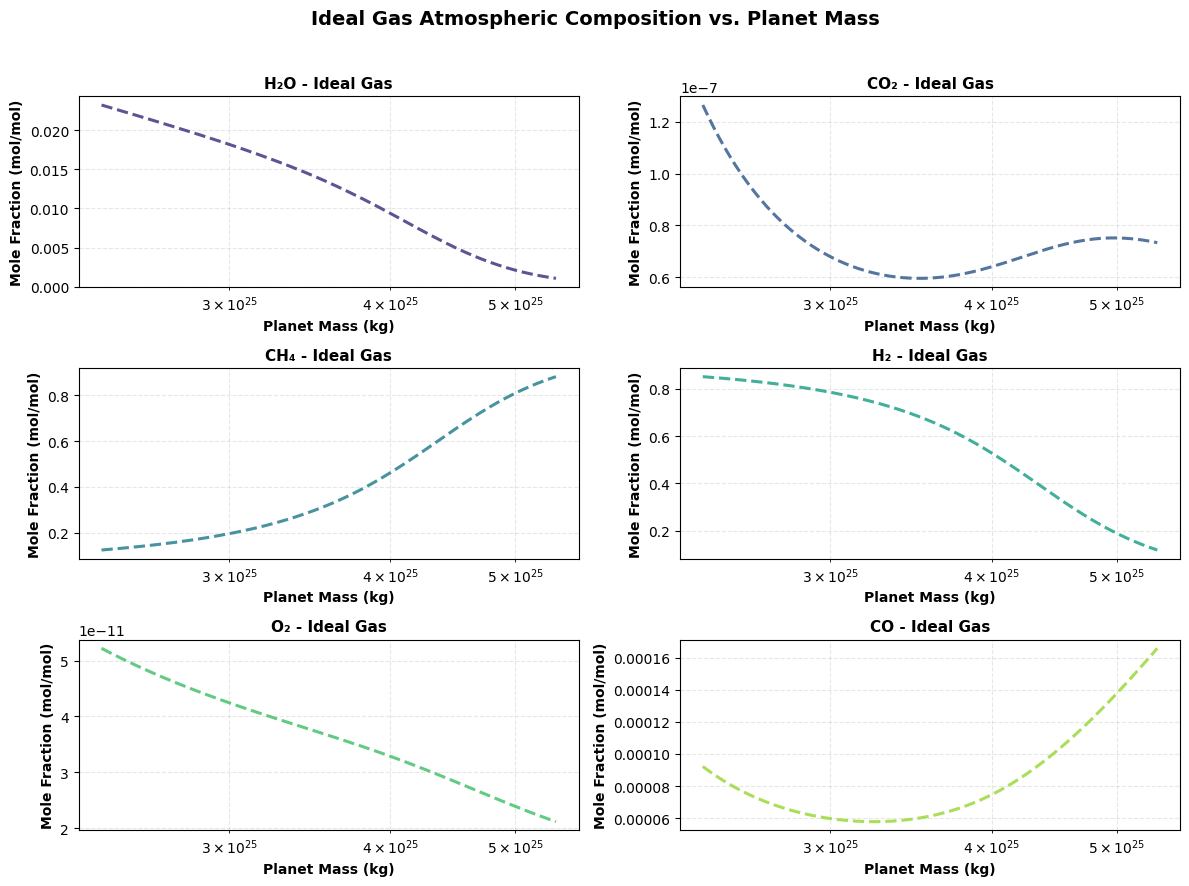

In [50]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# === Load ideal gas data ===
ideal_planet = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='planet')
ideal_h2o_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='H2O_g')
ideal_co2_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='CO2_g')
ideal_ch4_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='CH4_g')
ideal_h2_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='H2_g')
ideal_o2_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='O2_g')
ideal_co_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='CO_g')

# Planet mass
planet_mass_ideal = ideal_planet['planet_mass']

# Mole fractions
ideal_species_data = [
    ('H₂O', ideal_h2o_mp['volume_mixing_ratio']),
    ('CO₂', ideal_co2_mp['volume_mixing_ratio']),
    ('CH₄', ideal_ch4_mp['volume_mixing_ratio']),
    ('H₂', ideal_h2_mp['volume_mixing_ratio']),
    ('O₂', ideal_o2_mp['volume_mixing_ratio']),
    ('CO', ideal_co_mp['volume_mixing_ratio'])
]

# Use a perceptually uniform colormap
cmap = plt.cm.viridis(np.linspace(0.15, 0.85, len(ideal_species_data)))

# --- Figure: 2 columns x 3 rows ---
fig, axes = plt.subplots(3, 2, figsize=(12, 9))
axes = axes.flatten()

for i, ((name, mix), color) in enumerate(zip(ideal_species_data, cmap)):
    ax = axes[i]
    ax.plot(planet_mass_ideal, mix, '--', color=color, lw=2.2, alpha=0.85)
    
    ax.set_xscale('log')
    ax.set_xlabel('Planet Mass (kg)', fontsize=10, fontweight='bold')
    ax.set_ylabel('Mole Fraction (mol/mol)', fontsize=10, fontweight='bold')
    ax.set_title(f'{name} - Ideal Gas', fontsize=11, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.3, which='both')

plt.suptitle('Ideal Gas Atmospheric Composition vs. Planet Mass', fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('ideal_gas_atmosphere_vs_planetmass_colored.png', dpi=300, bbox_inches='tight')
plt.show()


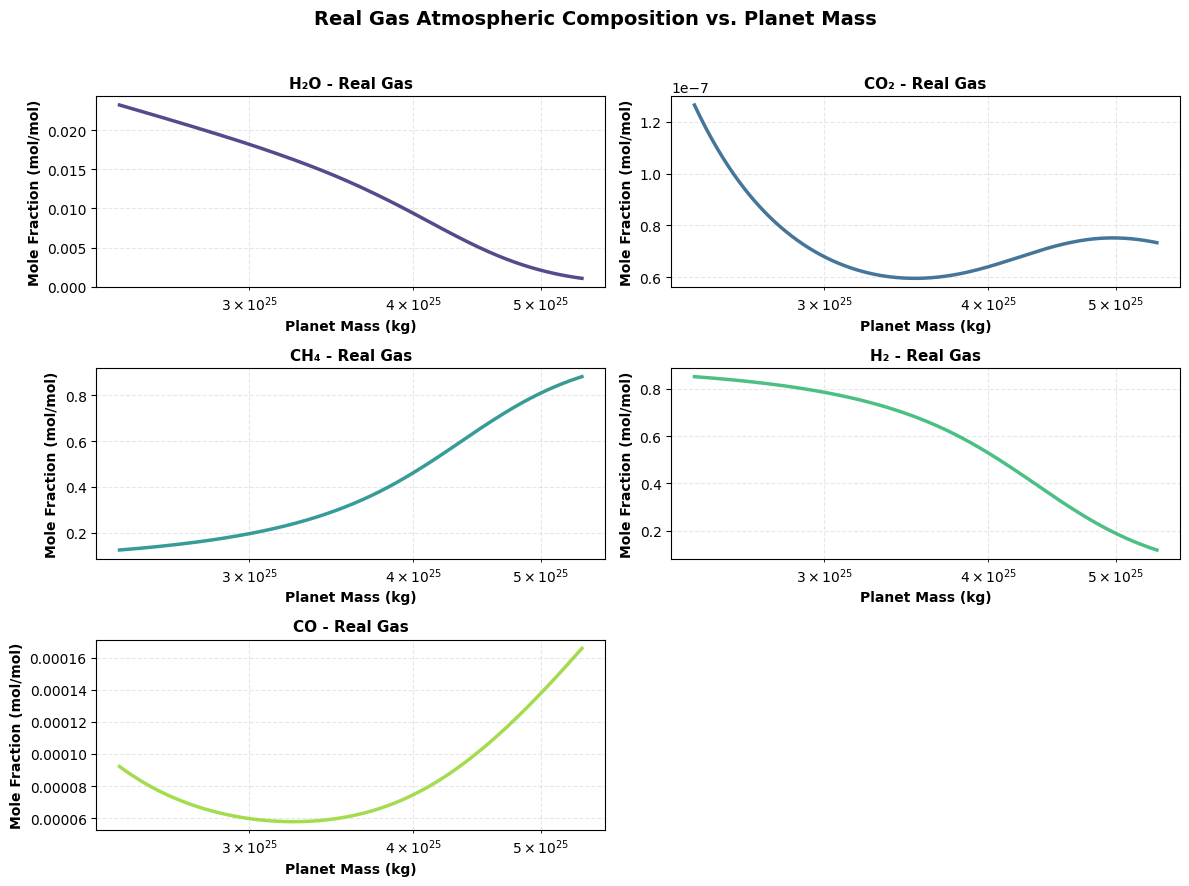

In [51]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# === Load real gas data ===
real_planet = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='planet')
real_h2o_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='H2O_g')
real_co2_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='CO2_g')
real_ch4_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='CH4_g')
real_h2_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='H2_g')
real_co_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='CO_g')

# Planet mass
planet_mass_real = real_planet['planet_mass']

# Mole fractions for selected gases
real_species_data = [
    ('H₂O', real_h2o_mp['volume_mixing_ratio']),
    ('CO₂', real_co2_mp['volume_mixing_ratio']),
    ('CH₄', real_ch4_mp['volume_mixing_ratio']),
    ('H₂', real_h2_mp['volume_mixing_ratio']),
    ('CO', real_co_mp['volume_mixing_ratio'])
]

# Color palette
cmap = plt.cm.viridis(np.linspace(0.15, 0.85, len(real_species_data)))

# --- Figure: 2 columns x 3 rows ---
fig, axes = plt.subplots(3, 2, figsize=(12, 9))
axes = axes.flatten()

for i, ((name, mix), color) in enumerate(zip(real_species_data, cmap)):
    ax = axes[i]
    ax.plot(planet_mass_real, mix, '-', color=color, lw=2.5, alpha=0.9)  # full line
    
    ax.set_xscale('log')
    ax.set_xlabel('Planet Mass (kg)', fontsize=10, fontweight='bold')
    ax.set_ylabel('Mole Fraction (mol/mol)', fontsize=10, fontweight='bold')
    ax.set_title(f'{name} - Real Gas', fontsize=11, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.3, which='both')

# Remove the last empty subplot (since 5 species < 6 panels)
fig.delaxes(axes[-1])

plt.suptitle('Real Gas Atmospheric Composition vs. Planet Mass', fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('real_gas_atmosphere_vs_planetmass.png', dpi=300, bbox_inches='tight')
plt.show()


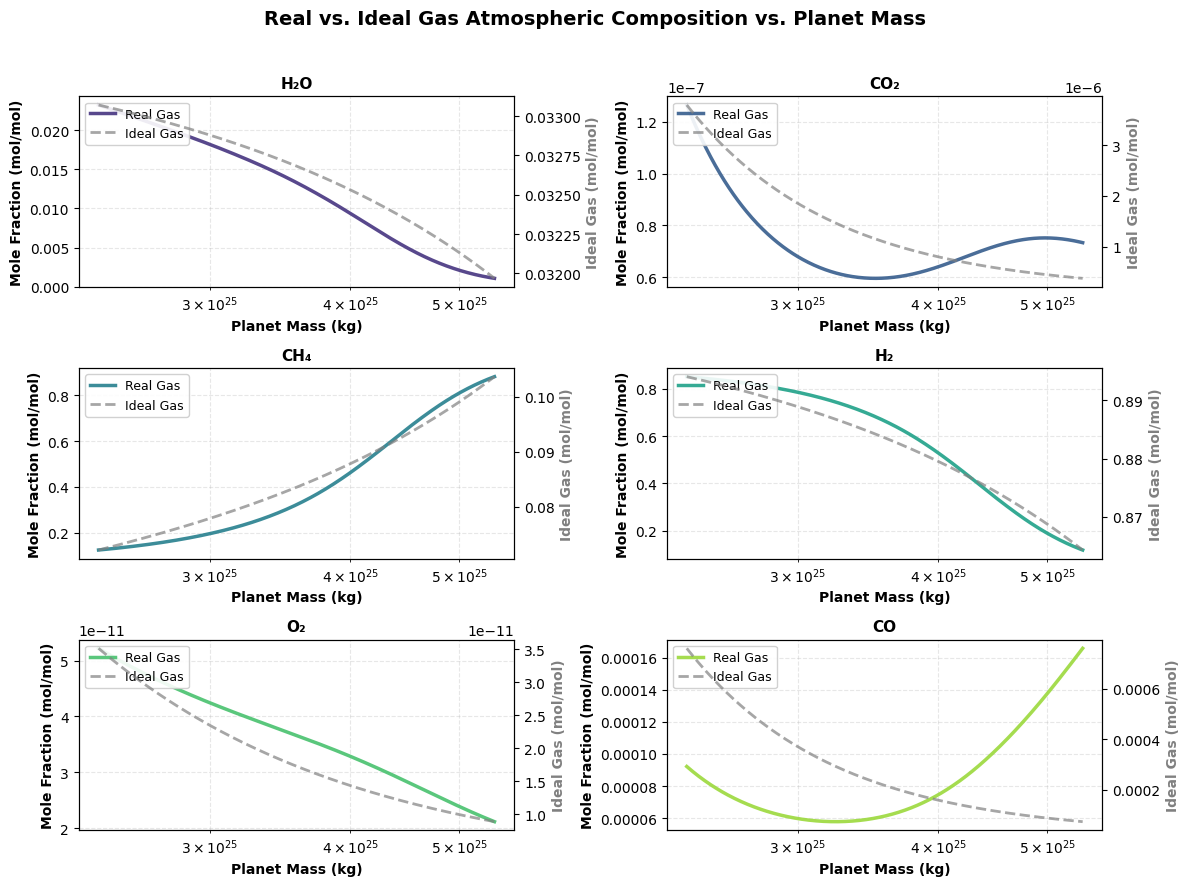

In [52]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# === Load real gas data ===
real_planet = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='planet')
real_h2o_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='H2O_g')
real_co2_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='CO2_g')
real_ch4_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='CH4_g')
real_h2_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='H2_g')
real_o2_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='O2_g')
real_co_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='CO_g')

# === Load ideal gas data (for comparison) ===
ideal_planet = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='planet')
ideal_h2o_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='H2O_g')
ideal_co2_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='CO2_g')
ideal_ch4_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='CH4_g')
ideal_h2_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='H2_g')
ideal_o2_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='O2_g')
ideal_co_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='CO_g')

# Planet mass
planet_mass_real = real_planet['planet_mass']
planet_mass_ideal = ideal_planet['planet_mass']

# Real and ideal species data
species_names = ['H₂O', 'CO₂', 'CH₄', 'H₂', 'O₂', 'CO']
real_species_data = [
    real_h2o_mp['volume_mixing_ratio'],
    real_co2_mp['volume_mixing_ratio'],
    real_ch4_mp['volume_mixing_ratio'],
    real_h2_mp['volume_mixing_ratio'],
    real_o2_mp['volume_mixing_ratio'],
    real_co_mp['volume_mixing_ratio']
]
ideal_species_data = [
    ideal_h2o_mp['volume_mixing_ratio'],
    ideal_co2_mp['volume_mixing_ratio'],
    ideal_ch4_mp['volume_mixing_ratio'],
    ideal_h2_mp['volume_mixing_ratio'],
    ideal_o2_mp['volume_mixing_ratio'],
    ideal_co_mp['volume_mixing_ratio']
]

# Color palette for real gas
cmap = plt.cm.viridis(np.linspace(0.15, 0.85, len(species_names)))

# --- Figure: 2 columns x 3 rows ---
fig, axes = plt.subplots(3, 2, figsize=(12, 9))
axes = axes.flatten()

for i, name in enumerate(species_names):
    ax = axes[i]
    # Real gas (solid colored line)
    ax.plot(planet_mass_real, real_species_data[i], '-', color=cmap[i], lw=2.5, alpha=0.9, label='Real Gas')
    
    # Right axis: ideal gas (grey dotted)
    ax2 = ax.twinx()
    ax2.plot(planet_mass_ideal, ideal_species_data[i], '--', color='gray', lw=2, alpha=0.7, label='Ideal Gas')
    
    # Axes settings
    ax.set_xscale('log')
    ax.set_ylabel('Mole Fraction (mol/mol)', fontsize=10, fontweight='bold')
    ax2.set_ylabel('Ideal Gas (mol/mol)', fontsize=10, fontweight='bold', color='gray')
    ax.set_xlabel('Planet Mass (kg)', fontsize=10, fontweight='bold')
    
    ax.set_title(f'{name}', fontsize=11, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.3, which='both')
    
    # Legends
    lines, labels = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines + lines2, labels + labels2, fontsize=9, loc='upper left', framealpha=0.9)

plt.suptitle('Real vs. Ideal Gas Atmospheric Composition vs. Planet Mass', fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('real_vs_ideal_gas_atmosphere_vs_planetmass.png', dpi=300, bbox_inches='tight')
plt.show()


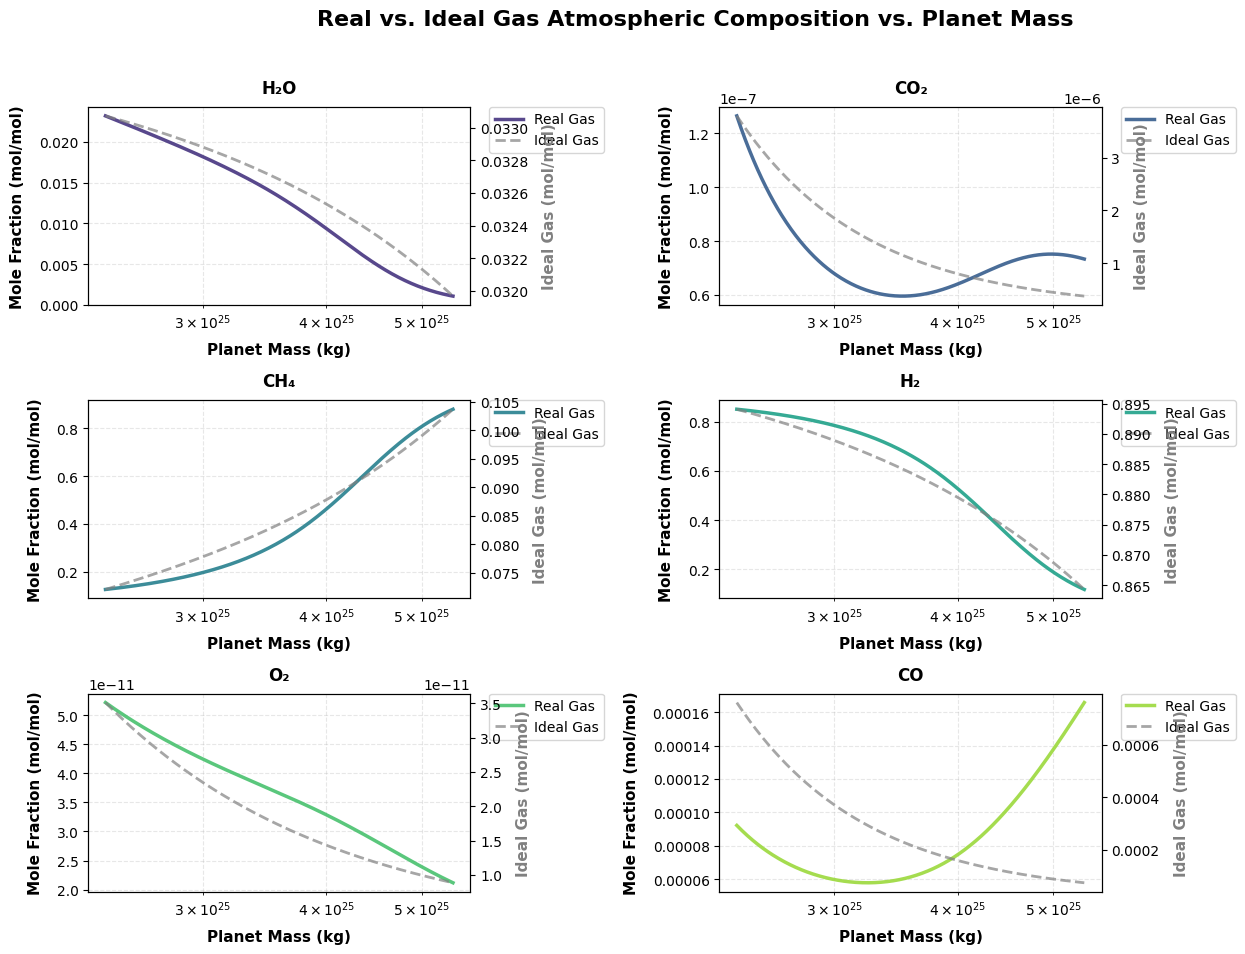

In [53]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# === Load real gas data ===
real_planet = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='planet')
real_h2o_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='H2O_g')
real_co2_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='CO2_g')
real_ch4_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='CH4_g')
real_h2_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='H2_g')
real_o2_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='O2_g')
real_co_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='CO_g')

# === Load ideal gas data (for comparison) ===
ideal_planet = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='planet')
ideal_h2o_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='H2O_g')
ideal_co2_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='CO2_g')
ideal_ch4_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='CH4_g')
ideal_h2_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='H2_g')
ideal_o2_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='O2_g')
ideal_co_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='CO_g')

# Planet mass
planet_mass_real = real_planet['planet_mass']
planet_mass_ideal = ideal_planet['planet_mass']

# Real and ideal species data
species_names = ['H₂O', 'CO₂', 'CH₄', 'H₂', 'O₂', 'CO']
real_species_data = [
    real_h2o_mp['volume_mixing_ratio'],
    real_co2_mp['volume_mixing_ratio'],
    real_ch4_mp['volume_mixing_ratio'],
    real_h2_mp['volume_mixing_ratio'],
    real_o2_mp['volume_mixing_ratio'],
    real_co_mp['volume_mixing_ratio']
]
ideal_species_data = [
    ideal_h2o_mp['volume_mixing_ratio'],
    ideal_co2_mp['volume_mixing_ratio'],
    ideal_ch4_mp['volume_mixing_ratio'],
    ideal_h2_mp['volume_mixing_ratio'],
    ideal_o2_mp['volume_mixing_ratio'],
    ideal_co_mp['volume_mixing_ratio']
]

# Color palette for real gas
cmap = plt.cm.viridis(np.linspace(0.15, 0.85, len(species_names)))

# --- Figure: 2 columns x 3 rows, slightly larger figure ---
fig, axes = plt.subplots(3, 2, figsize=(14, 10))
axes = axes.flatten()

for i, name in enumerate(species_names):
    ax = axes[i]
    
    # Real gas (solid colored line)
    ax.plot(planet_mass_real, real_species_data[i], '-', color=cmap[i], lw=2.5, alpha=0.9, label='Real Gas')
    
    # Right axis: ideal gas (grey dotted)
    ax2 = ax.twinx()
    ax2.plot(planet_mass_ideal, ideal_species_data[i], '--', color='gray', lw=2, alpha=0.7, label='Ideal Gas')
    
    # Axes settings
    ax.set_xscale('log')
    ax.set_ylabel('Mole Fraction (mol/mol)', fontsize=11, fontweight='bold', labelpad=10)
    ax2.set_ylabel('Ideal Gas (mol/mol)', fontsize=11, fontweight='bold', color='gray', labelpad=10)
    ax.set_xlabel('Planet Mass (kg)', fontsize=11, fontweight='bold', labelpad=8)
    ax.set_title(f'{name}', fontsize=12, fontweight='bold', pad=10)
    ax.grid(True, linestyle='--', alpha=0.3, which='both')
    
    # Legends outside the plot area
    lines, labels = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines + lines2, labels + labels2, fontsize=10, loc='upper left',
              bbox_to_anchor=(1.05, 1), borderaxespad=0.)

# Increase spacing between subplots
plt.subplots_adjust(hspace=0.35, wspace=0.3)

plt.suptitle('Real vs. Ideal Gas Atmospheric Composition vs. Planet Mass', fontsize=16, fontweight='bold', y=0.95)
plt.tight_layout(rect=[0, 0, 0.9, 0.93])  # leave space for legends
plt.savefig('real_vs_ideal_gas_atmosphere_vs_planetmass_spacing.png', dpi=300, bbox_inches='tight')
plt.show()


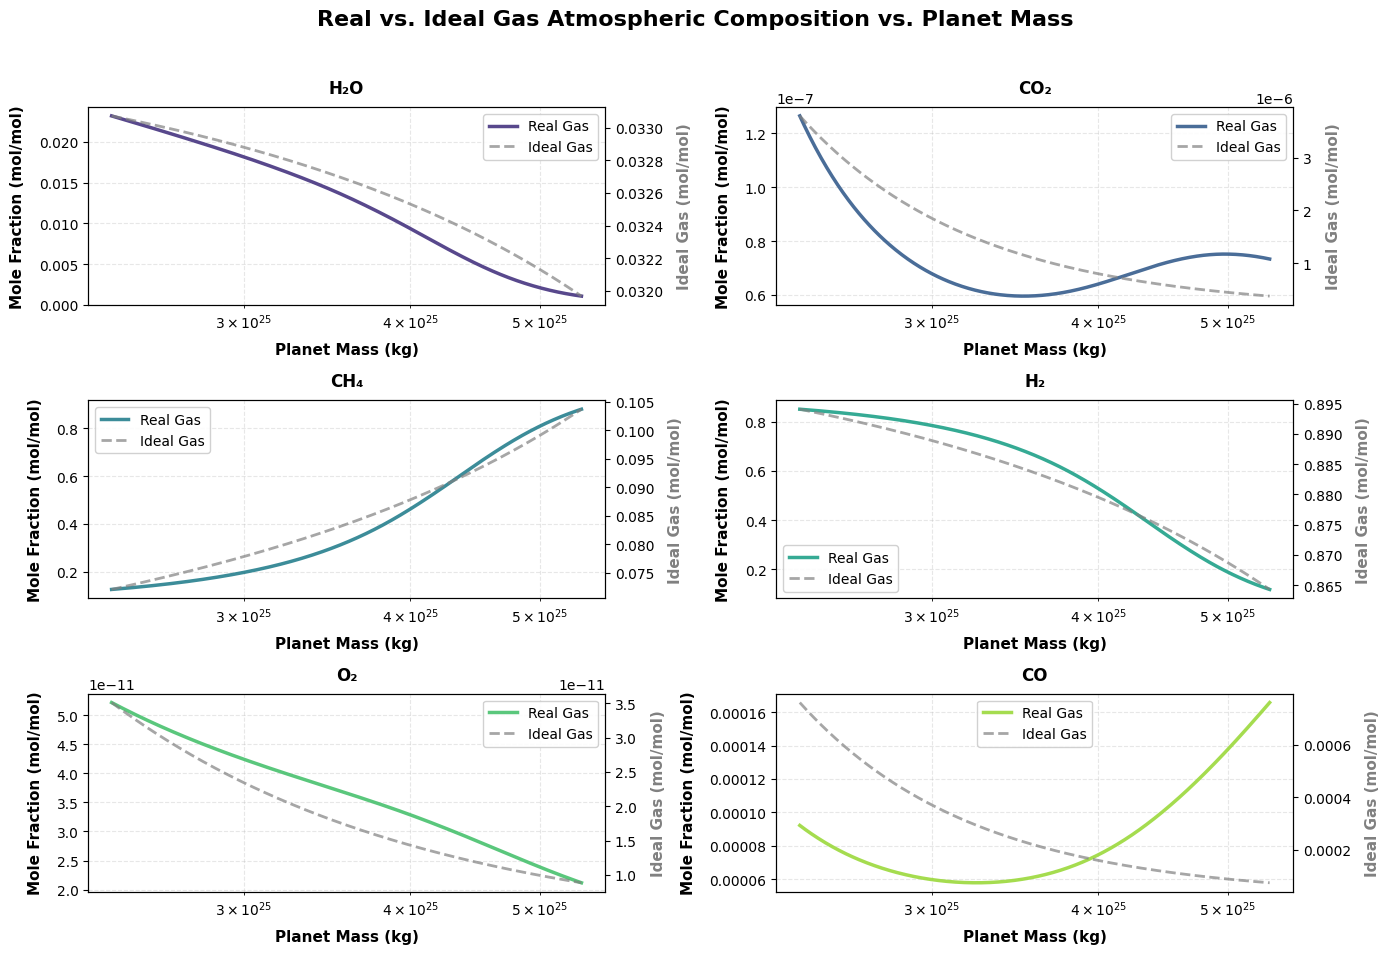

In [54]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# === Load real gas data ===
real_planet = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='planet')
real_h2o_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='H2O_g')
real_co2_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='CO2_g')
real_ch4_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='CH4_g')
real_h2_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='H2_g')
real_o2_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='O2_g')
real_co_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='CO_g')

# === Load ideal gas data (for comparison) ===
ideal_planet = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='planet')
ideal_h2o_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='H2O_g')
ideal_co2_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='CO2_g')
ideal_ch4_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='CH4_g')
ideal_h2_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='H2_g')
ideal_o2_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='O2_g')
ideal_co_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='CO_g')

# Planet mass
planet_mass_real = real_planet['planet_mass']
planet_mass_ideal = ideal_planet['planet_mass']

# Real and ideal species data
species_names = ['H₂O', 'CO₂', 'CH₄', 'H₂', 'O₂', 'CO']
real_species_data = [
    real_h2o_mp['volume_mixing_ratio'],
    real_co2_mp['volume_mixing_ratio'],
    real_ch4_mp['volume_mixing_ratio'],
    real_h2_mp['volume_mixing_ratio'],
    real_o2_mp['volume_mixing_ratio'],
    real_co_mp['volume_mixing_ratio']
]
ideal_species_data = [
    ideal_h2o_mp['volume_mixing_ratio'],
    ideal_co2_mp['volume_mixing_ratio'],
    ideal_ch4_mp['volume_mixing_ratio'],
    ideal_h2_mp['volume_mixing_ratio'],
    ideal_o2_mp['volume_mixing_ratio'],
    ideal_co_mp['volume_mixing_ratio']
]

# Legend positions for each species (inside plot)
legend_positions = {
    'H₂O': 'upper right',
    'CO₂': 'upper right',
    'CH₄': 'upper left',
    'H₂': 'lower left',
    'O₂': 'upper right',
    'CO': 'upper center'
}

# Color palette for real gas
cmap = plt.cm.viridis(np.linspace(0.15, 0.85, len(species_names)))

# --- Figure: 2 columns x 3 rows ---
fig, axes = plt.subplots(3, 2, figsize=(14, 10))
axes = axes.flatten()

for i, name in enumerate(species_names):
    ax = axes[i]
    
    # Real gas (solid colored line)
    ax.plot(planet_mass_real, real_species_data[i], '-', color=cmap[i], lw=2.5, alpha=0.9, label='Real Gas')
    
    # Right axis: ideal gas (grey dotted)
    ax2 = ax.twinx()
    ax2.plot(planet_mass_ideal, ideal_species_data[i], '--', color='gray', lw=2, alpha=0.7, label='Ideal Gas')
    
    # Axes settings
    ax.set_xscale('log')
    ax.set_ylabel('Mole Fraction (mol/mol)', fontsize=11, fontweight='bold', labelpad=10)
    ax2.set_ylabel('Ideal Gas (mol/mol)', fontsize=11, fontweight='bold', color='gray', labelpad=10)
    ax.set_xlabel('Planet Mass (kg)', fontsize=11, fontweight='bold', labelpad=8)
    ax.set_title(f'{name}', fontsize=12, fontweight='bold', pad=10)
    ax.grid(True, linestyle='--', alpha=0.3, which='both')
    
    # Legends inside the plot at requested positions
    lines, labels = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines + lines2, labels + labels2, fontsize=10, loc=legend_positions[name], framealpha=0.9)

# Increase spacing between subplots
plt.subplots_adjust(hspace=0.35, wspace=0.35)

plt.suptitle('Real vs. Ideal Gas Atmospheric Composition vs. Planet Mass', fontsize=16, fontweight='bold', y=0.95)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig('real_vs_ideal_gas_atmosphere_vs_planetmass_legend_inside.png', dpi=300, bbox_inches='tight')
plt.show()


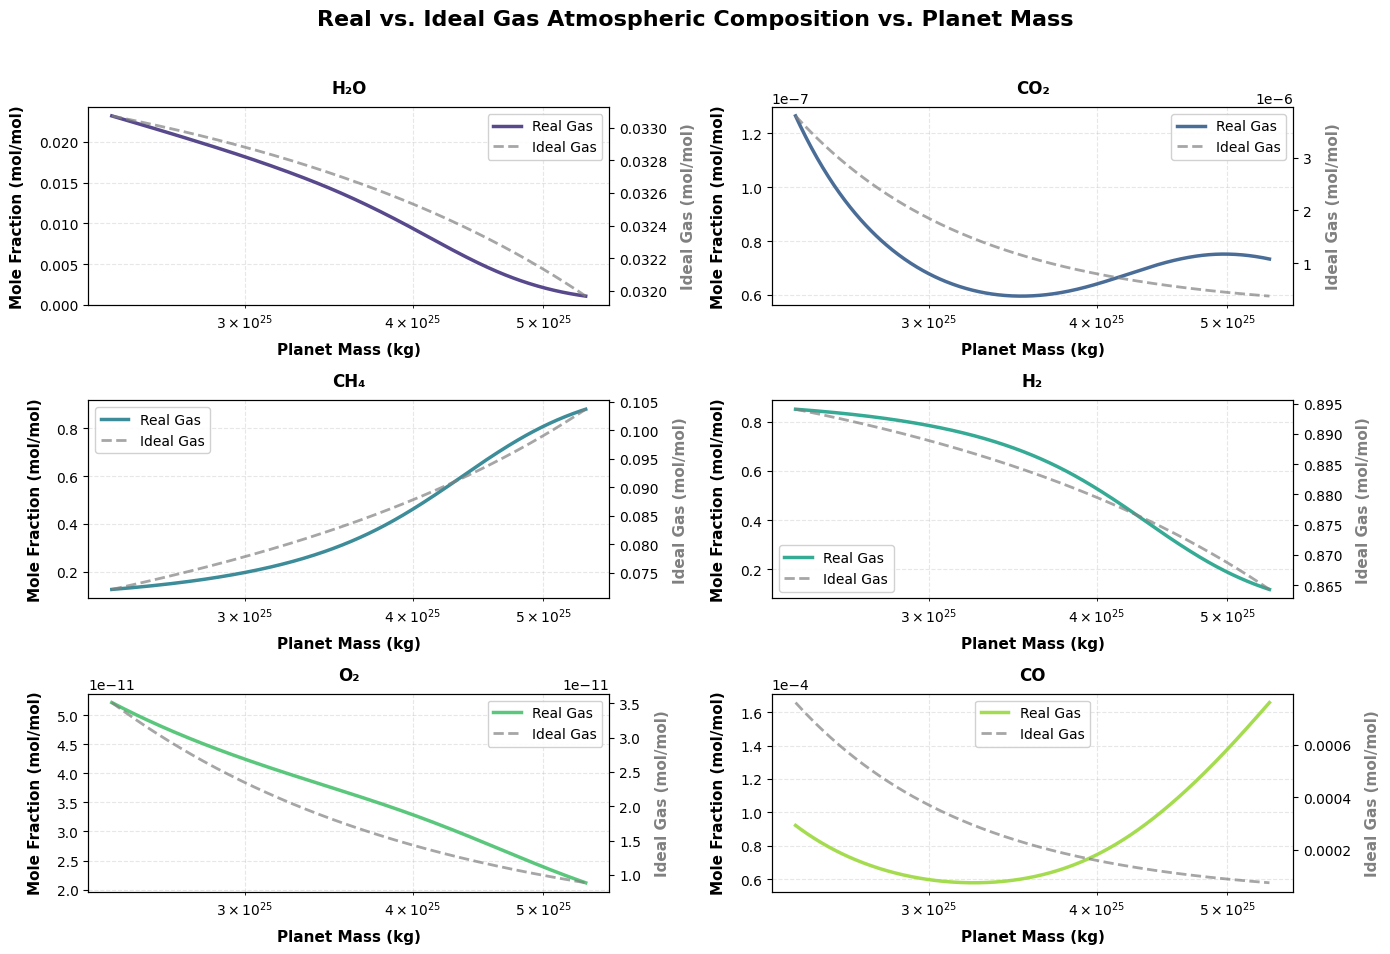

In [55]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

# === Load real gas data ===
real_planet = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='planet')
real_h2o_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='H2O_g')
real_co2_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='CO2_g')
real_ch4_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='CH4_g')
real_h2_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='H2_g')
real_o2_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='O2_g')
real_co_mp = pd.read_excel('sub_neptune_real_withsol_varyMp.xlsx', sheet_name='CO_g')

# === Load ideal gas data ===
ideal_planet = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='planet')
ideal_h2o_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='H2O_g')
ideal_co2_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='CO2_g')
ideal_ch4_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='CH4_g')
ideal_h2_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='H2_g')
ideal_o2_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='O2_g')
ideal_co_mp = pd.read_excel('sub_neptune_ideal_withsol_varyMp.xlsx', sheet_name='CO_g')

# Planet mass
planet_mass_real = real_planet['planet_mass']
planet_mass_ideal = ideal_planet['planet_mass']

# Real and ideal species data
species_names = ['H₂O', 'CO₂', 'CH₄', 'H₂', 'O₂', 'CO']
real_species_data = [
    real_h2o_mp['volume_mixing_ratio'],
    real_co2_mp['volume_mixing_ratio'],
    real_ch4_mp['volume_mixing_ratio'],
    real_h2_mp['volume_mixing_ratio'],
    real_o2_mp['volume_mixing_ratio'],
    real_co_mp['volume_mixing_ratio']
]
ideal_species_data = [
    ideal_h2o_mp['volume_mixing_ratio'],
    ideal_co2_mp['volume_mixing_ratio'],
    ideal_ch4_mp['volume_mixing_ratio'],
    ideal_h2_mp['volume_mixing_ratio'],
    ideal_o2_mp['volume_mixing_ratio'],
    ideal_co_mp['volume_mixing_ratio']
]

# Legend positions for each species
legend_positions = {
    'H₂O': 'upper right',
    'CO₂': 'upper right',
    'CH₄': 'upper left',
    'H₂': 'lower left',
    'O₂': 'upper right',
    'CO': 'upper center'
}

# Color palette for real gas
cmap = plt.cm.viridis(np.linspace(0.15, 0.85, len(species_names)))

# --- Figure: 2 columns x 3 rows ---
fig, axes = plt.subplots(3, 2, figsize=(14, 10))
axes = axes.flatten()

for i, name in enumerate(species_names):
    ax = axes[i]
    
    # Real gas (solid colored line)
    ax.plot(planet_mass_real, real_species_data[i], '-', color=cmap[i], lw=2.5, alpha=0.9, label='Real Gas')
    
    # Right axis: ideal gas (grey dotted)
    ax2 = ax.twinx()
    ax2.plot(planet_mass_ideal, ideal_species_data[i], '--', color='gray', lw=2, alpha=0.7, label='Ideal Gas')
    
    # Axes settings
    ax.set_xscale('log')
    ax.set_ylabel('Mole Fraction (mol/mol)', fontsize=11, fontweight='bold', labelpad=10)
    ax2.set_ylabel('Ideal Gas (mol/mol)', fontsize=11, fontweight='bold', color='gray', labelpad=10)
    ax.set_xlabel('Planet Mass (kg)', fontsize=11, fontweight='bold', labelpad=8)
    ax.set_title(f'{name}', fontsize=12, fontweight='bold', pad=10)
    ax.grid(True, linestyle='--', alpha=0.3, which='both')
    
    # Legends inside the plot
    lines, labels = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines + lines2, labels + labels2, fontsize=10, loc=legend_positions[name], framealpha=0.9)
    
    # Format CO left axis in scientific notation
    if name == 'CO':
        ax.yaxis.set_major_formatter(mtick.ScalarFormatter())
        ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))

# Increase spacing between subplots
plt.subplots_adjust(hspace=0.35, wspace=0.35)
plt.suptitle('Real vs. Ideal Gas Atmospheric Composition vs. Planet Mass', fontsize=16, fontweight='bold', y=0.95)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig('real_vs_ideal_gas_atmosphere_vs_planetmass_CO_scientific.png', dpi=300, bbox_inches='tight')
plt.show()



In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def plot_molecular_budget_from_excel(excel_file, species=None):
    """
    Plot molecular budget (atmosphere vs dissolved vs condensed)
    for each species from a real-gas Excel output file.
    """

    print("\n" + "="*70)
    print("Creating molecular budget plot from:", excel_file)
    print("="*70)
    
    # Default species to plot
    if species is None:
        species = ['H2O_g', 'H2_g', 'CH4_g', 'CO2_g', 'CO_g', 'O2_g']
    
    # --- 1) Read hydrogen fraction as x-axis
    df_H = pd.read_excel(excel_file, sheet_name='element_H')
    if 'atmosphere_ppmw' in df_H.columns:
        H_frac_percent = df_H['atmosphere_ppmw'].values / 1e4  # ppmw → %
    else:
        raise KeyError("The sheet 'element_H' must contain 'atmosphere_ppmw' for the H mass fraction axis.")
    
    # --- 2) Create figure
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    axes = axes.flatten()
    
    for i, sp in enumerate(species):
        ax = axes[i]
        
        try:
            df = pd.read_excel(excel_file, sheet_name=sp)
        except Exception as e:
            print(f"⚠️ Skipping {sp}: sheet not found.")
            continue
        
        # Ensure required columns exist
        if not {'atmosphere_mass', 'dissolved_mass'}.issubset(df.columns):
            print(f"⚠️ Skipping {sp}: missing mass columns.")
            continue
        
        atm_mass = df['atmosphere_mass'].values
        dis_mass = df['dissolved_mass'].values
        con_mass = df['condensed_mass'].values if 'condensed_mass' in df.columns else np.zeros_like(atm_mass)
        
        total_mass = atm_mass + dis_mass + con_mass
        total_mass[total_mass == 0] = np.nan  # avoid divide-by-zero
        
        # --- Stacked area plot in %
        ax.fill_between(H_frac_percent, 0, atm_mass/total_mass*100, 
                        label='Atmosphere', color='#1f77b4', alpha=0.7)
        ax.fill_between(H_frac_percent, atm_mass/total_mass*100, 
                        (atm_mass+dis_mass)/total_mass*100, 
                        label='Dissolved', color='#ff7f0e', alpha=0.7)
        if np.any(con_mass > 0):
            ax.fill_between(H_frac_percent, (atm_mass+dis_mass)/total_mass*100, 100, 
                            label='Condensed', color='#2ca02c', alpha=0.7)
        
        # --- Formatting
        ax.set_xscale('log')
        
        # Get data min/max
        xmin_data = H_frac_percent.min()
        xmax_data = H_frac_percent.max()
        # Set x-limits with a 10% margin on each side (log-scaled)
        ax.set_xlim(xmin_data / 1.10, xmax_data * 1.10)
        
        ax.set_ylim(0, 100)
        ax.set_xlabel("H Mass Fraction (%)")
        ax.set_ylabel("Distribution (%)")
        
        # This line adds the title to each subplot
        ax.set_title(f"({chr(97+i)}) {sp.replace('_g','').upper()} Budget", fontweight='bold')
        
        ax.grid(True, alpha=0.3, linestyle=':', linewidth=0.5)
        
        # This line adds a legend to EACH subplot in the upper left
        ax.legend(loc='upper left', frameon=True, fontsize=9)
    
    # Hide any unused subplots
    for j in range(len(species), len(axes)):
        fig.delaxes(axes[j])
    
    plt.tight_layout()
    plt.savefig("sub_neptune_molecular_budget.png", dpi=300, bbox_inches='tight')
    print("\n✓ Successfully saved: sub_neptune_molecular_budget.png")
    print("="*70)
    plt.show()


Creating molecular budget plot from: sub_neptune_ideal_withsol_varyHF.xlsx

✓ Successfully saved: sub_neptune_molecular_budget.png


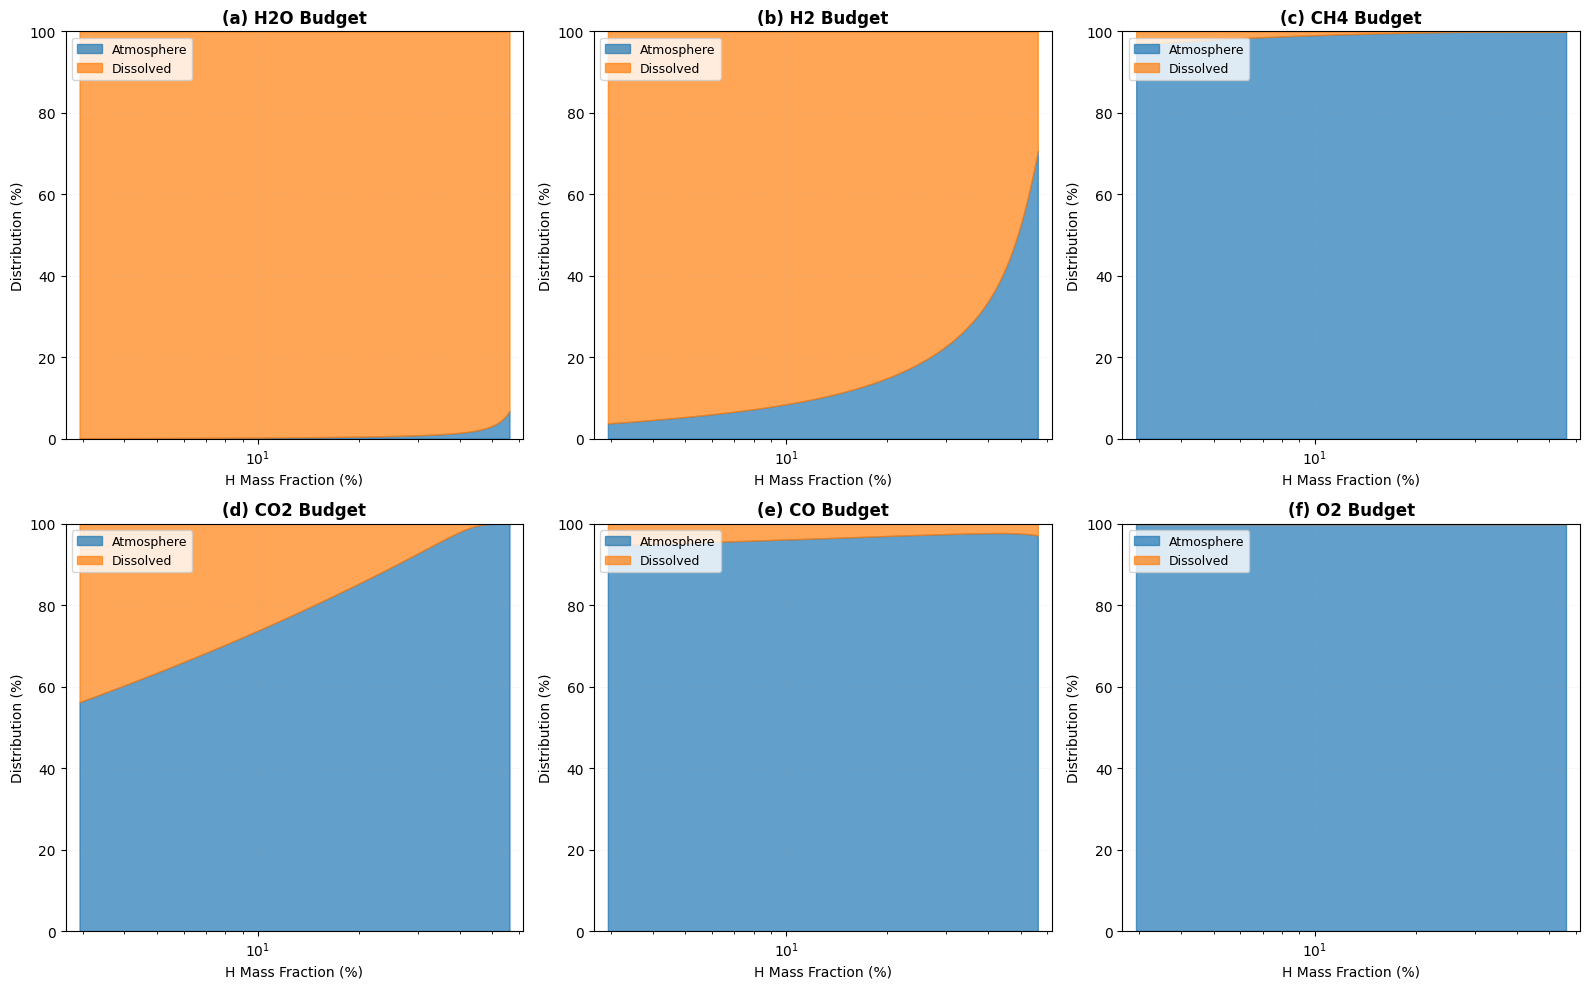

In [57]:
plot_molecular_budget_from_excel("sub_neptune_ideal_withsol_varyHF.xlsx")

Starting molecular abundance plotting...
Loaded H fraction from 'sub_neptune_ideal_withsol_varyHF.xlsx'. Range: 2.94e+00 to 5.62e+01 %
Successfully loaded and processed sheet 'H2O_g'
Successfully loaded and processed sheet 'H2_g'
Successfully loaded and processed sheet 'CH4_g'
Successfully loaded and processed sheet 'CO2_g'
Successfully loaded and processed sheet 'CO_g'
Successfully loaded and processed sheet 'O2_g'

Data prepared for plotting. Columns sorted by mean abundance:
['H2O', 'H2', 'CH4', 'CO', 'CO2', 'O2']
Using 6 colors from a qualitative colormap.

✓ Successfully saved: molecular_abundance_stacked_area_IDEAL.png


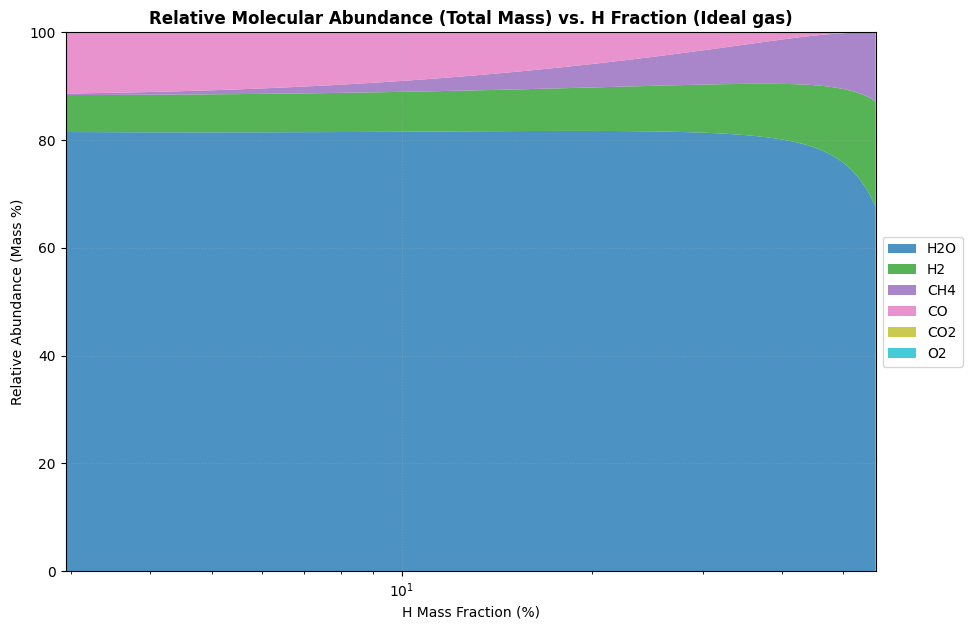


Plotting script finished.


In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors

print("Starting molecular abundance plotting...")

# --- 1. DEFINE YOUR FILE HERE ---
# Change this variable to the name of your Excel file
excel_file = "sub_neptune_ideal_withsol_varyHF.xlsx"

# --- 2. Load Data ---

# Define species to load
species_list = ['H2O_g', 'H2_g', 'CH4_g', 'CO2_g', 'CO_g', 'O2_g']

# Load H-fraction (x-axis) from the Excel sheet
try:
    df_H = pd.read_excel(excel_file, sheet_name='element_H')
    if 'atmosphere_ppmw' in df_H.columns:
        H_frac_percent = df_H['atmosphere_ppmw'].values / 1e4  # ppmw → %
        print(f"Loaded H fraction from '{excel_file}'. Range: {H_frac_percent.min():.2e} to {H_frac_percent.max():.2e} %")
    else:
        raise KeyError("'atmosphere_ppmw' column not found in 'element_H' sheet.")
except Exception as e:
    print(f"Error loading 'element_H' sheet from '{excel_file}': {e}")
    print("Cannot proceed without H fraction data.")
    exit() # Exit the script if H-fraction fails

# Load total mass for each species
species_total_mass = {}

for sp in species_list:
    try:
        # Read the sheet for the specific species
        df_sp = pd.read_excel(excel_file, sheet_name=sp)
        
        # Check for required columns
        if {'atmosphere_mass', 'dissolved_mass'}.issubset(df_sp.columns):
            atm_mass = df_sp['atmosphere_mass'].values
            dis_mass = df_sp['dissolved_mass'].values
            # Check for optional condensed_mass
            con_mass = df_sp['condensed_mass'].values if 'condensed_mass' in df_sp.columns else np.zeros_like(atm_mass)
            
            total_mass = atm_mass + dis_mass + con_mass
            species_total_mass[sp] = total_mass
            print(f"Successfully loaded and processed sheet '{sp}'")
        else:
            print(f"⚠️ Skipping {sp}: sheet found, but missing required mass columns.")
            
    except Exception as e:
        print(f"⚠️ Skipping {sp}: could not read sheet. Error: {e}")

# --- 3. Prepare Data for Plotting ---

if species_total_mass:
    # Create DataFrame of masses
    df_masses = pd.DataFrame(species_total_mass)
    
    # Calculate total mass at each step
    total_mass_all_species = df_masses.sum(axis=1)
    
    # Calculate percentage DataFrame
    # Avoid divide-by-zero if total mass is 0
    df_percent = df_masses.div(total_mass_all_species, axis=0).fillna(0) * 100
    
    # Use clean labels for columns
    df_percent.columns = [sp.replace('_g', '') for sp in df_masses.columns]

    # Sort columns by mean abundance for a cleaner stackplot
    sorted_columns = df_percent.mean().sort_values(ascending=False).index
    df_percent = df_percent[sorted_columns]

    print("\nData prepared for plotting. Columns sorted by mean abundance:")
    print(sorted_columns.tolist())

    # --- 4. Plot: 100% Stacked Area Chart ---
    try:
        fig, ax = plt.subplots(figsize=(12, 7))
        
        # Get colors from a qualitative colormap
        num_colors = len(df_percent.columns)
        if num_colors <= 10:
            colors = plt.cm.tab10(np.linspace(0, 1, num_colors))
        else:
            colors = plt.cm.tab20(np.linspace(0, 1, num_colors))
        
        print(f"Using {num_colors} colors from a qualitative colormap.")

        # Plot
        ax.stackplot(H_frac_percent, df_percent.values.T, 
                     labels=df_percent.columns, 
                     alpha=0.8, 
                     colors=colors)
        
        # Formatting
        ax.set_xscale('log')
        ax.set_xlim(H_frac_percent.min(), H_frac_percent.max())
        ax.set_ylim(0, 100)
        
        # Set labels without specifying fontsize (using defaults)
        ax.set_xlabel("H Mass Fraction (%)")
        ax.set_ylabel("Relative Abundance (Mass %)")
        
        # Set title with fontweight='bold' (fat) and default fontsize
        ax.set_title("Relative Molecular Abundance (Total Mass) vs. H Fraction (Ideal gas)", fontweight='bold')
        
        ax.grid(True, alpha=0.3, linestyle=':')
        
        # Legend outside the plot without specifying fontsize
        ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
        
        plt.subplots_adjust(right=0.8) # Make room for legend
        
        # Save the figure
        output_filename = "molecular_abundance_stacked_area_IDEAL.png"
        plt.savefig(output_filename, dpi=300, bbox_inches='tight')
        print(f"\n✓ Successfully saved: {output_filename}")
        
        # Show the plot
        plt.show()

    except Exception as e:
        print(f"\nError creating stacked area plot: {e}")

else:
    print("\nNo species data was loaded. Cannot create plots.")

print("\nPlotting script finished.")

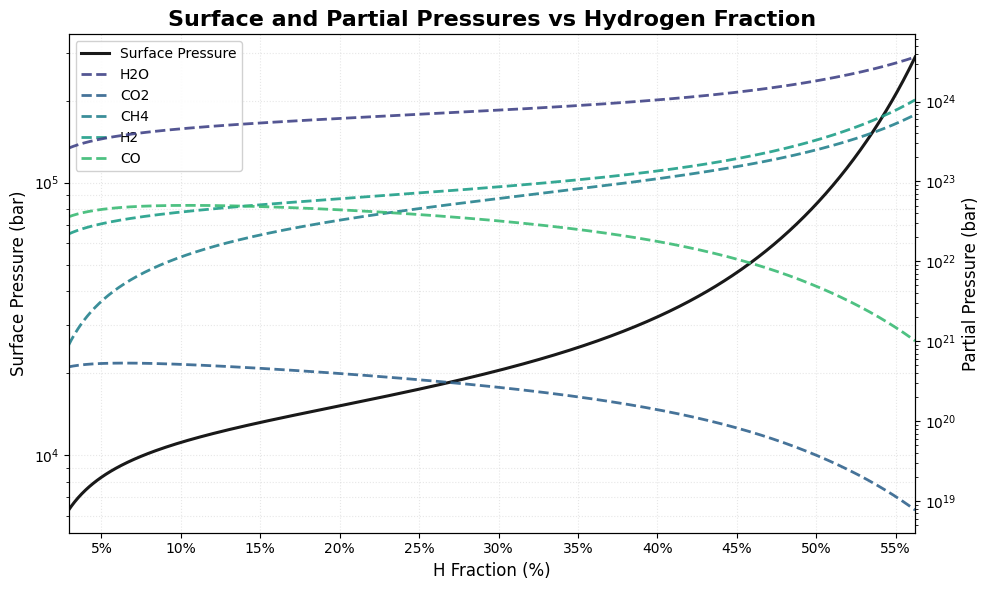

In [59]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# === File and species list ===
excel_file = "sub_neptune_ideal_withsol_varyHF.xlsx"
# Updated species list to include 'H_g'
species = ['H2O_g', 'CO2_g', 'CH4_g', 'H2_g', 'CO_g', 'H_g']

# === Load base data ===
df_H = pd.read_excel(excel_file, sheet_name='element_H')
df_atm = pd.read_excel(excel_file, sheet_name='atmosphere')

# Hydrogen fraction in %
x = df_H['atmosphere_ppmw'] / 1e4
P_surf = df_atm['pressure']

# Color palette
# Adjusted linspace to account for the new number of species
cmap = plt.cm.viridis(np.linspace(0.2, 0.8, len(species)))

# --- Single-panel figure ---
fig, ax = plt.subplots(figsize=(10, 6))

# Surface pressure
ax.plot(x, P_surf, '-', color='black', lw=2.2, alpha=0.9, label='Surface Pressure')

# Partial pressures
ax2 = ax.twinx()
for i, sp in enumerate(species):
    try:
        df_gas = pd.read_excel(excel_file, sheet_name=sp)
        if 'pressure' not in df_gas.columns:
            continue
        ax2.plot(x, df_gas['total_mass'], '--', lw=2.0, color=cmap[i],
                 label=sp.replace('_g','').upper(), alpha=0.9)
    except ValueError:
        # This will catch 'H_g' if the sheet doesn't exist
        continue

# --- Linear x-axis with clean, scientific ticks ---
x_min = np.floor(np.min(x)/5)*5      # nearest 5% below min
x_max = min(np.floor(np.max(x)/5)*5, 55)  # stop at 55% if max > 55
tick_values = list(range(int(x_min), int(x_max)+1, 5))

ax.set_xlabel('H Fraction (%)', fontsize=12)
ax.set_xticks(tick_values)
ax.set_xticklabels([f'{v}%' for v in tick_values], fontsize=10)
ax.set_xlim(np.min(x), np.max(x))

# --- Log y-axes ---
ax.set_yscale('log')
ax2.set_yscale('log')
ax.set_ylabel('Surface Pressure (bar)', color='black', fontsize=12)
ax2.set_ylabel('Partial Pressure (bar)', fontsize=12)

# --- Grid ---
ax.grid(True, linestyle=':', alpha=0.3, which='both')

# --- Legend ---
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines + lines2, labels + labels2, fontsize=10, loc='upper left', framealpha=0.9)

# --- Title ---
ax.set_title('Surface and Partial Pressures vs Hydrogen Fraction', fontsize=16, fontweight='bold')

# --- Tight layout & save ---
plt.tight_layout()
plt.savefig('partial_pressures_single_panel_linearX.png', dpi=300, bbox_inches='tight')
plt.show()


Creating molecular budget plot from: sub_neptune_ideal_withsol_varyHF.xlsx

✓ Successfully saved: sub_neptune_molecular_budget.png


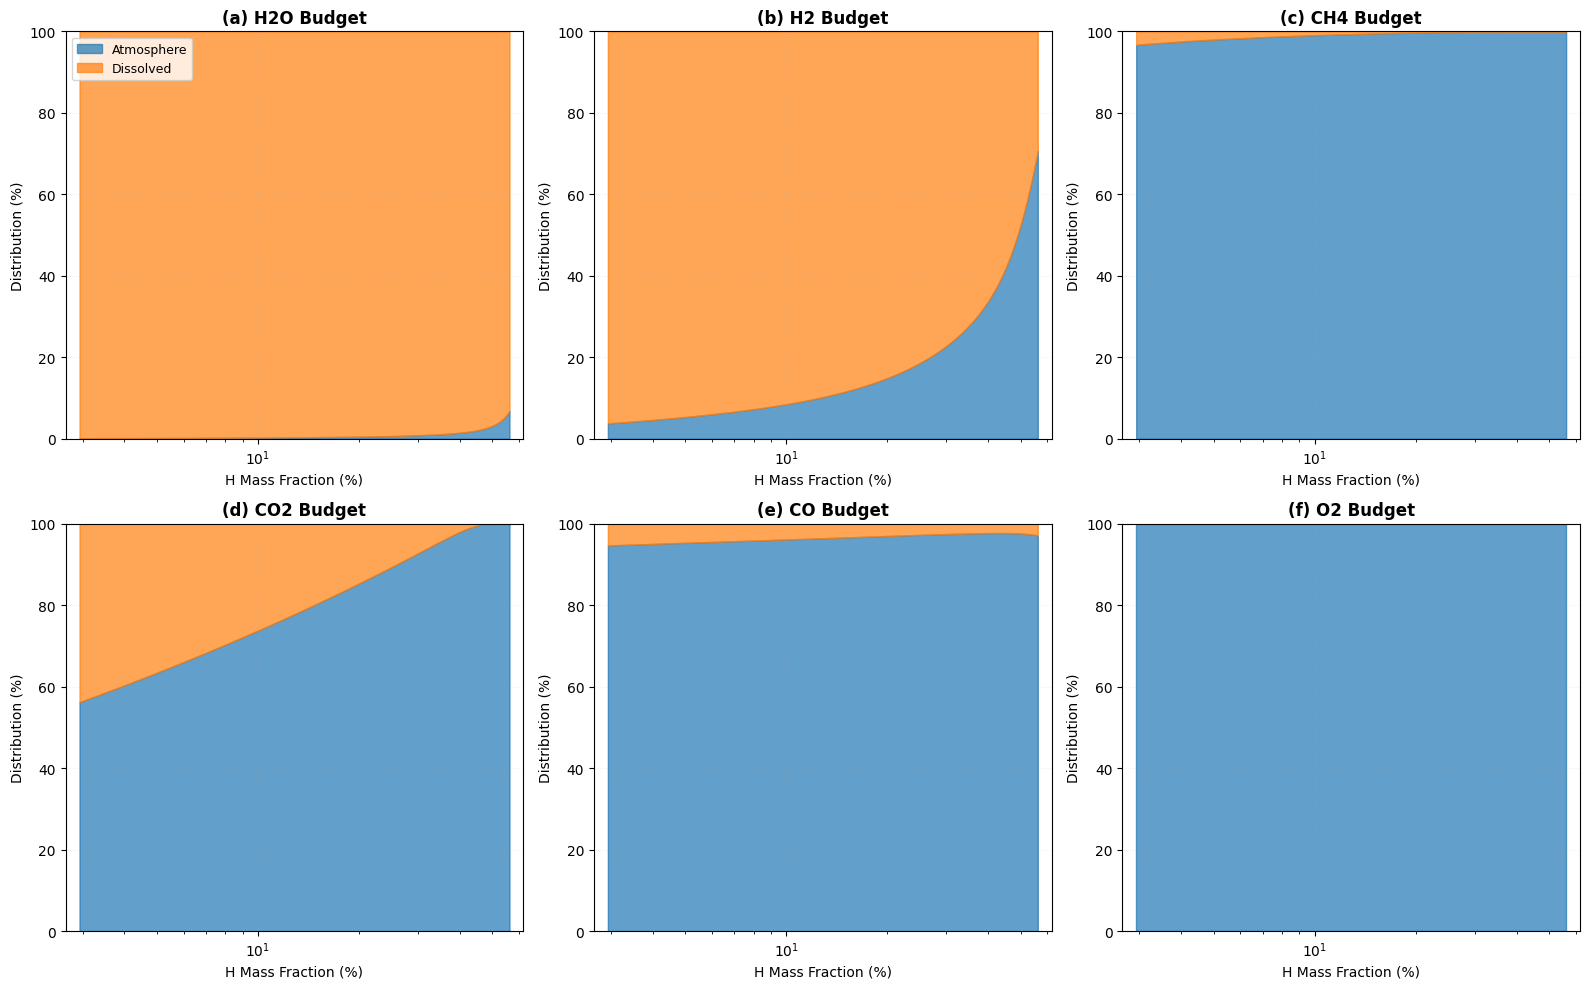

In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def plot_molecular_budget_from_excel(excel_file, species=None):
    """
    Plot molecular budget (atmosphere vs dissolved vs condensed)
    for each species from a real-gas Excel output file.
    """

    print("\n" + "="*70)
    print("Creating molecular budget plot from:", excel_file)
    print("="*70)
    
    # Default species to plot
    if species is None:
        species = ['H2O_g', 'H2_g', 'CH4_g', 'CO2_g', 'CO_g', 'O2_g']
    
    # --- 1) Read hydrogen fraction as x-axis
    df_H = pd.read_excel(excel_file, sheet_name='element_H')
    if 'atmosphere_ppmw' in df_H.columns:
        H_frac_percent = df_H['atmosphere_ppmw'].values / 1e4  # ppmw → %
    else:
        raise KeyError("The sheet 'element_H' must contain 'atmosphere_ppmw' for the H mass fraction axis.")
    
    # --- 2) Create figure
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    axes = axes.flatten()
    
    for i, sp in enumerate(species):
        ax = axes[i]
        
        try:
            df = pd.read_excel(excel_file, sheet_name=sp)
        except Exception as e:
            print(f"⚠️ Skipping {sp}: sheet not found.")
            continue
        
        # Ensure required columns exist
        if not {'atmosphere_mass', 'dissolved_mass'}.issubset(df.columns):
            print(f"⚠️ Skipping {sp}: missing mass columns.")
            continue
        
        atm_mass = df['atmosphere_mass'].values
        dis_mass = df['dissolved_mass'].values
        con_mass = df['condensed_mass'].values if 'condensed_mass' in df.columns else np.zeros_like(atm_mass)
        
        total_mass = atm_mass + dis_mass + con_mass
        total_mass[total_mass == 0] = np.nan  # avoid divide-by-zero
        
        # --- Stacked area plot in %
        ax.fill_between(H_frac_percent, 0, atm_mass/total_mass*100,  
                        label='Atmosphere', color='#1f77b4', alpha=0.7)
        ax.fill_between(H_frac_percent, atm_mass/total_mass*100,  
                        (atm_mass+dis_mass)/total_mass*100,  
                        label='Dissolved', color='#ff7f0e', alpha=0.7)
        
        # --- Formatting
        ax.set_xscale('log')
        
        # Get data min/max
        xmin_data = H_frac_percent.min()
        xmax_data = H_frac_percent.max()
        # Set x-limits with a 10% margin on each side (log-scaled)
        ax.set_xlim(xmin_data / 1.10, xmax_data * 1.10)
        
        ax.set_ylim(0, 100)
        ax.set_xlabel("H Mass Fraction (%)")
        ax.set_ylabel("Distribution (%)")
        
        # This line adds the title to each subplot
        ax.set_title(f"({chr(97+i)}) {sp.replace('_g','').upper()} Budget", fontweight='bold')
        
        ax.grid(True, alpha=0.3, linestyle=':', linewidth=0.5)
        
        # --- LEGEND REMOVED FROM HERE ---
        # The legend will be added globally *after* the loop.
    
    # Hide any unused subplots
    for j in range(len(species), len(axes)):
        fig.delaxes(axes[j])
        
    # --- Add a single, combined legend to the first plot ---
    all_handles = []
    all_labels = []
    # Iterate over all axes that actually have plots
    for ax_to_scan in axes[:len(species)]: 
        handles, labels = ax_to_scan.get_legend_handles_labels()
        for h, l in zip(handles, labels):
            if l not in all_labels: # Avoid duplicate labels
                all_labels.append(l)
                all_handles.append(h)
    
    # Add the master legend to the first subplot
    if all_handles and len(axes) > 0:
        axes[0].legend(all_handles, all_labels, loc='upper left', frameon=True, fontsize=9)
    
    plt.tight_layout()
    plt.savefig("sub_neptune_molecular_budget.png", dpi=300, bbox_inches='tight')
    print("\n✓ Successfully saved: sub_neptune_molecular_budget.png")
    print("="*70)
    plt.show()
plot_molecular_budget_from_excel("sub_neptune_ideal_withsol_varyHF.xlsx")


Starting molecular abundance plotting...
Loaded H fraction from 'sub_neptune_real_withsol_varyHF.xlsx'. Range: 2.02e+00 to 3.05e+01 %
Successfully loaded and processed sheet 'H2O_g'
Successfully loaded and processed sheet 'H2_g'
Successfully loaded and processed sheet 'CH4_g'
Successfully loaded and processed sheet 'CO2_g'
Successfully loaded and processed sheet 'CO_g'
Successfully loaded and processed sheet 'O2_g'

Data prepared for plotting. Columns sorted by mean abundance:
['H2O', 'H2', 'CH4', 'CO', 'CO2', 'O2']
Using 6 colors from a qualitative colormap.

✓ Successfully saved: molecular_abundance_stacked_area.png


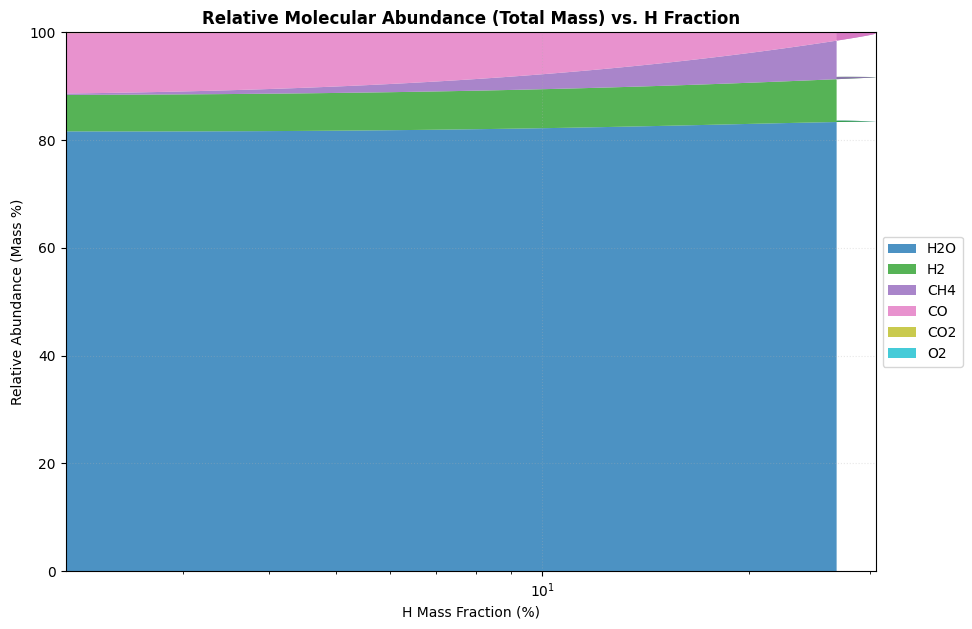


Plotting script finished.


In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors

print("Starting molecular abundance plotting...")

# --- 1. DEFINE YOUR FILE HERE ---
# Change this variable to the name of your Excel file
excel_file = "sub_neptune_real_withsol_varyHF.xlsx"

# --- 2. Load Data ---

# Define species to load
species_list = ['H2O_g', 'H2_g', 'CH4_g', 'CO2_g', 'CO_g', 'O2_g']

# Load H-fraction (x-axis) from the Excel sheet
try:
    df_H = pd.read_excel(excel_file, sheet_name='element_H')
    if 'atmosphere_ppmw' in df_H.columns:
        H_frac_percent = df_H['atmosphere_ppmw'].values / 1e4  # ppmw → %
        print(f"Loaded H fraction from '{excel_file}'. Range: {H_frac_percent.min():.2e} to {H_frac_percent.max():.2e} %")
    else:
        raise KeyError("'atmosphere_ppmw' column not found in 'element_H' sheet.")
except Exception as e:
    print(f"Error loading 'element_H' sheet from '{excel_file}': {e}")
    print("Cannot proceed without H fraction data.")
    exit() # Exit the script if H-fraction fails

# Load total mass for each species
species_total_mass = {}

for sp in species_list:
    try:
        # Read the sheet for the specific species
        df_sp = pd.read_excel(excel_file, sheet_name=sp)
        
        # Check for required columns
        if {'atmosphere_mass', 'dissolved_mass'}.issubset(df_sp.columns):
            atm_mass = df_sp['atmosphere_mass'].values
            dis_mass = df_sp['dissolved_mass'].values
            # Check for optional condensed_mass
            con_mass = df_sp['condensed_mass'].values if 'condensed_mass' in df_sp.columns else np.zeros_like(atm_mass)
            
            total_mass = atm_mass + dis_mass + con_mass
            species_total_mass[sp] = total_mass
            print(f"Successfully loaded and processed sheet '{sp}'")
        else:
            print(f"⚠️ Skipping {sp}: sheet found, but missing required mass columns.")
            
    except Exception as e:
        print(f"⚠️ Skipping {sp}: could not read sheet. Error: {e}")

# --- 3. Prepare Data for Plotting ---

if species_total_mass:
    # Create DataFrame of masses
    df_masses = pd.DataFrame(species_total_mass)
    
    # Calculate total mass at each step
    total_mass_all_species = df_masses.sum(axis=1)
    
    # Calculate percentage DataFrame
    # Avoid divide-by-zero if total mass is 0
    df_percent = df_masses.div(total_mass_all_species, axis=0).fillna(0) * 100
    
    # Use clean labels for columns
    df_percent.columns = [sp.replace('_g', '') for sp in df_masses.columns]

    # Sort columns by mean abundance for a cleaner stackplot
    sorted_columns = df_percent.mean().sort_values(ascending=False).index
    df_percent = df_percent[sorted_columns]

    print("\nData prepared for plotting. Columns sorted by mean abundance:")
    print(sorted_columns.tolist())

    # --- 4. Plot: 100% Stacked Area Chart ---
    try:
        fig, ax = plt.subplots(figsize=(12, 7))
        
        # Get colors from a qualitative colormap
        num_colors = len(df_percent.columns)
        if num_colors <= 10:
            colors = plt.cm.tab10(np.linspace(0, 1, num_colors))
        else:
            colors = plt.cm.tab20(np.linspace(0, 1, num_colors))
        
        print(f"Using {num_colors} colors from a qualitative colormap.")

        # Plot
        ax.stackplot(H_frac_percent, df_percent.values.T, 
                     labels=df_percent.columns, 
                     alpha=0.8, 
                     colors=colors)
        
        # Formatting
        ax.set_xscale('log')
        ax.set_xlim(H_frac_percent.min(), H_frac_percent.max())
        ax.set_ylim(0, 100)
        
        # Set labels without specifying fontsize (using defaults)
        ax.set_xlabel("H Mass Fraction (%)")
        ax.set_ylabel("Relative Abundance (Mass %)")
        
        # Set title with fontweight='bold' (fat) and default fontsize
        ax.set_title("Relative Molecular Abundance (Total Mass) vs. H Fraction", fontweight='bold')
        
        ax.grid(True, alpha=0.3, linestyle=':')
        
        # Legend outside the plot without specifying fontsize
        ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
        
        plt.subplots_adjust(right=0.8) # Make room for legend
        
        # Save the figure
        output_filename = "molecular_abundance_stacked_area.png"
        plt.savefig(output_filename, dpi=300, bbox_inches='tight')
        print(f"\n✓ Successfully saved: {output_filename}")
        
        # Show the plot
        plt.show()

    except Exception as e:
        print(f"\nError creating stacked area plot: {e}")

else:
    print("\nNo species data was loaded. Cannot create plots.")

print("\nPlotting script finished.")